In [1]:
!nvidia-smi

Fri Oct  9 06:51:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Prev

In [3]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0


In [2]:
# %load_ext cudf.pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# %%time
# path = '/content/drive/MyDrive/lending-club/accepted_2007_to_2018Q4.csv'
path = 'accepted_2007_to_2018Q4.csv'
df = pd.read_csv(path, low_memory=False)
df.shape

(2260701, 151)

In [6]:
# Memory check: GPU and RAM headroom after loading
# !nvidia-smi --query-gpu=memory.used,memory.total --format=csv
# !free -h

memory.used [MiB], memory.total [MiB]
6383 MiB, 15360 MiB
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.8Gi       4.6Gi       140Mi       6.7Gi        10Gi
Swap:             0B          0B          0B


prints a table showing which calls ran on the GPU and which fell back to the CPU.

In [2]:
# %%cudf.pandas.profile
# df.groupby('loan_status')['loan_amnt'].mean()

UsageError: Cell magic `%%cudf.pandas.profile` not found.


In [6]:
# Show all columns
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)

In [7]:
# Shape: rows and columns
df.shape

(2260701, 151)

In [8]:
# First rows
display(df.head(5))

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,leadman,10+ years,MORTGAGE,55000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,190xx,PA,5.91,0.0,Aug-2003,675.0,679.0,1.0,30.0,NaN,7.0,0.0,2765.0,29.7,13.0,w,0.00,0.00,4421.723917,4421.72,3600.00,821.72,0.0,0.0,0.0,Jan-2019,122.67,NaN,Mar-2019,564.0,560.0,0.0,30.0,1.0,Individual,NaN,NaN,NaN,0.0,722.0,144904.0,2.0,2.0,0.0,1.0,21.0,4981.0,36.0,3.0,3.0,722.0,34.0,9300.0,3.0,1.0,4.0,4.0,20701.0,1506.0,37.2,0.0,0.0,148.0,128.0,3.0,3.0,1.0,4.0,69.0,4.0,69.0,2.0,2.0,4.0,2.0,5.0,3.0,4.0,9.0,4.0,7.0,0.0,0.0,0.0,3.0,76.9,0.0,0.0,0.0,178050.0,7746.0,2400.0,13734.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,Engineer,10+ years,MORTGAGE,65000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,small_business,Business,577xx,SD,16.06,1.0,Dec-1999,715.0,719.0,4.0,6.0,NaN,22.0,0.0,21470.0,19.2,38.0,w,0.00,0.00,25679.660000,25679.66,24700.00,979.66,0.0,0.0,0.0,Jun-2016,926.35,NaN,Mar-2019,699.0,695.0,0.0,NaN,1.0,Individual,NaN,NaN,NaN,0.0,0.0,204396.0,1.0,1.0,0.0,1.0,19.0,18005.0,73.0,2.0,3.0,6472.0,29.0,111800.0,0.0,0.0,6.0,4.0,9733.0,57830.0,27.1,0.0,0.0,113.0,192.0,2.0,2.0,4.0,2.0,NaN,0.0,6.0,0.0,5.0,5.0,13.0,17.0,6.0,20.0,27.0,5.0,22.0,0.0,0.0,0.0,2.0,97.4,7.7,0.0,0.0,314017.0,39475.0,79300.0,24667.0,NaN,NaN,NaN,NaN,NaN,N

In [9]:
# Last rows
display(df.tail(5))

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
2260696,88985880,NaN,40000.0,40000.0,40000.0,60 months,10.49,859.56,B,B3,Vice President,9 years,MORTGAGE,227000.0,Verified,Oct-2016,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,NaN,907xx,CA,12.75,7.0,Feb-1995,705.0,709.0,1.0,9.0,NaN,5.0,0.0,8633.0,64.9,37.0,f,23252.59,23252.59,24903.93,24903.93,16747.41,8156.52,0.00,0.0,0.0,Mar-2019,859.56,Apr-2019,Mar-2019,724.0,720.0,0.0,10.0,1.0,Individual,NaN,NaN,NaN,0.0,0.0,28398.0,0.0,2.0,0.0,1.0,15.0,19765.0,46.0,0.0,0.0,5141.0,51.0,13300.0,3.0,0.0,2.0,2.0,5680.0,4070.0,66.9,0.0,0.0,154.0,258.0,33.0,15.0,3.0,41.0,9.0,1.0,9.0,6.0,2.0,3.0,2.0,15.0,9.0,3.0,23.0,3.0,5.0,0.0,0.0,7.0,0.0,75.7,50.0,0.0,0.0,55970.0,28398.0,12300.0,42670.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260697,88224441,NaN,24000.0,24000.0,24000.0,60 months,14.49,564.56,C,C4,Program Manager,6 years,RENT,110000.0,Not Verified,Oct-2016,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,334xx,FL,18.30,0.0,Jul-1999,660.0,664.0,0.0,67.0,72.0,10.0,1.0,17641.0,68.1,31.0,f,0.00,0.00,6755.40,6755.40,3521.91,3233.49,0.00,0.0,0.0,Oct-2017,564.56,NaN,Mar-2019,594.0,590.0,0.0,67.0,1.0,Individual,NaN,NaN,NaN,0.0,0.0,62426.0,0.0,2.0,0.0,2.0,20.0,44785.0,78.0,1.0,5.0,6172.0,73.0,25900.0,0.0,0.0,1.0,7.0,6243.0,4660.0,77.5,0.0,0.0,132.0,206.0,9.0,9.0,2.0,9.0,NaN,9.0,NaN,1.0,5.0,7.0,5.0,15.0,4.0,8.0,24.0,7.0,10.0,0.0,0.0,0.0,1.0,96.2,40.0,1.0,0.0,84664.0,62426.0,20700.0,58

In [10]:
# Types and non-null counts for all columns
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Data columns (total 151 columns):
 #    Column                                      Non-Null Count    Dtype  
---   ------                                      --------------    -----  
 0    id                                          2260701 non-null  str    
 1    member_id                                   0 non-null        float64
 2    loan_amnt                                   2260668 non-null  float64
 3    funded_amnt                                 2260668 non-null  float64
 4    funded_amnt_inv                             2260668 non-null  float64
 5    term                                        2260668 non-null  str    
 6    int_rate                                    2260668 non-null  float64
 7    installment                                 2260668 non-null  float64
 8    grade                                       2260668 non-null  str    
 9    sub_grade                                   2260668 non

In [11]:
# Summary of the numeric columns
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
member_id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,2260668.0,15046.931228,9190.245488,5.000000e+02,8000.0000,12900.000,20000.000000,4.000000e+04
funded_amnt,2260668.0,15041.664057,9188.413022,5.000000e+02,8000.0000,12875.000,20000.000000,4.000000e+04
funded_amnt_inv,2260668.0,15023.437745,9192.331679,0.000000e+00,8000.0000,12800.000,20000.000000,4.000000e+04
int_rate,2260668.0,13.092829,4.832138,5.310000e+00,9.4900,12.620,15.990000,3.099000e+01
installment,2260668.0,445.806823,267.173535,4.930000e+00,251.6500,377.990,593.320000,1.719830e+03
annual_inc,2260664.0,77992.428687,112696.199574,0.000000e+00,46000.0000,65000.000,93000.000000,1.100000e+08
dti,2258957.0,18.824196,14.183329,-1.000000e+00,11.8900,17.840,24.490000,9.990000e+02
delinq_2yrs,2260639.0,0.306879,0.867230,0.000000e+00,0.0000,0.000,0.000000,5.800000e+01
fico_range_low,2260668.0,698.588205,33.010376,6.100000e+02,675.0000,690.000,715.000000,8.450000e+02


In [12]:
# Does describe() match what should be numeric?
num_cols = df.select_dtypes(include='number').columns
text_cols = df.select_dtypes(exclude='number').columns

In [13]:
print('Total columns:  ', df.shape[1])
print('Numeric columns:', len(num_cols))
print('Text columns:   ', len(text_cols))
print('describe() rows:', df.describe().shape[1])
print()
print(list(text_cols))

Total columns:   151
Numeric columns: 113
Text columns:    38
describe() rows: 113

['id', 'term', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'earliest_cr_line', 'initial_list_status', 'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d', 'application_type', 'verification_status_joint', 'sec_app_earliest_cr_line', 'hardship_flag', 'hardship_type', 'hardship_reason', 'hardship_status', 'hardship_start_date', 'hardship_end_date', 'payment_plan_start_date', 'hardship_loan_status', 'disbursement_method', 'debt_settlement_flag', 'debt_settlement_flag_date', 'settlement_status', 'settlement_date']


In [14]:
# One sample value from each text column
display(df[text_cols].head(3).T)

,0,1,2
id,68407277,68355089,68341763
term,36 months,36 months,60 months
grade,C,C,B
sub_grade,C4,C1,B4
emp_title,leadman,Engineer,truck driver
emp_length,10+ years,10+ years,10+ years
home_ownership,MORTGAGE,MORTGAGE,MORTGAGE
verification_status,Not Verified,Not Verified,Not Verified
issue_d,Dec-2015,Dec-2015,Dec-2015
loan_status,Fully Paid,Fully Paid,Fully Paid


In [23]:
# Stage 1, Step 2 - Check 1: junk rows
# Every real loan has a loan amount, so rows without one are not loans
junk_rows = df[df['loan_amnt'].isna()]
print('Junk rows:', len(junk_rows))

# Which columns hold any value at all in these rows
print('Columns with a value:', junk_rows.columns[junk_rows.notna().any()].tolist())

# What these rows contain in the id column
display(junk_rows['id'])

Junk rows: 33
Columns with a value: ['id']


421095     Total amount funded in policy code 1: 6417608175
421096     Total amount funded in policy code 2: 1944088810
528961     Total amount funded in policy code 1: 1741781700
528962      Total amount funded in policy code 2: 564202131
651664     Total amount funded in policy code 1: 1791201400
651665      Total amount funded in policy code 2: 651669342
749520     Total amount funded in policy code 1: 1443412975
749521      Total amount funded in policy code 2: 511988838
877716     Total amount funded in policy code 1: 2063142975
877717      Total amount funded in policy code 2: 823319310
983169     Total amount funded in policy code 1: 1538432075
983170      Total amount funded in policy code 2: 608903141
1117058    Total amount funded in policy code 1: 2087217200
1117059     Total amount funded in policy code 2: 662815446
1352689    Total amount funded in policy code 1: 3503840175
1352690     Total amount funded in policy code 2: 873652739
1481103    Total amount funded in policy

In [24]:
# Stage 1, Step 2 - Check 2: columns that carry no information
# Count distinct values in every column (missing values are not counted)
n_unique = df.nunique()

# Columns that are completely empty or hold only one value
no_info = n_unique[n_unique <= 1]
print('Columns with one value or none:')
print(no_info)

# Pure identifiers: a different value on every row
print()
print('Real loans:', df['loan_amnt'].notna().sum())
print(n_unique[['id', 'url']])

Columns with one value or none:
member_id          0
policy_code        1
hardship_type      1
deferral_term      1
hardship_length    1
dtype: int64

Real loans: 2260668
id     2260701
url    2260668
dtype: int64


In [25]:
# Stage 1, Step 2 - Check 3: duplicates
# Repeated loan ids
print('Repeated ids:', df['id'].duplicated().sum())

# Fully identical rows once the identifier columns are left out
# (an ID column makes every row look unique, so the check could never fail with it in)
cols_no_id = df.columns.drop(['id', 'url'])
dup_mask = df.duplicated(subset=cols_no_id) & df['loan_amnt'].notna()
print('Identical loans (ignoring id and url):', dup_mask.sum())

Repeated ids: 0
Identical loans (ignoring id and url): 0


In [26]:
# Stage 1, Step 2 - Check 4: numbers and dates stored as text
# term: a number of months stored with the word "months"
print(df['term'].value_counts(dropna=False))
print()

# emp_length: years of employment stored as text
print(df['emp_length'].value_counts(dropna=False))
print()

# Date columns stored as text: distinct values, values not in Mon-YYYY form, and examples
date_cols = ['issue_d', 'earliest_cr_line', 'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d']
for col in date_cols:
    values = df[col].dropna()
    bad_format = (~values.str.match('^[A-Z][a-z]{2}-[0-9]{4}$')).sum()
    print(col, '| distinct:', values.nunique(), '| not Mon-YYYY:', bad_format, '| examples:', values.unique()[:5].tolist())

term
 36 months    1609754
 60 months     650914
NaN                33
Name: count, dtype: int64

emp_length
10+ years    748005
2 years      203677
< 1 year     189988
3 years      180753
1 year       148403
NaN          146940
5 years      139698
4 years      136605
6 years      102628
7 years       92695
8 years       91914
9 years       79395
Name: count, dtype: int64

issue_d | distinct: 139 | not Mon-YYYY: 0 | examples: ['Dec-2015', 'Nov-2015', 'Oct-2015', 'Sep-2015', 'Aug-2015']
earliest_cr_line | distinct: 754 | not Mon-YYYY: 0 | examples: ['Aug-2003', 'Dec-1999', 'Aug-2000', 'Sep-2008', 'Jun-1998']
last_pymnt_d | distinct: 136 | not Mon-YYYY: 0 | examples: ['Jan-2019', 'Jun-2016', 'Jun-2017', 'Feb-2019', 'Jul-2016']
next_pymnt_d | distinct: 106 | not Mon-YYYY: 0 | examples: ['Apr-2019', 'Mar-2019', 'Dec-2018', 'Sep-2018', 'May-2019']
last_credit_pull_d | distinct: 141 | not Mon-YYYY: 0 | examples: ['Mar-2019', 'Mar-2018', 'May-2017', 'Nov-2018', 'Sep-2018']


In [27]:
# Stage 1, Step 2 - Check 5: disguised missing values in text columns
# List every value of the small categorical columns to spot stand-ins for "missing"
cat_cols = ['home_ownership', 'verification_status', 'purpose', 'application_type']
for col in cat_cols:
    print(df[col].value_counts(dropna=False))
    print()

# Search every text column for common stand-in strings
placeholders = ['n/a', 'na', 'none', 'null', 'unknown', 'any', 'other', '?', '-', '']
for col in text_cols:
    hits = df[col].str.strip().str.lower().isin(placeholders).sum()
    if hits > 0:
        print(col, '| stand-in values:', hits)

home_ownership
MORTGAGE    1111450
RENT         894929
OWN          253057
ANY             996
OTHER           182
NONE             54
NaN              33
Name: count, dtype: int64

verification_status
Source Verified    886231
Not Verified       744806
Verified           629631
NaN                    33
Name: count, dtype: int64

purpose
debt_consolidation    1277877
credit_card            516971
home_improvement       150457
other                  139440
major_purchase          50445
medical                 27488
small_business          24689
car                     24013
vacation                15525
moving                  15403
house                   14136
wedding                  2355
renewable_energy         1445
educational               424
NaN                        33
Name: count, dtype: int64

application_type
Individual    2139958
Joint App      120710
NaN                33
Name: count, dtype: int64

emp_title | stand-in values: 19
home_ownership | stand-in values: 1232
d

In [28]:
# Stage 1, Step 2 - Check 6: disguised missing values and impossible numbers
# Exact counts of suspicious values in key columns
print('dti == -1:        ', (df['dti'] == -1).sum())
print('dti == 999:       ', (df['dti'] == 999).sum())
print('dti < 0:          ', (df['dti'] < 0).sum())
print('dti > 100:        ', (df['dti'] > 100).sum())
print('annual_inc == 0:  ', (df['annual_inc'] == 0).sum())
print('revol_util > 100: ', (df['revol_util'] > 100).sum())
print()

# Reported versus true missing rate for dti, once -1 and 999 are counted as missing
reported = df['dti'].isna().mean() * 100
true_rate = (df['dti'].isna() | df['dti'].isin([-1, 999])).mean() * 100
print('dti missing, reported: %.3f%% | true: %.3f%%' % (reported, true_rate))

# Scan every numeric column for negative values and placeholder-style values
sentinels = [-1, 999, 9999, 99999, 999999]
rows = {}
for col in num_cols:
    s = df[col]
    rows[col] = {'min': s.min(), 'max': s.max(), 'negatives': (s < 0).sum(), 'sentinels': s.isin(sentinels).sum()}
scan = pd.DataFrame(rows).T
display(scan[(scan['negatives'] > 0) | (scan['sentinels'] > 0)])

dti == -1:         2
dti == 999:        135
dti < 0:           2
dti > 100:         2561
annual_inc == 0:   1667
revol_util > 100:  7343

dti missing, reported: 0.077% | true: 0.083%


,min,max,negatives,sentinels
annual_inc,0.000000e+00,1.100000e+08,0.0,46.0
dti,-1.000000e+00,9.990000e+02,2.0,137.0
revol_bal,0.000000e+00,2.904836e+06,0.0,182.0
total_pymnt,0.000000e+00,6.329688e+04,0.0,2.0
total_pymnt_inv,0.000000e+00,6.329688e+04,0.0,2.0
total_rec_prncp,0.000000e+00,4.000000e+04,0.0,2.0
total_rec_int,0.000000e+00,2.819250e+04,0.0,8.0
total_rec_late_fee,-9.500000e-09,1.484340e+03,8.0,0.0
recoveries,0.000000e+00,3.985955e+04,0.0,1.0
collection_recovery_fee,0.000000e+00,7.174719e+03,0.0,1.0


## Stage 1, Step 2: What is broken?

### Problem list

| # | Column or issue | What is wrong | Rows affected | Proposed fix |
|---|---|---|---|---|
| 1 | Junk rows | Not loans; only `id` holds a value | 33 | Drop the rows |
| 2 | `id` | Stored as text because of the junk rows; pure identifier | all | Drop the column after removing junk rows |
| 3 | `url` | Pure identifier, one distinct value per loan | all | Drop the column |
| 4 | `member_id` | Completely empty | all | Drop the column |
| 5 | `policy_code` | One value only | all | Drop the column |
| 6 | `hardship_type`, `deferral_term`, `hardship_length` | One value only | all | Drop the columns |
| 7 | `term` | Number stored as text, with a leading space | all | Strip and convert to 36 or 60 |
| 8 | `emp_length` | Number stored as text (`10+ years`, `< 1 year`) | all | Convert to a number |
| 9 | `emp_length` | Missing | 146,907 loans (6.5%) | 5-30% band: impute carefully or keep as its own category |
| 10 | `issue_d`, `earliest_cr_line`, `last_pymnt_d`, `next_pymnt_d`, `last_credit_pull_d` | Dates stored as text, all in `Mon-YYYY` form | all | Convert to dates |
| 11 | `home_ownership` | Stand-in categories: ANY 996, OTHER 182, NONE 54 | 1,232 | Merge into one group or treat as missing |
| 12 | `dti` | Placeholder values: 999 (135 rows) and -1 (2 rows) | 137 | Treat as missing |
| 13 | `dti` | Above 100, implausible for a debt-to-income ratio | 2,561 | Judgment call: cap or treat as missing |
| 14 | `annual_inc` | Zero income | 1,667 | Judgment call: check whether these are joint applications |
| 15 | `annual_inc` | Maximum of $110 million | few | Entry error versus real extreme; handle in the outlier step |
| 16 | `revol_util` | Above 100% | 7,343 | Probably real (over the credit limit); keep or cap |
| 17 | `mo_sin_old_il_acct`, `mo_sin_old_rev_tl_op` | Maximum of 999 months (83 years), looks like a placeholder | 3 | Treat as missing |
| 18 | `total_rev_hi_lim`, `tot_hi_cred_lim` | Maximum of 9,999,999, looks like a cap | not counted | Check how many sit at the cap |

### What came back clean

- **Duplicates:** 0 repeated ids and 0 identical loans once `id` and `url` are ignored.
- **Date formats:** 0 values outside the `Mon-YYYY` form in all five date columns.
- **`verification_status`, `purpose`, `application_type`:** no stand-in values. The "other" in `purpose` (139,440 loans) is a real category.

In [29]:
# Open decision 1: are dti > 100 and zero income linked, and are they joint applications?
high_dti = df['dti'] > 100
zero_inc = df['annual_inc'] == 0
print('dti > 100:      ', high_dti.sum())
print('annual_inc == 0:', zero_inc.sum())
print('Both together:  ', (high_dti & zero_inc).sum())
print()

# What dti looks like for the zero-income loans
print('Zero-income loans with dti missing:', df.loc[zero_inc, 'dti'].isna().sum())
print('Zero-income loans with dti == 999: ', (df.loc[zero_inc, 'dti'] == 999).sum())
print()

# Application type for each group
print('Zero income, by application type:')
print(df.loc[zero_inc, 'application_type'].value_counts())
print()
print('dti > 100, by application type:')
print(df.loc[high_dti, 'application_type'].value_counts())
print()

# Income of the loans with dti > 100
print('Annual income where dti > 100:')
print(df.loc[high_dti, 'annual_inc'].describe())
print()

# Open decision 2: home_ownership small groups - which years they come from and how the loans ended
small = df['home_ownership'].isin(['ANY', 'OTHER', 'NONE'])
print(pd.crosstab(df.loc[small, 'home_ownership'], df.loc[small, 'issue_d'].str[-4:]))
print()
print(pd.crosstab(df.loc[small, 'home_ownership'], df.loc[small, 'loan_status']))

dti > 100:       2561
annual_inc == 0: 1667
Both together:   0

Zero-income loans with dti missing: 1659
Zero-income loans with dti == 999:  0

Zero income, by application type:
application_type
Joint App    1667
Name: count, dtype: int64

dti > 100, by application type:
application_type
Joint App    2561
Name: count, dtype: int64

Annual income where dti > 100:
count     2561.000000
mean     11758.631538
std       9160.604924
min         15.000000
25%       5000.000000
50%      10000.000000
75%      15000.000000
max      72000.000000
Name: annual_inc, dtype: float64

issue_d         2007  2008  2009  2010  2011  2012  2014  2015  2016  2017  \
home_ownership                                                               
ANY                0     0     0     0     0     0     1     2   110   395   
NONE               7     1     0     0     0    42     0     0     0     4   
OTHER              0    47    85     3     1    46     0     0     0     0   

issue_d         2018  
home_owners

Columns with no missing values: 38
Under 5% missing:               50
5% to 30% missing:              5
Over 30% missing:               58


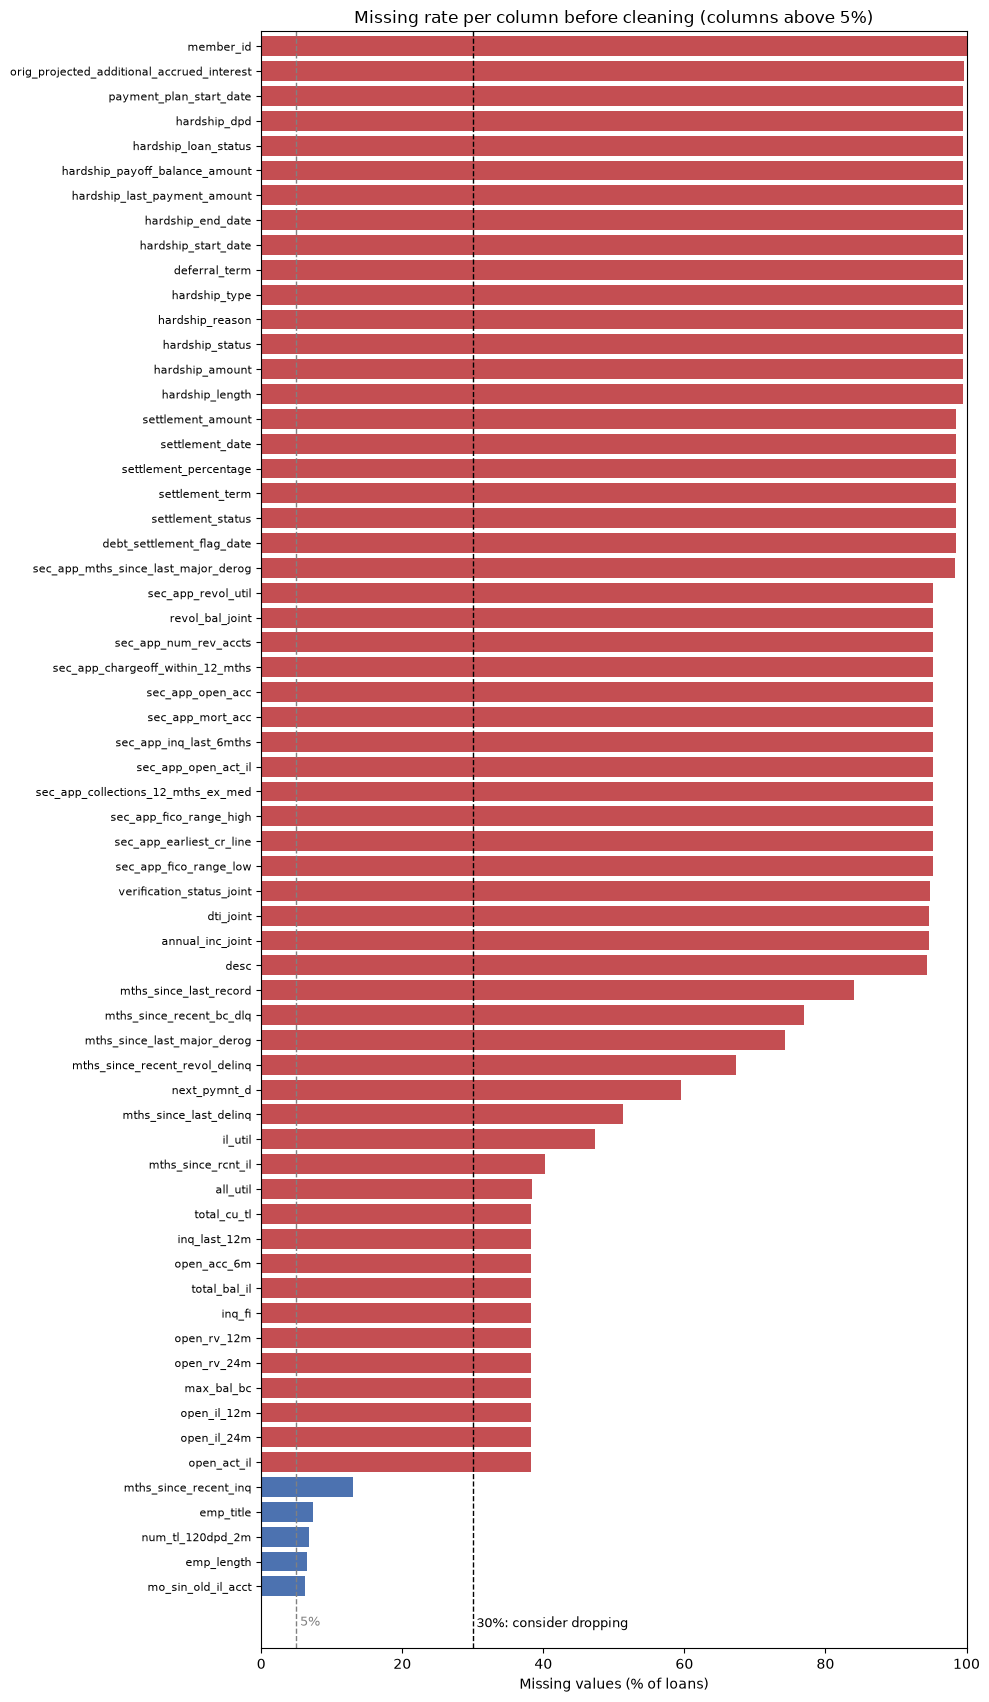

In [48]:
# Stage 1, Step 3 - Visual 1: missing rate per column (raw data, before cleaning)
# Question: which columns are too empty to use?
# Rates are computed on real loans only, so the 33 junk rows do not inflate them
real = df['loan_amnt'].notna()
missing_pct = df.isna()[real].mean() * 100

# How many columns fall in each of the lecture's bands
print('Columns with no missing values:', (missing_pct == 0).sum())
print('Under 5% missing:              ', ((missing_pct > 0) & (missing_pct < 5)).sum())
print('5% to 30% missing:             ', ((missing_pct >= 5) & (missing_pct <= 30)).sum())
print('Over 30% missing:              ', (missing_pct > 30).sum())

# Plot the columns above 5%, sorted, coloured by band
to_plot = missing_pct[missing_pct >= 5].sort_values()
colors = ['#c44e52' if v > 30 else '#4c72b0' for v in to_plot]

fig, ax = plt.subplots(figsize=(10, 0.24 * len(to_plot) + 2))
ax.barh(to_plot.index, to_plot.values, color=colors)
ax.axvline(5, color='grey', linestyle='--', linewidth=1)
ax.axvline(30, color='black', linestyle='--', linewidth=1)
ax.text(30.5, -1.2, '30%: consider dropping', fontsize=9, va='top')
ax.text(5.5, -1.2, '5%', fontsize=9, va='top', color='grey')
ax.set_xlim(0, 100)
ax.set_ylim(-2.5, len(to_plot) - 0.4)
ax.set_xlabel('Missing values (% of loans)')
ax.set_title('Missing rate per column before cleaning (columns above 5%)')
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

,count,min,max,mean
Other borrower and credit fields,5,6.2,13.1,8.0
Newer credit-bureau fields,14,38.3,47.3,39.1
Next payment date,1,59.5,59.5,59.5
Months since last delinquency or record,5,51.2,84.1,70.8
Second applicant and joint fields,16,94.7,98.4,95.3
Empty identifier and optional free text,2,94.4,100.0,97.2
Debt settlement fields,6,98.5,98.5,98.5
Hardship plan fields,14,99.5,99.6,99.5


open_acc_6m missing by issue year (%):
issue_d
2007    100.0
2008    100.0
2009    100.0
2010    100.0
2011    100.0
2012    100.0
2013    100.0
2014    100.0
2015     94.9
2016      0.0
2017      0.0
2018      0.0
Name: open_acc_6m, dtype: float64


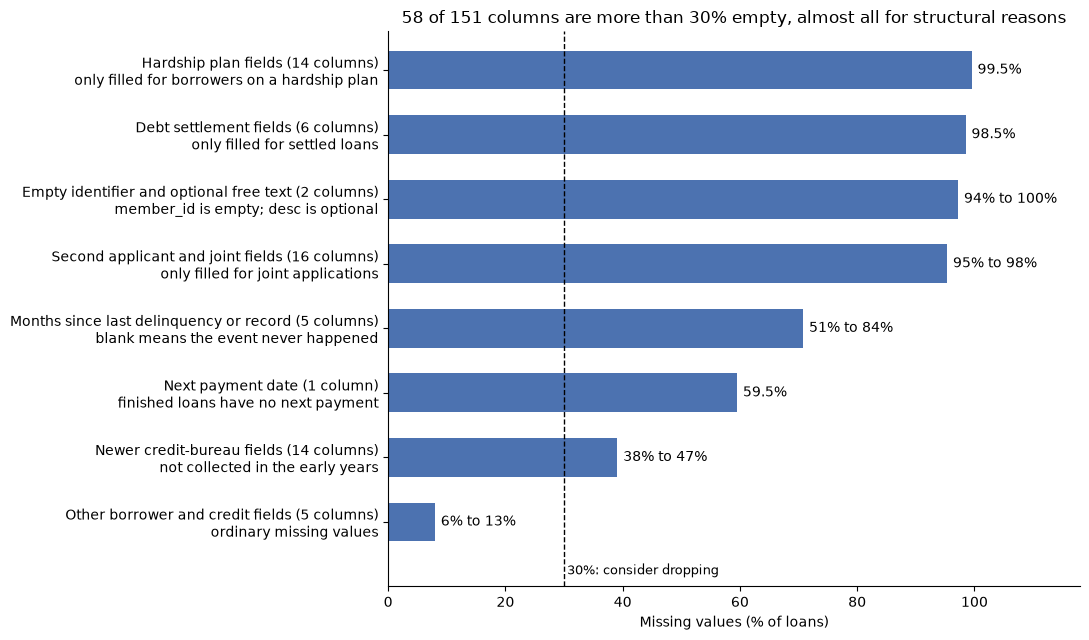

In [49]:
# Stage 1, Step 3 - Visual 1b: missing rate grouped by family of columns
# Question: why are the columns empty?
# Uses missing_pct from the cell above; each column above 5% is assigned to a family
def family(col):
    if col in ('member_id', 'desc'):
        return 'Empty identifier and optional free text'
    if col.startswith('hardship') or col in ('deferral_term', 'payment_plan_start_date', 'orig_projected_additional_accrued_interest'):
        return 'Hardship plan fields'
    if 'settlement' in col:
        return 'Debt settlement fields'
    if col.startswith('sec_app') or col.endswith('_joint'):
        return 'Second applicant and joint fields'
    if col in ('mths_since_last_delinq', 'mths_since_last_record', 'mths_since_last_major_derog',
               'mths_since_recent_bc_dlq', 'mths_since_recent_revol_delinq'):
        return 'Months since last delinquency or record'
    if col == 'next_pymnt_d':
        return 'Next payment date'
    if col in ('open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util',
               'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m'):
        return 'Newer credit-bureau fields'
    return 'Other borrower and credit fields'

reasons = {
    'Empty identifier and optional free text': 'member_id is empty; desc is optional',
    'Hardship plan fields': 'only filled for borrowers on a hardship plan',
    'Debt settlement fields': 'only filled for settled loans',
    'Second applicant and joint fields': 'only filled for joint applications',
    'Months since last delinquency or record': 'blank means the event never happened',
    'Next payment date': 'finished loans have no next payment',
    'Newer credit-bureau fields': 'not collected in the early years',
    'Other borrower and credit fields': 'ordinary missing values',
}

high = missing_pct[missing_pct >= 5]
grouped = high.groupby(high.index.map(family)).agg(['count', 'min', 'max', 'mean']).sort_values('mean')
display(grouped.round(1))

# Evidence for the "newer fields" label: missing rate of one of them by issue year
issue_year = df['issue_d'].str[-4:]
print('open_acc_6m missing by issue year (%):')
print(df['open_acc_6m'].isna().groupby(issue_year).mean().mul(100).round(1))

# One bar per family: bar length is the average missing rate, the label shows the range
labels = ['{} ({} {})\n{}'.format(name, int(row['count']), 'column' if row['count'] == 1 else 'columns', reasons[name])
          for name, row in grouped.iterrows()]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(labels, grouped['mean'], color='#4c72b0', height=0.6)
for i, (_, row) in enumerate(grouped.iterrows()):
    if row['max'] - row['min'] < 1:
        text = '{:.1f}%'.format(row['mean'])
    else:
        text = '{:.0f}% to {:.0f}%'.format(row['min'], row['max'])
    ax.text(row['mean'] + 1, i, text, va='center', fontsize=10)
ax.axvline(30, color='black', linestyle='--', linewidth=1)
ax.text(30.5, -0.75, '30%: consider dropping', fontsize=9, va='center')
ax.set_xlim(0, 118)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_ylim(-1, len(labels) - 0.4)
ax.set_xlabel('Missing values (% of loans)')
ax.set_title('{} of {} columns are more than 30% empty, almost all for structural reasons'.format((missing_pct > 30).sum(), len(missing_pct)), fontsize=12)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

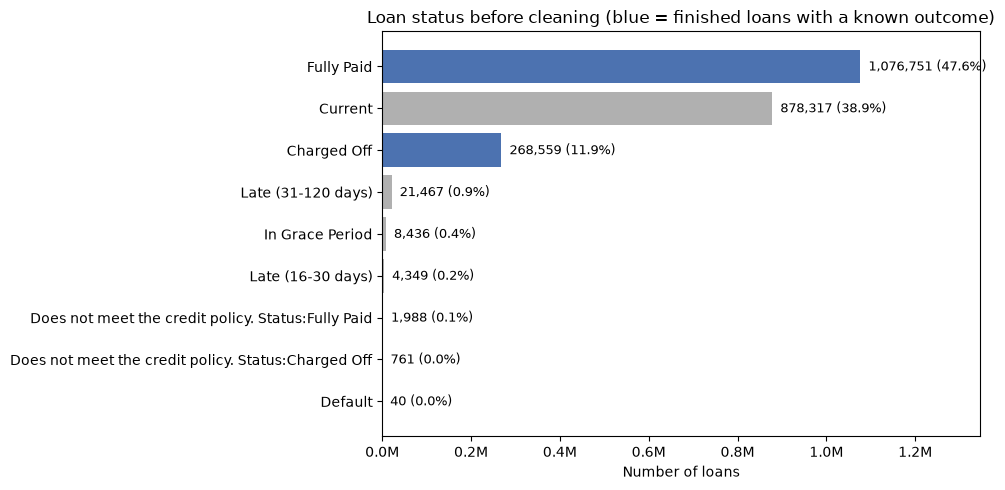

Finished loans (Fully Paid + Charged Off): 1345310
Charge-off rate among finished loans: 20.0%


In [104]:
# Stage 1, Step 3 - Visual 2: loan status distribution (raw data, before cleaning)
# Question: how did each loan end, and which loans have a known outcome?
status_counts = df['loan_status'].value_counts().sort_values()
status_pct = status_counts / status_counts.sum() * 100

# The two finished outcomes are highlighted; every other status has no final outcome yet
finished = ['Fully Paid', 'Charged Off']
colors = ['#4c72b0' if s in finished else '#b0b0b0' for s in status_counts.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(status_counts.index, status_counts.values, color=colors)
for i, (count, pct) in enumerate(zip(status_counts.values, status_pct.values)):
    ax.text(count, i, '  {:,} ({:.1f}%)'.format(count, pct), va='center', fontsize=9)
ax.set_xlim(0, status_counts.max() * 1.25)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, pos: '{:.1f}M'.format(v / 1e6)))
ax.set_xlabel('Number of loans')
ax.set_title('Loan status before cleaning (blue = finished loans with a known outcome)')
plt.tight_layout()
plt.show()

print('Finished loans (Fully Paid + Charged Off):', status_counts[finished].sum())
print('Charge-off rate among finished loans: {:.1f}%'.format(status_counts['Charged Off'] / status_counts[finished].sum() * 100))

In [105]:
# Stage 1, Step 4 - Define the target
# Keep only loans with a known final outcome; df stays untouched for the before/after comparison
from IPython.display import Markdown

finished = ['Fully Paid', 'Charged Off']
loans = df[df['loan_status'].isin(finished)].copy()

# Target column: 1 = Charged Off, 0 = Fully Paid
loans['charged_off'] = (loans['loan_status'] == 'Charged Off').astype(int)

# Check the result
display(Markdown('**Rows before and after keeping only finished loans (Fully Paid or Charged Off)**'))
print('Rows before (raw data, all statuses):', len(df))
print('Rows after (finished loans only):    ', len(loans))
print('Rows dropped:                        ', len(df) - len(loans))

display(Markdown('**Table 1. Target classes among the finished loans**<br>'
                 'charged_off is the target column: 0 = Fully Paid, 1 = Charged Off. '
                 'Percentages are out of the finished loans.'))
classes = loans['charged_off'].value_counts().sort_index().to_frame('loans')
classes['share of finished loans (%)'] = (classes['loans'] / len(loans) * 100).round(1)
classes.index = ['0 = Fully Paid', '1 = Charged Off']
classes.index.name = 'charged_off'
display(classes)

# What was dropped, by status
display(Markdown('**Table 2. Loans removed by the filter, by loan status (raw data)**<br>'
                 'These rows are in the raw data but not in the finished loans. '
                 'NaN = the 33 junk rows that are not loans.'))
dropped = df.loc[~df['loan_status'].isin(finished), 'loan_status'].value_counts(dropna=False).to_frame('loans removed')
display(dropped)

**Rows before and after keeping only finished loans (Fully Paid or Charged Off)**

Rows before (raw data, all statuses): 2260701
Rows after (finished loans only):     1345310
Rows dropped:                         915391


**Table 1. Target classes among the finished loans**<br>charged_off is the target column: 0 = Fully Paid, 1 = Charged Off. Percentages are out of the finished loans.

,loans,share of finished loans (%)
charged_off,,
0 = Fully Paid,1076751,80.0
1 = Charged Off,268559,20.0


**Table 2. Loans removed by the filter, by loan status (raw data)**<br>These rows are in the raw data but not in the finished loans. NaN = the 33 junk rows that are not loans.

,loans removed
loan_status,
Current,878317
Late (31-120 days),21467
In Grace Period,8436
Late (16-30 days),4349
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,40
NaN,33


# Current

In [106]:
# Stage 1, Step 4 - Recheck missing rates on the finished loans
# Compare with the raw rates from Step 3 (missing_pct)
missing_after = loans.isna().mean().drop('charged_off') * 100
compare = pd.DataFrame({'raw_pct': missing_pct, 'finished_pct': missing_after})
compare['change'] = compare['finished_pct'] - compare['raw_pct']

# Kind of column, so the tables can say which columns moved
# Starts from family() in the Step 3 grouped chart, then splits its catch-all group further
def column_kind(col):
    kind = family(col)
    if kind != 'Other borrower and credit fields':
        return kind
    if col in ('out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int',
               'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
               'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'pymnt_plan', 'hardship_flag',
               'debt_settlement_flag'):
        return 'Payment history after the loan was issued'
    if col in ('id', 'url', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade',
               'sub_grade', 'issue_d', 'loan_status', 'purpose', 'title', 'initial_list_status', 'application_type',
               'disbursement_method', 'policy_code'):
        return 'Loan details'
    if col in ('emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'zip_code',
               'addr_state', 'dti'):
        return 'Borrower details'
    if col in ('delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc',
               'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med', 'acc_now_delinq',
               'chargeoff_within_12_mths', 'delinq_amnt', 'pub_rec_bankruptcies', 'tax_liens'):
        return 'Core credit history'
    return 'Detailed credit-bureau fields'

compare['kind'] = [column_kind(col) for col in compare.index]

# Which missing-value band each column is in, before and after the filter
band_names = ['no missing values', 'under 5% missing', '5% to 30% missing', 'over 30% missing']
def band(pct):
    if pct == 0:
        return band_names[0]
    if pct < 5:
        return band_names[1]
    if pct <= 30:
        return band_names[2]
    return band_names[3]

compare['raw_band'] = compare['raw_pct'].map(band)
compare['finished_band'] = compare['finished_pct'].map(band)

# For each band: how many columns before and after, and which kinds of columns left it or joined it
left = {name: [] for name in band_names}
joined = {name: [] for name in band_names}
moved = compare[compare['raw_band'] != compare['finished_band']]
for (raw_band, finished_band), part in moved.groupby(['raw_band', 'finished_band']):
    for kind, n in part['kind'].value_counts().items():
        left[raw_band].append('{} ({}) moved to "{}"'.format(kind, n, finished_band))
        joined[finished_band].append('{} ({}) came from "{}"'.format(kind, n, raw_band))

band_table = pd.DataFrame({
    'raw data (number of columns)': compare['raw_band'].value_counts().reindex(band_names, fill_value=0),
    'finished loans (number of columns)': compare['finished_band'].value_counts().reindex(band_names, fill_value=0),
    'columns that left this band (kind and count)': ['; '.join(left[name]) or 'none' for name in band_names],
    'columns that joined this band (kind and count)': ['; '.join(joined[name]) or 'none' for name in band_names],
})
band_table.index.name = 'missing-value band'

display(Markdown('**Table 3. Number of columns in each missing-value band, before and after keeping only finished loans**<br>'
                 'Raw data = all real loans, any status (junk rows excluded). '
                 'Finished loans = Fully Paid or Charged Off only. '
                 'The last two fields say which kinds of columns changed band, how many, and where they went or came from.'))
with pd.option_context('display.max_colwidth', None):
    display(band_table)

# The 25 columns whose missing rate changed the most
# Descriptive names for display only; the data frame keeps its own column names
display(Markdown('**Table 4. The 25 columns whose missing rate changed most after keeping only finished loans**<br>'
                 'Each row is one column of the dataset. Change is in percentage points: '
                 'positive = emptier among finished loans, negative = fuller.'))
missing_labels = {'kind': 'kind of column',
                  'raw_pct': 'missing in raw data (%)',
                  'finished_pct': 'missing in finished loans (%)',
                  'change': 'change (percentage points)'}
order = compare['change'].abs().sort_values(ascending=False).index
display(compare.loc[order, ['kind', 'raw_pct', 'finished_pct', 'change']].head(25).round(1).rename(columns=missing_labels))

**Table 3. Number of columns in each missing-value band, before and after keeping only finished loans**<br>Raw data = all real loans, any status (junk rows excluded). Finished loans = Fully Paid or Charged Off only. The last two fields say which kinds of columns changed band, how many, and where they went or came from.

,raw data (number of columns),finished loans (number of columns),columns that left this band (kind and count),columns that joined this band (kind and count)
missing-value band,,,,
no missing values,38,46,none,"Core credit history (7) came from ""under 5% missing""; Borrower details (1) came from ""under 5% missing"""
under 5% missing,50,21,"Detailed credit-bureau fields (21) moved to ""5% to 30% missing""; Core credit history (7) moved to ""no missing values""; Borrower details (1) moved to ""no missing values""",none
5% to 30% missing,5,26,none,"Detailed credit-bureau fields (21) came from ""under 5% missing"""
over 30% missing,58,58,none,none


**Table 4. The 25 columns whose missing rate changed most after keeping only finished loans**<br>Each row is one column of the dataset. Change is in percentage points: positive = emptier among finished loans, negative = fuller.

,kind of column,missing in raw data (%),missing in finished loans (%),change (percentage points)
next_pymnt_d,Next payment date,59.5,100.0,40.5
total_cu_tl,Newer credit-bureau fields,38.3,60.0,21.7
inq_last_12m,Newer credit-bureau fields,38.3,60.0,21.7
open_acc_6m,Newer credit-bureau fields,38.3,60.0,21.7
total_bal_il,Newer credit-bureau fields,38.3,60.0,21.7
open_rv_12m,Newer credit-bureau fields,38.3,60.0,21.7
open_il_24m,Newer credit-bureau fields,38.3,60.0,21.7
open_act_il,Newer credit-bureau fields,38.3,60.0,21.7
open_rv_24m,Newer credit-bureau fields,38.3,60.0,21.7
inq_fi,Newer credit-bureau fields,38.3,60.0,21.7


In [107]:
# Stage 1, Step 4 - What the filter does year by year
# Recent loans that are already finished either defaulted early or were paid off early
from IPython.display import Markdown

all_year = df['issue_d'].str[-4:]
fin_year = loans['issue_d'].str[-4:]

by_year = pd.DataFrame({
    'all_loans': df.groupby(all_year)['loan_amnt'].count(),
    'finished': loans.groupby(fin_year)['loan_amnt'].count(),
    'charge_off_rate_pct': loans.groupby(fin_year)['charged_off'].mean() * 100,
    'fully_paid_rate_pct': (1 - loans.groupby(fin_year)['charged_off'].mean()) * 100,
})
by_year['finished_pct'] = by_year['finished'] / by_year['all_loans'] * 100
# Descriptive names for display only; the data frame keeps its own column names
labels = {'finished_pct': 'finished (%)',
          'charge_off_rate_pct': 'charged off (% out of finished)',
          'fully_paid_rate_pct': 'fully paid (% out of finished)'}
display(Markdown('**Table 5. Loans by issue year: how many are finished, and how the finished loans ended**<br>'
                 'all_loans = every loan issued that year, any status (raw data). '
                 'finished = loans that are Fully Paid or Charged Off. '
                 'finished (%) = finished loans out of all loans. '
                 'The last two columns are percentages of the finished loans only.'))
display(by_year[['all_loans', 'finished', 'finished_pct', 'charge_off_rate_pct', 'fully_paid_rate_pct']].round(1).rename(columns=labels))

# The same two rates split by loan term (36 or 60 months)
by_term = pd.DataFrame({
    'finished_pct': loans.groupby([fin_year, 'term']).size() / df.groupby([all_year, 'term']).size() * 100,
    'charge_off_rate_pct': loans.groupby([fin_year, 'term'])['charged_off'].mean() * 100,
    'fully_paid_rate_pct': (1 - loans.groupby([fin_year, 'term'])['charged_off'].mean()) * 100,
})
display(Markdown('**Table 6. Finished, charged-off and fully-paid rates by issue year and loan term (36 or 60 months)**<br>'
                 'finished (%) = finished loans out of all loans of that year and term (raw data). '
                 'Charged off and fully paid are percentages of the finished loans of that year and term. '
                 'NaN = no loans of that term were issued that year.'))
display(by_term.round(1).rename(columns=labels).unstack('term'))

**Table 5. Loans by issue year: how many are finished, and how the finished loans ended**<br>all_loans = every loan issued that year, any status (raw data). finished = loans that are Fully Paid or Charged Off. finished (%) = finished loans out of all loans. The last two columns are percentages of the finished loans only.

,all_loans,finished,finished (%),charged off (% out of finished),fully paid (% out of finished)
issue_d,,,,,
2007,603,251,41.6,17.9,82.1
2008,2393,1562,65.3,15.8,84.2
2009,5281,4716,89.3,12.6,87.4
2010,12537,11536,92.0,12.9,87.1
2011,21721,21721,100.0,15.2,84.8
2012,53367,53367,100.0,16.2,83.8
2013,134814,134804,100.0,15.6,84.4
2014,235629,223102,94.7,18.4,81.6
2015,421095,375545,89.2,20.2,79.8


**Table 6. Finished, charged-off and fully-paid rates by issue year and loan term (36 or 60 months)**<br>finished (%) = finished loans out of all loans of that year and term (raw data). Charged off and fully paid are percentages of the finished loans of that year and term. NaN = no loans of that term were issued that year.

finished (%)           charged off (% out of finished)            \
term       36 months 60 months                       36 months 60 months   
issue_d                                                                    
2007            41.6       NaN                            17.9       NaN   
2008            65.3       NaN                            15.8       NaN   
2009            89.3       NaN                            12.6       NaN   
2010            92.5      90.8                             9.9      21.0   
2011           100.0     100.0                            10.6      23.6   
2012           100.0     100.0                            13.6      27.7   
2013           100.0     100.0                            12.3      25.1   
2014           100.0      82.9                            13.7      31.1   
2015            99.9      67.1                            14.9      36.4   
2016            71.8      54.8                            19.8      36.4   
2017            40.1      33.1                            20.0      32.9   
2018            12.0      10.0                            13.2      22.6   

        fully paid (% out of finished)            
term                         36 months 60 months  
issue_d                                           
2007                              82.1       NaN  
2008                              84.2       NaN  
2009                              87.4       NaN  
2010                              90.1      79.0  
2011                              89.4      76.4  
2012                              86.4      72.3  
2013                              87.7      74.9  
2014                              86.3      68.9  
2015                              85.1      63.6  
2016                              80.2      63.6  
2017                              80.0      67.1  
2018                              86.8      77.4

In [108]:
# Stage 1, Step 4 - Keep only loans old enough to have finished
# Rule: a loan is kept only if its full term (36 or 60 months) had passed by the time the data was captured.
# Recent loans that are already finished ended early, so they are not a fair sample (see Tables 5 and 6).

# When the data was captured: the latest payment date anywhere in the raw data
snapshot = pd.to_datetime(df['last_pymnt_d'], format='%b-%Y').max()

# Months between each loan's issue date and the capture date, compared with its term
issue_date = pd.to_datetime(loans['issue_d'], format='%b-%Y')
term_months = loans['term'].str.strip().str[:2].astype(int)
months_elapsed = (snapshot.year - issue_date.dt.year) * 12 + (snapshot.month - issue_date.dt.month)
mature = months_elapsed >= term_months

# Summary by loan term, before the rows are removed
summary = pd.DataFrame({
    'finished loans before the rule': loans.groupby('term').size(),
    'loans kept': loans[mature].groupby('term').size(),
    'last issue month kept': issue_date[mature].groupby(loans['term']).max().dt.strftime('%b-%Y'),
    'charged off before the rule (%)': loans.groupby('term')['charged_off'].mean() * 100,
    'charged off after the rule (%)': loans[mature].groupby('term')['charged_off'].mean() * 100,
})
summary.insert(2, 'loans removed', summary['finished loans before the rule'] - summary['loans kept'])
rate_before = loans['charged_off'].mean() * 100
rows_before = len(loans)

# Apply the rule: loans now holds only loans old enough to have finished
loans = loans[mature].copy()

display(Markdown('**Rows before and after keeping only loans old enough to have finished**'))
print('Data captured (latest payment date):', snapshot.strftime('%B %Y'))
print('Finished loans before the rule:     ', rows_before)
print('Loans kept:                         ', len(loans))
print('Loans removed:                      ', rows_before - len(loans))
print('Charge-off rate before: {:.1f}%   after: {:.1f}%'.format(rate_before, loans['charged_off'].mean() * 100))

display(Markdown('**Table 7. Effect of the rule by loan term**<br>'
                 'A loan is kept only if its full term had passed by the capture date. '
                 'Charge-off percentages are out of the finished loans of that term.'))
display(summary.round(1))

display(Markdown('**Table 8. Target classes after the rule**<br>'
                 'charged_off is the target column: 0 = Fully Paid, 1 = Charged Off. Percentages are out of the loans kept.'))
classes = loans['charged_off'].value_counts().sort_index().to_frame('loans')
classes['share of loans kept (%)'] = (classes['loans'] / len(loans) * 100).round(1)
classes.index = ['0 = Fully Paid', '1 = Charged Off']
classes.index.name = 'charged_off'
display(classes)

**Rows before and after keeping only loans old enough to have finished**

Data captured (latest payment date): March 2019
Finished loans before the rule:      1345310
Loans kept:                          776276
Loans removed:                       569034
Charge-off rate before: 20.0%   after: 15.2%


**Table 7. Effect of the rule by loan term**<br>A loan is kept only if its full term had passed by the capture date. Charge-off percentages are out of the finished loans of that term.

,finished loans before the rule,loans kept,loans removed,last issue month kept,charged off before the rule (%),charged off after the rule (%)
term,,,,,,
36 months,1020743,708368,312375,Mar-2016,16.0,14.2
60 months,324567,67908,256659,Mar-2014,32.4,25.3


**Table 8. Target classes after the rule**<br>charged_off is the target column: 0 = Fully Paid, 1 = Charged Off. Percentages are out of the loans kept.

,loans,share of loans kept (%)
charged_off,,
0 = Fully Paid,658666,84.8
1 = Charged Off,117610,15.2


In [109]:
# Stage 1, Step 5 - Free-text and location columns (decision D6)
# emp_title and title are hand-typed text; zip_code and addr_state are location codes.
# Decision: drop emp_title and title, keep zip_code and addr_state.
text_decisions = {
    'emp_title': 'drop: hand-typed job titles, almost all unique',
    'title': 'drop: near-copy of purpose plus hand-typed text',
    'zip_code': 'keep: three-digit ZIP area, possible map',
    'addr_state': 'keep: clean two-letter state code',
}

# Evidence for the decision, taken before anything is dropped
if 'emp_title' in loans.columns:
    rows = {}
    for col in text_decisions:
        counts = loans[col].value_counts()
        rows[col] = {
            'distinct values': len(counts),
            'values that appear once': int((counts == 1).sum()),
            'missing (%)': round(loans[col].isna().mean() * 100, 1),
            'most common value': '{} ({:,})'.format(counts.index[0], counts.iloc[0]),
            'decision': text_decisions[col],
        }
    text_summary = pd.DataFrame(rows).T
    text_summary.index.name = 'column'

display(Markdown('**Table 9. Free-text and location columns: what they hold and what we do with them**<br>'
                 'Measured on the loans kept after Step 4. A column with a huge number of distinct values, '
                 'most of them appearing once, cannot be used as a category.'))
with pd.option_context('display.max_colwidth', None):
    display(text_summary)

# Drop the two free-text columns; dropped keeps a record of every column removed in Step 5 and why
dropped = {}
for col in ('emp_title', 'title'):
    dropped[col] = text_decisions[col].replace('drop: ', '')
print('Columns before:', loans.shape[1])
loans = loans.drop(columns=list(dropped), errors='ignore')
print('Columns after: ', loans.shape[1])
print('Dropped:', list(dropped))

**Table 9. Free-text and location columns: what they hold and what we do with them**<br>Measured on the loans kept after Step 4. A column with a huge number of distinct values, most of them appearing once, cannot be used as a category.

,distinct values,values that appear once,missing (%),most common value,decision
column,,,,,
emp_title,272023,224000,6.6,"Teacher (11,258)","drop: hand-typed job titles, almost all unique"
title,61678,52638,0.9,"Debt consolidation (330,469)",drop: near-copy of purpose plus hand-typed text
zip_code,924,32,0.0,"945xx (8,859)","keep: three-digit ZIP area, possible map"
addr_state,51,0,0.0,"CA (118,049)",keep: clean two-letter state code


Columns before: 152
Columns after:  150
Dropped: ['emp_title', 'title']


In [110]:
# Stage 1, Step 5 - Combined income and debt-to-income for joint applications (decision D3)
# A joint application was judged on the joint figures, so use those for joint loans and the individual ones otherwise.
# This has to run before the joint columns are dropped for being mostly empty.
if 'annual_inc_joint' in loans.columns:
    is_joint = loans['application_type'] == 'Joint App'
    use_joint_inc = is_joint & loans['annual_inc_joint'].notna()
    use_joint_dti = is_joint & loans['dti_joint'].notna()
    loans['annual_inc_combined'] = loans['annual_inc'].where(~use_joint_inc, loans['annual_inc_joint'])
    loans['dti_combined'] = loans['dti'].where(~use_joint_dti, loans['dti_joint'])

    joint_summary = pd.DataFrame(
        {'loans': [len(loans), int(is_joint.sum()), int(use_joint_inc.sum()), int(use_joint_dti.sum())]},
        index=['all loans kept', 'joint applications', 'income taken from the joint figure', 'dti taken from the joint figure'])
    joint_summary['share of loans kept (%)'] = (joint_summary['loans'] / len(loans) * 100).round(2)

    joint_check = pd.DataFrame({
        'individual figures': [int((loans['annual_inc'] == 0).sum()), int(loans['dti'].isna().sum()), int((loans['dti'] > 100).sum())],
        'combined figures': [int((loans['annual_inc_combined'] == 0).sum()), int(loans['dti_combined'].isna().sum()), int((loans['dti_combined'] > 100).sum())],
    }, index=['loans with an income of zero', 'loans with dti missing', 'loans with dti above 100'])

display(Markdown('**Table 10. Joint applications among the loans kept, and where the joint figures are used**<br>'
                 'annual_inc_combined and dti_combined take the joint value for joint applications and the individual value otherwise.'))
display(joint_summary)
display(Markdown('**Table 11. The problem values before and after combining**<br>'
                 'Number of loans with each problem, using the individual figures and using the combined figures.'))
display(joint_check)

**Table 10. Joint applications among the loans kept, and where the joint figures are used**<br>annual_inc_combined and dti_combined take the joint value for joint applications and the individual value otherwise.

,loans,share of loans kept (%)
all loans kept,776276,100.00
joint applications,1627,0.21
income taken from the joint figure,1627,0.21
dti taken from the joint figure,1624,0.21


**Table 11. The problem values before and after combining**<br>Number of loans with each problem, using the individual figures and using the combined figures.

,individual figures,combined figures
loans with an income of zero,8,0
loans with dti missing,9,0
loans with dti above 100,22,0


In [111]:
# Stage 1, Step 5 - Drop columns that are more than 30% empty (decision D7)
# Missing rates are recalculated on the loans kept, because they changed again after the loan-age rule.
# This includes the five "months since last delinquency or record" columns.
missing_now = loans.isna().mean() * 100
over30 = missing_now[missing_now > 30].sort_values(ascending=False)
columns_before = loans.shape[1]

if len(over30) > 0:
    over30_table = pd.DataFrame({'kind': [column_kind(col) for col in over30.index], 'missing': over30})
    over30_summary = over30_table.groupby('kind')['missing'].agg(['count', 'min', 'max']).sort_values('max', ascending=False).round(1)
    over30_summary.columns = ['columns dropped', 'lowest missing rate (%)', 'highest missing rate (%)']
    over30_summary.index.name = 'kind of column'
    for col, pct in over30.items():
        dropped[col] = 'more than 30% empty ({:.1f}%)'.format(pct)
    loans = loans.drop(columns=list(over30.index))

display(Markdown('**Table 12. Columns dropped for being more than 30% empty, by kind of column**<br>'
                 'Missing rates are measured on the loans kept after Step 4.'))
display(over30_summary)
print('Columns before:', columns_before)
print('Columns after: ', loans.shape[1])
print('Dropped in this cell:', columns_before - loans.shape[1])

**Table 12. Columns dropped for being more than 30% empty, by kind of column**<br>Missing rates are measured on the loans kept after Step 4.

,columns dropped,lowest missing rate (%),highest missing rate (%)
kind of column,,,
Empty identifier and optional free text,2,84.1,100.0
Next payment date,1,100.0,100.0
Second applicant and joint fields,16,99.8,100.0
Hardship plan fields,14,99.8,99.8
Debt settlement fields,6,98.3,98.3
Newer credit-bureau fields,14,86.5,88.4
Months since last delinquency or record,5,51.3,84.2


Columns before: 152
Columns after:  94
Dropped in this cell: 58


In [112]:
# Stage 1, Step 5 - Drop leakage columns (decision D8)
# These were recorded after the loan was issued, so they would not be known when deciding on an application.
leakage = {
    'out_prncp': 'principal still owed', 'out_prncp_inv': 'principal still owed to investors',
    'total_pymnt': 'payments received', 'total_pymnt_inv': 'payments received by investors',
    'total_rec_prncp': 'principal repaid', 'total_rec_int': 'interest repaid', 'total_rec_late_fee': 'late fees paid',
    'recoveries': 'money recovered after charge-off', 'collection_recovery_fee': 'collection fee after charge-off',
    'last_pymnt_d': 'date of last payment', 'last_pymnt_amnt': 'amount of last payment',
    'next_pymnt_d': 'date of next payment', 'last_credit_pull_d': 'date of latest credit check',
    'last_fico_range_high': 'latest FICO score', 'last_fico_range_low': 'latest FICO score',
    'pymnt_plan': 'payment plan set up after issue', 'hardship_flag': 'hardship plan after issue',
    'debt_settlement_flag': 'debt settlement after issue',
}
leak_present = [col for col in leakage if col in loans.columns]
columns_before = loans.shape[1]

# Evidence, taken before the columns are dropped: these columns give the outcome away
if 'recoveries' in loans.columns:
    by_outcome = loans.groupby('charged_off')
    leak_evidence = pd.DataFrame({
        'loans with money recovered after charge-off (%)': by_outcome['recoveries'].apply(lambda s: (s > 0).mean() * 100),
        'average share of the loan amount repaid (%)': (loans['total_rec_prncp'] / loans['loan_amnt']).groupby(loans['charged_off']).mean() * 100,
        'average latest FICO score (after issue)': by_outcome['last_fico_range_high'].mean(),
        'average FICO score at application': by_outcome['fico_range_high'].mean(),
    }).round(1)
    leak_evidence.index = ['0 = Fully Paid', '1 = Charged Off']
    leak_evidence.index.name = 'charged_off'

for col in leak_present:
    dropped[col] = 'leakage: ' + leakage[col] + ', recorded after the loan was issued'
loans = loans.drop(columns=leak_present)

display(Markdown('**Table 13. Why these columns are leakage: they differ by outcome because they were recorded after it**<br>'
                 'The FICO score at application is shown for contrast; it was known before the loan was issued and is kept.'))
with pd.option_context('display.max_colwidth', None):
    display(leak_evidence.T)
print('Columns before:', columns_before)
print('Columns after: ', loans.shape[1])
print('Dropped in this cell:', leak_present)
print('Total columns dropped so far in Step 5:', len(dropped))

**Table 13. Why these columns are leakage: they differ by outcome because they were recorded after it**<br>The FICO score at application is shown for contrast; it was known before the loan was issued and is kept.

charged_off,0 = Fully Paid,1 = Charged Off
loans with money recovered after charge-off (%),0.0,78.7
average share of the loan amount repaid (%),99.9,39.8
average latest FICO score (after issue),700.9,573.9
average FICO score at application,701.1,690.7


Columns before: 94
Columns after:  77
Dropped in this cell: ['out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'pymnt_plan', 'hardship_flag', 'debt_settlement_flag']
Total columns dropped so far in Step 5: 77


In [120]:
# Stage 1, Step 5 - Keep a copy of the numeric columns before their missing values are filled
# The next cell overwrites the missing values, so the real values are saved here for the before/after chart.
cols_to_fill = [col for col in loans.select_dtypes(include='number').columns
                if loans[col].isna().any() and col != 'dti']
if len(cols_to_fill) > 0:
    before_fill = loans[cols_to_fill].copy()
    print('Saved the real values of', len(cols_to_fill), 'columns (their missing values are still blank).')
elif 'before_fill' in globals():
    print('The columns are already filled; keeping the copy saved earlier.')
else:
    print('The columns are already filled and no copy exists.')
    print('Re-run the notebook from "Define the target" so this cell runs before the filling cell.')

The columns are already filled; keeping the copy saved earlier.


In [121]:
# Stage 1, Step 5 - Impute missing values in numeric columns (decision D9)
# Rule: fill a column with its MEDIAN if it is skewed, and with its MEAN if it is roughly symmetric.
#   - Roughly symmetric means a skew between -0.5 and 0.5.
#   - In a skewed column the mean is pulled toward the long tail, so the median is the more typical value.
#   - In a symmetric column the mean and the median are almost the same, and the mean uses every value.
# Skew, median and mean are all measured on the real (non-missing) values, before anything is filled.
# Not handled here: emp_length (text), and dti (the individual figure, replaced by dti_combined).
numeric_missing = [col for col in loans.select_dtypes(include='number').columns
                   if loans[col].isna().any() and col != 'dti']

if len(numeric_missing) > 0:
    # Mark the loans whose detailed credit-bureau fields were never collected (issued before the fields existed),
    # so real values can be told apart from filled ones. Keep these loans out of any chart of those fields.
    loans['bureau_not_collected'] = loans['tot_cur_bal'].isna().astype(int)

    rows = {}
    for col in numeric_missing:
        skew = loans[col].skew()
        symmetric = abs(skew) <= 0.5
        fill_value = loans[col].mean() if symmetric else loans[col].median()
        rows[col] = {
            'missing before (%)': loans[col].isna().mean() * 100,
            'loans filled': int(loans[col].isna().sum()),
            'skew': skew,
            'shape': 'roughly symmetric' if symmetric else 'skewed',
            'filled with': 'mean' if symmetric else 'median',
            'fill value': fill_value,
        }
        loans[col] = loans[col].fillna(fill_value)
    impute_table = pd.DataFrame(rows).T.sort_values('missing before (%)', ascending=False)
    impute_table.index.name = 'column'
    for col_name in ('missing before (%)', 'skew', 'fill value'):
        impute_table[col_name] = impute_table[col_name].astype(float).round(2)

display(Markdown('**Table 14. Numeric columns with missing values: how each one was filled**<br>'
                 'Skewed columns (skew outside -0.5 to 0.5) are filled with the median; '
                 'roughly symmetric columns are filled with the mean. Measured on the loans kept, before filling.'))
display(impute_table)
print('Columns filled with the median:', int((impute_table['filled with'] == 'median').sum()))
print('Columns filled with the mean:  ', int((impute_table['filled with'] == 'mean').sum()),
      '->', list(impute_table.index[impute_table['filled with'] == 'mean']))
print('Loans marked bureau_not_collected:', int(loans['bureau_not_collected'].sum()))
still_missing = loans.isna().sum()
print('Columns that still have missing values:', still_missing[still_missing > 0].to_dict())

**Table 14. Numeric columns with missing values: how each one was filled**<br>Skewed columns (skew outside -0.5 to 0.5) are filled with the median; roughly symmetric columns are filled with the mean. Measured on the loans kept, before filling.

,missing before (%),loans filled,skew,shape,filled with,fill value
column,,,,,,
mths_since_recent_inq,16.07,124713,0.92,skewed,median,5.00
num_tl_120dpd_2m,12.06,93636,49.00,skewed,median,0.00
mo_sin_old_il_acct,11.93,92584,0.36,roughly symmetric,mean,125.47
pct_tl_nvr_dlq,8.72,67680,-2.14,skewed,median,97.90
avg_cur_bal,8.70,67538,4.33,skewed,median,6653.00
mo_sin_old_rev_tl_op,8.70,67528,1.05,skewed,median,165.00
num_rev_accts,8.70,67528,1.23,skewed,median,13.00
mo_sin_rcnt_rev_tl_op,8.70,67528,3.30,skewed,median,8.00
num_actv_rev_tl,8.70,67527,1.48,skewed,median,5.00


Columns filled with the median: 35
Columns filled with the mean:   4 -> ['mo_sin_old_il_acct', 'bc_util', 'percent_bc_gt_75', 'revol_util']
Loans marked bureau_not_collected: 67527
Columns that still have missing values: {}


In [122]:
# # Stage 1, Step 5 - Before and after filling: distributions of the filled columns (decision D9)
# # Question: what did filling do to each column, and why the mean for some and the median for others?
# # Each panel shows the real values (blue), the same column after filling (red outline),
# # and the median (solid line) and mean (dashed line) of the real values.
# # Panels cover the 1st to 99th percentile of the real values, so long tails do not flatten the picture.
# from matplotlib.patches import Patch
# from matplotlib.lines import Line2D
# from matplotlib.ticker import FuncFormatter, MaxNLocator

# if 'before_fill' not in globals() or not before_fill.isna().any().any():
#     raise RuntimeError('No copy of the real values. Re-run the notebook from "Define the target" '
#                        'so the copy cell runs before the filling cell.')

# def short_number(value, pos=None):
#     if abs(value) >= 1e6:
#         return '{:.1f}M'.format(value / 1e6)
#     if abs(value) >= 1e3:
#         return '{:.0f}K'.format(value / 1e3)
#     return '{:g}'.format(value)

# def fill_text(value):
#     if abs(value) >= 1000 or value == round(value):
#         return '{:,.0f}'.format(value)
#     return '{:,.2f}'.format(value)

# def panel_numbers(col):
#     real = before_fill[col].dropna()
#     low, high = real.quantile(0.01), real.quantile(0.99)
#     if high <= low:
#         high = low + 1
#     if (real % 1 == 0).all():
#         # whole-number column: bin edges sit between whole numbers, so no bar is split
#         width = max(1, int(np.ceil((high - low + 1) / 40)))
#         edges = np.arange(low - 0.5, high + 0.5 + width, width)
#     else:
#         edges = np.linspace(low, high, 41)
#     return {'edges': edges,
#             'before': np.histogram(real, bins=edges)[0],
#             'after': np.histogram(loans[col], bins=edges)[0],
#             'mean': real.mean(), 'median': real.median()}

# panel_data = {col: panel_numbers(col) for col in impute_table.index}

# def draw_panel(ax, col):
#     p = panel_data[col]
#     row = impute_table.loc[col]
#     ax.stairs(p['before'], p['edges'], fill=True, color='#a9c5e8')
#     ax.stairs(p['after'], p['edges'], color='#c44e52', linewidth=1.2)
#     ax.axvline(p['median'], color='#222222', linewidth=1.2)
#     ax.axvline(p['mean'], color='#222222', linewidth=1.2, linestyle='--')
#     ax.set_title('{}\nskew {:.2f} | filled with {} = {}'.format(col, row['skew'], row['filled with'], fill_text(row['fill value'])),
#                  fontsize=8.5)
#     ax.set_xlim(p['edges'][0], p['edges'][-1])
#     ax.set_yticks([])
#     ax.xaxis.set_major_locator(MaxNLocator(4))
#     ax.xaxis.set_major_formatter(FuncFormatter(short_number))
#     ax.tick_params(axis='x', labelsize=8)
#     for side in ('top', 'right', 'left'):
#         ax.spines[side].set_visible(False)

# def grouped_figure(mean_cols, median_cols, ncols, title):
#     median_rows = int(np.ceil(len(median_cols) / ncols))
#     fig = plt.figure(figsize=(3.4 * ncols, 2.3 * (1 + median_rows) + 1.4), layout='constrained')
#     top, bottom = fig.subfigures(2, 1, height_ratios=[1, median_rows])
#     top.suptitle('Roughly symmetric columns: filled with the mean', fontsize=11, fontweight='bold')
#     bottom.suptitle('Skewed columns: filled with the median', fontsize=11, fontweight='bold')
#     for subfig, cols, nrows in ((top, mean_cols, 1), (bottom, median_cols, median_rows)):
#         axes = np.atleast_1d(subfig.subplots(nrows, ncols)).ravel()
#         for ax, col in zip(axes, cols):
#             draw_panel(ax, col)
#         for ax in axes[len(cols):]:
#             ax.set_visible(False)
#     handles = [Patch(color='#a9c5e8', label='real values, before filling'),
#                Line2D([0], [0], color='#c44e52', linewidth=1.2, label='after filling'),
#                Line2D([0], [0], color='#222222', linewidth=1.2, label='median of real values'),
#                Line2D([0], [0], color='#222222', linewidth=1.2, linestyle='--', label='mean of real values')]
#     fig.legend(handles=handles, loc='outside lower center', ncols=4, frameon=False, fontsize=9)
#     fig.suptitle(title, fontsize=13)
#     return fig

# mean_cols = list(impute_table.index[impute_table['filled with'] == 'mean'])
# median_cols = list(impute_table[impute_table['filled with'] == 'median'].sort_values('skew', ascending=False).index)

# # Slide version: the mean-filled columns and 8 representative median-filled columns
# # (a balance, a credit limit, available credit, an account count, an account age, two "months since" fields, a mostly-zero count)
# representative = ['tot_cur_bal', 'total_bc_limit', 'bc_open_to_buy', 'num_rev_accts',
#                   'mo_sin_old_rev_tl_op', 'mths_since_recent_bc', 'mths_since_recent_inq', 'num_accts_ever_120_pd']
# representative = [col for col in representative if col in median_cols]

# display(Markdown('**Before and after filling: the mean-filled columns and 8 representative median-filled columns**<br>'
#                  'Blue = real values. Red outline = the same column after filling; it rises above the blue only at the fill value, '
#                  'and that jump is the filled loans, not real borrowers. '
#                  'Where the dashed mean line sits away from the solid median line, the column is skewed and the median is the more typical value. '
#                  'Each panel shows the 1st to 99th percentile of the real values.'))
# grouped_figure(mean_cols, representative, 4, 'Filling missing values: mean for symmetric columns, median for skewed columns')
# plt.show()

# # Full version: every filled column, skewed columns ordered from most to least skewed
# display(Markdown('**Before and after filling: all {} filled columns**<br>'
#                  'Same reading as above. Columns whose panel is a single bar are almost all zeros.'.format(len(impute_table))))
# grouped_figure(mean_cols, median_cols, 5, 'All {} filled columns, before and after filling'.format(len(impute_table)))
# plt.show()

In [123]:
# Stage 1, Step 5 - Drop identifiers, single-value columns, near-copies and replaced columns (decision D10)
# id and url: one distinct value per loan, so they describe the row, not the borrower.
# policy_code: the same value on every loan.
# funded_amnt and funded_amnt_inv: near-copies of loan_amnt.
# annual_inc and dti: the individual figures, replaced by annual_inc_combined and dti_combined (decision D3).
redundant = {
    'id': 'identifier',
    'url': 'identifier',
    'policy_code': 'single value on every loan',
    'funded_amnt': 'near-copy of loan_amnt',
    'funded_amnt_inv': 'near-copy of loan_amnt',
    'annual_inc': 'replaced by annual_inc_combined',
    'dti': 'replaced by dti_combined',
}
redundant_present = [col for col in redundant if col in loans.columns]
columns_before = loans.shape[1]

# Evidence, taken before the columns are dropped
if 'id' in loans.columns:
    n = len(loans)
    evidence = {
        'id': '{:,} distinct values on {:,} loans'.format(loans['id'].nunique(), n),
        'url': '{:,} distinct values on {:,} loans'.format(loans['url'].nunique(), n),
        'policy_code': '{} distinct value'.format(loans['policy_code'].nunique()),
        'funded_amnt': 'equal to loan_amnt on {:.2f}% of loans'.format((loans['funded_amnt'] == loans['loan_amnt']).mean() * 100),
        'funded_amnt_inv': 'equal to loan_amnt on {:.2f}% of loans; correlation with loan_amnt {:.4f}'.format(
            (loans['funded_amnt_inv'] == loans['loan_amnt']).mean() * 100, loans['funded_amnt_inv'].corr(loans['loan_amnt'])),
        'annual_inc': 'differs from annual_inc_combined on {:,} loans'.format(int((loans['annual_inc'] != loans['annual_inc_combined']).sum())),
        'dti': 'differs from dti_combined on {:,} loans'.format(int((loans['dti'].fillna(-999) != loans['dti_combined'].fillna(-999)).sum())),
    }
    redundant_table = pd.DataFrame({'evidence': evidence, 'why it is dropped': redundant}).reindex(list(redundant))
    redundant_table.index.name = 'column'

for col in redundant_present:
    dropped[col] = redundant[col]
loans = loans.drop(columns=redundant_present)

display(Markdown('**Table 15. Identifiers, single-value columns, near-copies and replaced columns**<br>'
                 'Measured on the loans kept, before the columns are dropped.'))
with pd.option_context('display.max_colwidth', None):
    display(redundant_table)
print('Columns before:', columns_before)
print('Columns after: ', loans.shape[1])
print('Dropped in this cell:', redundant_present)

**Table 15. Identifiers, single-value columns, near-copies and replaced columns**<br>Measured on the loans kept, before the columns are dropped.

,evidence,why it is dropped
column,,
id,"776,276 distinct values on 776,276 loans",identifier
url,"776,276 distinct values on 776,276 loans",identifier
policy_code,1 distinct value,single value on every loan
funded_amnt,equal to loan_amnt on 99.75% of loans,near-copy of loan_amnt
funded_amnt_inv,equal to loan_amnt on 89.23% of loans; correlation with loan_amnt 0.9972,near-copy of loan_amnt
annual_inc,"differs from annual_inc_combined on 1,611 loans",replaced by annual_inc_combined
dti,"differs from dti_combined on 1,623 loans",replaced by dti_combined


Columns before: 76
Columns after:  76
Dropped in this cell: []


In [124]:
# Stage 1, Step 5 - Convert text to numbers and dates (decision D11)
# term: " 36 months" -> 36.
# emp_length: "10+ years" -> 10 (ten or more), "< 1 year" -> 0, "3 years" -> 3, stored in the new column emp_length_years.
# Loans with no employment length are kept as their own group, "Not provided", and marked in emp_length_not_provided.
#   In emp_length_years those loans get the median number of years, so the column has no gaps; the marker tells them apart.
# issue_d and earliest_cr_line: "Dec-2015" -> a real date (the first day of that month).
if not pd.api.types.is_numeric_dtype(loans['term']):
    loans['term'] = loans['term'].str.strip().str[:2].astype(int)

if 'emp_length_years' not in loans.columns:
    years = loans['emp_length'].str.extract('([0-9]+)')[0].astype(float)
    years = years.where(~loans['emp_length'].str.startswith('<', na=False), 0)
    loans['emp_length_not_provided'] = loans['emp_length'].isna().astype(int)
    loans['emp_length_years'] = years.fillna(years.median())
    loans['emp_length'] = loans['emp_length'].fillna('Not provided')

for col in ('issue_d', 'earliest_cr_line'):
    if not pd.api.types.is_datetime64_any_dtype(loans[col]):
        loans[col] = pd.to_datetime(loans[col], format='%b-%Y')

conversions = pd.DataFrame({
    'what changed': {
        'term': 'text to a number of months',
        'emp_length': 'missing values labelled "Not provided"; kept as text for charts',
        'emp_length_years': 'new column: employment length as a number',
        'emp_length_not_provided': 'new column: 1 if no employment length was given',
        'issue_d': 'text to a date',
        'earliest_cr_line': 'text to a date',
    },
    'values now': {
        'term': '; '.join('{}: {:,} loans'.format(k, v) for k, v in loans['term'].value_counts().sort_index().items()),
        'emp_length': '{} groups'.format(loans['emp_length'].nunique()),
        'emp_length_years': '{:.0f} to {:.0f}, median {:.0f}'.format(loans['emp_length_years'].min(), loans['emp_length_years'].max(), loans['emp_length_years'].median()),
        'emp_length_not_provided': '{:,} loans marked'.format(int(loans['emp_length_not_provided'].sum())),
        'issue_d': '{} to {}'.format(loans['issue_d'].min().strftime('%b %Y'), loans['issue_d'].max().strftime('%b %Y')),
        'earliest_cr_line': '{} to {}'.format(loans['earliest_cr_line'].min().strftime('%b %Y'), loans['earliest_cr_line'].max().strftime('%b %Y')),
    },
}).reindex(['term', 'emp_length', 'emp_length_years', 'emp_length_not_provided', 'issue_d', 'earliest_cr_line'])
conversions.index.name = 'column'

display(Markdown('**Table 16. Text columns converted to numbers and dates**'))
with pd.option_context('display.max_colwidth', None):
    display(conversions)

# Why "Not provided" is kept as its own group: its charge-off rate compared with the other groups
emp_order = ['< 1 year', '1 year', '2 years', '3 years', '4 years', '5 years', '6 years', '7 years', '8 years', '9 years', '10+ years', 'Not provided']
emp_table = loans.groupby('emp_length')['charged_off'].agg(['size', 'mean']).reindex(emp_order)
emp_table.columns = ['loans', 'charged off (%)']
emp_table['charged off (%)'] = (emp_table['charged off (%)'] * 100).round(1)
emp_table.index.name = 'employment length'
display(Markdown('**Table 17. Loans and charge-off rate by employment length**<br>'
                 'Charge-off percentages are out of the loans in each group.'))
display(emp_table)

**Table 16. Text columns converted to numbers and dates**

,what changed,values now
column,,
term,text to a number of months,"36: 708,368 loans; 60: 67,908 loans"
emp_length,"missing values labelled ""Not provided""; kept as text for charts",12 groups
emp_length_years,new column: employment length as a number,"0 to 10, median 6"
emp_length_not_provided,new column: 1 if no employment length was given,"44,755 loans marked"
issue_d,text to a date,Jun 2007 to Mar 2016
earliest_cr_line,text to a date,Jan 1944 to Feb 2013


**Table 17. Loans and charge-off rate by employment length**<br>Charge-off percentages are out of the loans in each group.

,loans,charged off (%)
employment length,,
< 1 year,62861,15.4
1 year,51145,15.4
2 years,70216,14.9
3 years,62520,15.0
4 years,46565,15.0
5 years,49775,15.1
6 years,37820,15.2
7 years,37804,15.2
8 years,37606,15.3


In [125]:
# Stage 1, Step 5 - Placeholder values and small category groups (decision D12)
# dti_combined: 999 and -1 are stand-ins for "unknown", not real ratios. They are treated as missing and then filled
#   by the same rule as decision D9: the mean if the real values are roughly symmetric (skew between -0.5 and 0.5), otherwise the median.
# home_ownership: ANY, NONE and OTHER are tiny groups from different versions of the application form. They are merged into OTHER.
if 'dti_placeholder_table' not in globals() or loans['dti_combined'].isin([999, -1]).any():
    is_placeholder = loans['dti_combined'].isin([999, -1])
    dti_real = loans['dti_combined'].mask(is_placeholder)
    dti_skew = dti_real.skew()
    dti_method = 'mean' if abs(dti_skew) <= 0.5 else 'median'
    dti_fill = dti_real.mean() if dti_method == 'mean' else dti_real.median()
    dti_placeholder_table = pd.DataFrame(
        {'loans': [int((loans['dti_combined'] == 999).sum()), int((loans['dti_combined'] == -1).sum()), int(loans['dti_combined'].isna().sum())]},
        index=['dti_combined equal to 999', 'dti_combined equal to -1', 'dti_combined already missing'])
    dti_placeholder_table['replaced with'] = '{} of the real values = {:.2f} (skew {:.2f})'.format(dti_method, dti_fill, dti_skew)
    loans['dti_combined'] = dti_real.fillna(dti_fill)

if 'home_table' not in globals() or loans['home_ownership'].isin(['ANY', 'NONE']).any():
    home_before = loans.groupby('home_ownership')['charged_off'].agg(['size', 'mean'])
    loans['home_ownership'] = loans['home_ownership'].replace({'ANY': 'OTHER', 'NONE': 'OTHER'})
    home_after = loans.groupby('home_ownership')['charged_off'].agg(['size', 'mean'])
    home_table = pd.DataFrame({
        'loans before': home_before['size'],
        'charged off before (%)': (home_before['mean'] * 100).round(1),
        'loans after': home_after['size'],
        'charged off after (%)': (home_after['mean'] * 100).round(1),
    })
    home_table['loans after'] = home_table['loans after'].astype('Int64')
    home_table.index.name = 'home_ownership'

display(Markdown('**Table 18. Placeholder values in dti_combined**<br>'
                 'Number of loans holding a stand-in value, and what replaced it.'))
with pd.option_context('display.max_colwidth', None):
    display(dti_placeholder_table)
print('dti_combined now runs from {:.2f} to {:.2f}'.format(loans['dti_combined'].min(), loans['dti_combined'].max()))

display(Markdown('**Table 19. home_ownership before and after merging the small groups into OTHER**<br>'
                 'Charge-off percentages are out of the loans in each group. A blank after the merge means the group no longer exists.'))
display(home_table)

# Check only, nothing changed: how many loans sit at the 9,999,999 ceiling of the two credit-limit columns
for col in ('total_rev_hi_lim', 'tot_hi_cred_lim'):
    print('{} at the 9,999,999 ceiling: {} loans'.format(col, int((loans[col] >= 9999999).sum())))

**Table 18. Placeholder values in dti_combined**<br>Number of loans holding a stand-in value, and what replaced it.

,loans,replaced with
dti_combined equal to 999,0,mean of the real values = 17.71 (skew 0.27)
dti_combined equal to -1,1,mean of the real values = 17.71 (skew 0.27)
dti_combined already missing,0,mean of the real values = 17.71 (skew 0.27)


dti_combined now runs from 0.00 to 63.66


**Table 19. home_ownership before and after merging the small groups into OTHER**<br>Charge-off percentages are out of the loans in each group. A blank after the merge means the group no longer exists.

,loans before,charged off before (%),loans after,charged off after (%)
home_ownership,,,,
ANY,2,0.0,<NA>,NaN
MORTGAGE,371066,12.9,371066,12.9
NONE,45,15.6,<NA>,NaN
OTHER,144,18.8,191,17.8
OWN,79158,15.8,79158,15.8
RENT,325861,17.6,325861,17.6


total_rev_hi_lim at the 9,999,999 ceiling: 3 loans
tot_hi_cred_lim at the 9,999,999 ceiling: 8 loans


In [126]:
# Stage 1, Step 5 - Derived features (decision D13)
# credit_history_years: years between the borrower's earliest credit line and the date the loan was issued.
# fico_avg: the middle of the FICO range reported at application.
# issue_year: the year the loan was issued.
history_months = ((loans['issue_d'].dt.year - loans['earliest_cr_line'].dt.year) * 12
                  + (loans['issue_d'].dt.month - loans['earliest_cr_line'].dt.month))
loans['credit_history_years'] = (history_months / 12).round(2)
loans['fico_avg'] = (loans['fico_range_low'] + loans['fico_range_high']) / 2
loans['issue_year'] = loans['issue_d'].dt.year

new_features = ['credit_history_years', 'fico_avg', 'issue_year']
feature_table = loans[new_features].agg(['min', 'median', 'mean', 'max']).T.round(1)
feature_table['missing'] = loans[new_features].isna().sum()
feature_table.index.name = 'new column'
display(Markdown('**Table 20. The three derived features**'))
display(feature_table)

by_outcome = loans.groupby('charged_off')[['credit_history_years', 'fico_avg']].mean().round(1)
by_outcome.index = ['0 = Fully Paid', '1 = Charged Off']
by_outcome.index.name = 'charged_off'
display(Markdown('**Table 21. Average credit history and FICO score by outcome**<br>'
                 'A first look at whether the new features differ between fully paid and charged-off loans.'))
display(by_outcome)

# Where the cleaned data stands at the end of Step 5
print('Width of the FICO range (high minus low):', loans['fico_range_high'].sub(loans['fico_range_low']).value_counts().to_dict())
print('Loans with a negative credit history:', int((loans['credit_history_years'] < 0).sum()))
print('Rows:', len(loans), '| Columns:', loans.shape[1])
print('Columns dropped in Step 5:', len(dropped))
still_missing = loans.isna().sum()
print('Columns that still have missing values:', still_missing[still_missing > 0].to_dict())

**Table 20. The three derived features**

,min,median,mean,max,missing
new column,,,,,
credit_history_years,3.0,14.7,16.2,71.0,0
fico_avg,627.0,692.0,697.5,847.5,0
issue_year,2007.0,2014.0,2014.1,2016.0,0


**Table 21. Average credit history and FICO score by outcome**<br>A first look at whether the new features differ between fully paid and charged-off loans.

,credit_history_years,fico_avg
charged_off,,
0 = Fully Paid,16.3,699.1
1 = Charged Off,15.5,688.7


Width of the FICO range (high minus low): {4.0: 776182, 5.0: 94}
Loans with a negative credit history: 0
Rows: 776276 | Columns: 76
Columns dropped in Step 5: 84
Columns that still have missing values: {}


**Table 22. From the raw file to the loans analysed: rows remaining after each stage**<br>Each stage removes one group of rows, for the reason given.

,rows remaining,rows removed,what was removed,share of the raw file (%)
stage,,,,
Rows in the raw file,2260701,0,,100.0
Real loans,2260668,33,junk rows that are not loans,100.0
Loans that have ended,1348059,912609,"loans still open, with no outcome to predict",59.6
Approved under the current credit policy,1345310,2749,loans approved under older credit rules,59.5
Old enough to have finished,776276,569034,finished loans too young to be a fair sample,34.3


Of the 1,345,310 loans that have a known outcome, 57.7% are kept.


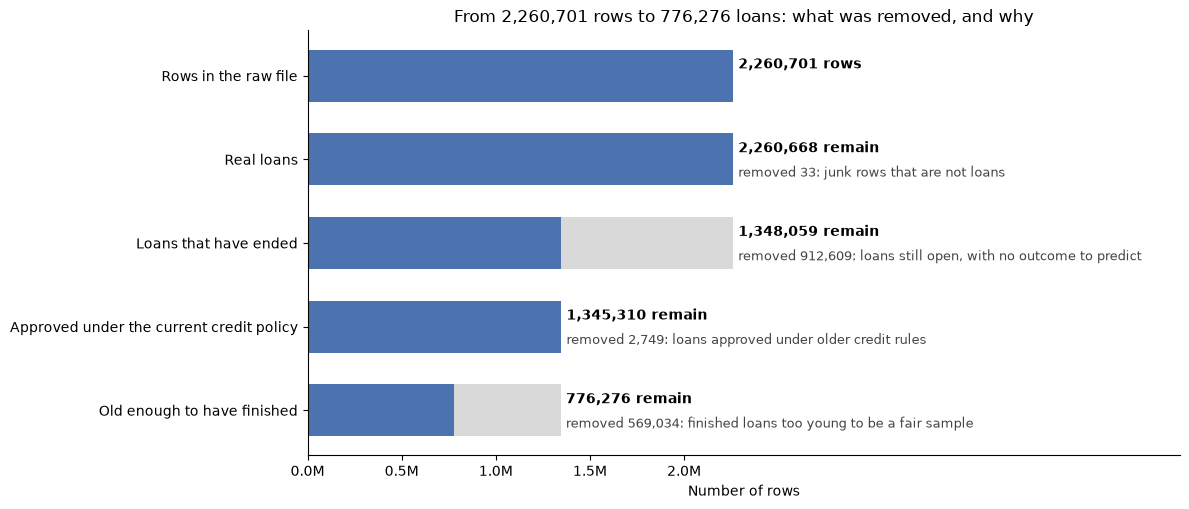

In [127]:
# Stage 1, Step 6 - Before versus after cleaning: how the rows were reduced
# Question: how did the raw file become the loans we analyse, and why was each group of rows removed?
# Every number is read from df (raw data) and loans (cleaned data); nothing is typed in by hand.
from matplotlib.ticker import FuncFormatter

status = df['loan_status'].value_counts()
rows_total = len(df)
rows_junk = int(df['loan_amnt'].isna().sum())
rows_open = int(status.reindex(['Current', 'Late (31-120 days)', 'In Grace Period', 'Late (16-30 days)', 'Default']).sum())
rows_policy = int(status[status.index.str.startswith('Does not meet the credit policy')].sum())
rows_finished = int(status.reindex(['Fully Paid', 'Charged Off']).sum())
rows_kept = len(loans)

funnel = pd.DataFrame([
    ('Rows in the raw file', rows_total, 0, ''),
    ('Real loans', rows_total - rows_junk, rows_junk, 'junk rows that are not loans'),
    ('Loans that have ended', rows_total - rows_junk - rows_open, rows_open, 'loans still open, with no outcome to predict'),
    ('Approved under the current credit policy', rows_finished, rows_policy, 'loans approved under older credit rules'),
    ('Old enough to have finished', rows_kept, rows_finished - rows_kept, 'finished loans too young to be a fair sample'),
], columns=['stage', 'rows remaining', 'rows removed', 'what was removed'])
funnel['share of the raw file (%)'] = (funnel['rows remaining'] / rows_total * 100).round(1)

display(Markdown('**Table 22. From the raw file to the loans analysed: rows remaining after each stage**<br>'
                 'Each stage removes one group of rows, for the reason given.'))
with pd.option_context('display.max_colwidth', None):
    display(funnel.set_index('stage'))
print('Of the {:,} loans that have a known outcome, {:.1f}% are kept.'.format(rows_finished, rows_kept / rows_finished * 100))

# Funnel chart: grey = size before the stage, blue = rows remaining after it
fig, ax = plt.subplots(figsize=(12, 5.2))
positions = range(len(funnel) - 1, -1, -1)
previous = [rows_total] + list(funnel['rows remaining'][:-1])
ax.barh(positions, previous, color='#d9d9d9', height=0.62)
ax.barh(positions, funnel['rows remaining'], color='#4c72b0', height=0.62)
for pos, before, (_, row) in zip(positions, previous, funnel.iterrows()):
    ax.text(before + rows_total * 0.012, pos + 0.13, ('{:,} remain' if row['rows removed'] > 0 else '{:,} rows').format(row['rows remaining']), va='center', fontsize=10, fontweight='bold')
    if row['rows removed'] > 0:
        ax.text(before + rows_total * 0.012, pos - 0.16, 'removed {:,}: {}'.format(row['rows removed'], row['what was removed']),
                va='center', fontsize=9, color='#444444')
ax.set_yticks(list(positions))
ax.set_yticklabels(funnel['stage'])
ax.set_xlim(0, rows_total * 2.05)
ax.set_xticks([0, 500000, 1000000, 1500000, 2000000])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:.1f}M'.format(v / 1e6)))
ax.set_xlabel('Number of rows')
ax.set_title('From {:,} rows to {:,} loans: what was removed, and why'.format(rows_total, rows_kept), fontsize=12)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

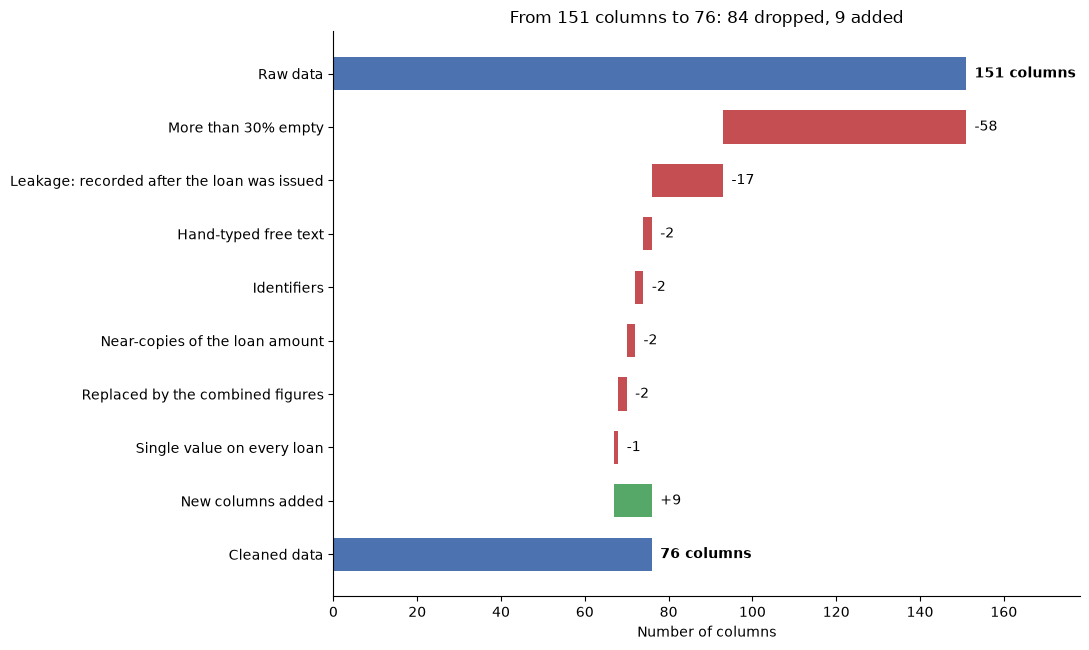

Running total matches the cleaned data: True
New columns: ['charged_off', 'annual_inc_combined', 'dti_combined', 'bureau_not_collected', 'emp_length_not_provided', 'emp_length_years', 'credit_history_years', 'fico_avg', 'issue_year']


**Table 23. The data before and after cleaning**<br>Raw data = the file as loaded. Cleaned data = the loans and columns kept at the end of Step 5. Missing-value counts for the raw data are measured on real loans (junk rows excluded).

,raw data,cleaned data
measure,,
rows,"2,260,701","776,276"
columns,151,76
rows that are not loans,33,0
columns with missing values,113,0
columns more than 30% empty,58,0
text columns,38,12
loans with a placeholder debt-to-income value,137,0
charge-off rate among loans with an outcome,20.0%,15.2%


In [128]:
# Stage 1, Step 6 - Before versus after cleaning: how the columns changed
# Question: which columns were dropped, for what reason, and what was added?
# The counts come from dropped, the record kept by every Step 5 cell that removed a column.
def reason_group(reason):
    if reason.startswith('more than 30% empty'):
        return 'More than 30% empty'
    if reason.startswith('leakage'):
        return 'Leakage: recorded after the loan was issued'
    if reason.startswith('identifier'):
        return 'Identifiers'
    if reason.startswith('single value'):
        return 'Single value on every loan'
    if reason.startswith('near-copy of loan_amnt'):
        return 'Near-copies of the loan amount'
    if reason.startswith('replaced by'):
        return 'Replaced by the combined figures'
    return 'Hand-typed free text'

drop_counts = pd.Series(dropped).map(reason_group).value_counts()
added_cols = [col for col in loans.columns if col not in df.columns]
columns_raw, columns_clean = df.shape[1], loans.shape[1]

steps = [('Raw data', columns_raw, 'total')]
steps += [(name, -int(count), 'dropped') for name, count in drop_counts.items()]
steps += [('New columns added', len(added_cols), 'added'), ('Cleaned data', columns_clean, 'total')]

fig, ax = plt.subplots(figsize=(11, 0.5 * len(steps) + 1.6))
colors = {'total': '#4c72b0', 'dropped': '#c44e52', 'added': '#55a868'}
running = 0
for i, (name, change, kind) in enumerate(steps):
    pos = len(steps) - 1 - i
    if kind == 'total':
        ax.barh(pos, change, color=colors[kind], height=0.62)
        ax.text(change + 2, pos, '{} columns'.format(change), va='center', fontsize=10, fontweight='bold')
        running = change
    else:
        ax.barh(pos, abs(change), left=min(running, running + change), color=colors[kind], height=0.62)
        ax.text(max(running, running + change) + 2, pos, '{:+d}'.format(change), va='center', fontsize=10)
        running += change
ax.set_yticks(range(len(steps)))
ax.set_yticklabels([name for name, _, _ in steps][::-1])
ax.set_xlim(0, columns_raw * 1.18)
ax.set_xlabel('Number of columns')
ax.set_title('From {} columns to {}: {} dropped, {} added'.format(columns_raw, columns_clean, len(dropped), len(added_cols)), fontsize=12)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()
print('Running total matches the cleaned data:', running == columns_clean)
print('New columns:', added_cols)

# Before-and-after summary of the whole cleaning stage
raw_outcome = df['loan_status'].isin(['Fully Paid', 'Charged Off'])
summary = pd.DataFrame({
    'raw data': [
        '{:,}'.format(len(df)), str(columns_raw),
        '{:,}'.format(int(df['loan_amnt'].isna().sum())),
        str(int((missing_pct > 0).sum())), str(int((missing_pct > 30).sum())),
        str(df.select_dtypes(exclude='number').shape[1]),
        '{:,}'.format(int(df['dti'].isin([999, -1]).sum())),
        '{:.1f}%'.format((df.loc[raw_outcome, 'loan_status'] == 'Charged Off').mean() * 100),
    ],
    'cleaned data': [
        '{:,}'.format(len(loans)), str(columns_clean),
        '0',
        str(int(loans.isna().any().sum())), str(int((loans.isna().mean() > 0.30).sum())),
        str(loans.select_dtypes(exclude=['number', 'datetime']).shape[1]),
        '{:,}'.format(int(loans['dti_combined'].isin([999, -1]).sum())),
        '{:.1f}%'.format(loans['charged_off'].mean() * 100),
    ],
}, index=['rows', 'columns', 'rows that are not loans', 'columns with missing values', 'columns more than 30% empty',
          'text columns', 'loans with a placeholder debt-to-income value', 'charge-off rate among loans with an outcome'])
summary.index.name = 'measure'
display(Markdown('**Table 23. The data before and after cleaning**<br>'
                 'Raw data = the file as loaded. Cleaned data = the loans and columns kept at the end of Step 5. '
                 'Missing-value counts for the raw data are measured on real loans (junk rows excluded).'))
display(summary)

In [130]:
# Stage 1, Step 6 - Save the cleaned data
# Parquet keeps the column types (numbers, dates, text) and loads in seconds.
# To pick up from here in a new session, skip the cleaning cells and run:
#     loans = pd.read_parquet('loans_clean.parquet')
# The file is too large for GitHub, so keep it out of the repository.
import os

clean_path = 'loans_clean.parquet'
loans.to_parquet(clean_path, index=False)
print('Saved', clean_path)
print('Rows: {:,} | Columns: {} | Size: {:.0f} MB'.format(len(loans), loans.shape[1], os.path.getsize(clean_path) / 1e6))

# Read it back to confirm the file is complete
check = pd.read_parquet(clean_path)
print('Reads back with the same rows, columns and column names:', check.shape == loans.shape and list(check.columns) == list(loans.columns))
del check

Saved loans_clean.parquet
Rows: 776,276 | Columns: 76 | Size: 53 MB
Reads back with the same rows, columns and column names: True


## Univariate, Categorical

In [131]:
# Stage 2, Step 7 - Categorical columns: how many categories, and how big are they?
# Question: what kinds of loans are in the cleaned data?
# This is a counting step. Nothing is compared with the outcome yet (that is Stage 4) and nothing is changed.
cat_cols = ['charged_off', 'term', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose',
            'application_type', 'initial_list_status', 'disbursement_method', 'addr_state', 'zip_code', 'issue_year']
rows = {}
for col in cat_cols:
    counts = loans[col].value_counts()
    rows[col] = {
        'categories': len(counts),
        'largest category': '{} ({:.1f}%)'.format(counts.index[0], counts.iloc[0] / len(loans) * 100),
        'smallest category': '{} ({:,} {})'.format(counts.index[-1], counts.iloc[-1], 'loan' if counts.iloc[-1] == 1 else 'loans'),
        'categories under 1,000 loans': int((counts < 1000).sum()),
        'note': 'nearly one value' if counts.iloc[0] / len(loans) > 0.95 else '',
    }
cat_table = pd.DataFrame(rows).T
cat_table.index.name = 'column'
display(Markdown('**Table 24. The categorical columns in the cleaned data**<br>'
                 'Measured on the {:,} loans kept. A column that is nearly one value cannot tell loans apart; '
                 'categories under 1,000 loans are too small to compare reliably.'.format(len(loans))))
with pd.option_context('display.max_colwidth', None):
    display(cat_table)

**Table 24. The categorical columns in the cleaned data**<br>Measured on the 776,276 loans kept. A column that is nearly one value cannot tell loans apart; categories under 1,000 loans are too small to compare reliably.

,categories,largest category,smallest category,"categories under 1,000 loans",note
column,,,,,
charged_off,2,0 (84.8%),"1 (117,610 loans)",0,
term,2,36 (91.3%),"60 (67,908 loans)",0,
grade,7,B (32.4%),"G (2,350 loans)",0,
sub_grade,35,B3 (7.1%),G5 (198 loans),5,
emp_length,12,10+ years (31.6%),"9 years (29,574 loans)",0,
home_ownership,4,MORTGAGE (47.8%),OTHER (191 loans),1,
verification_status,3,Source Verified (35.5%),"Not Verified (247,578 loans)",0,
purpose,14,debt_consolidation (57.1%),educational (326 loans),2,
application_type,2,Individual (99.8%),"Joint App (1,627 loans)",0,nearly one value


**Question: out of every 100 loans, how many were charged off?**

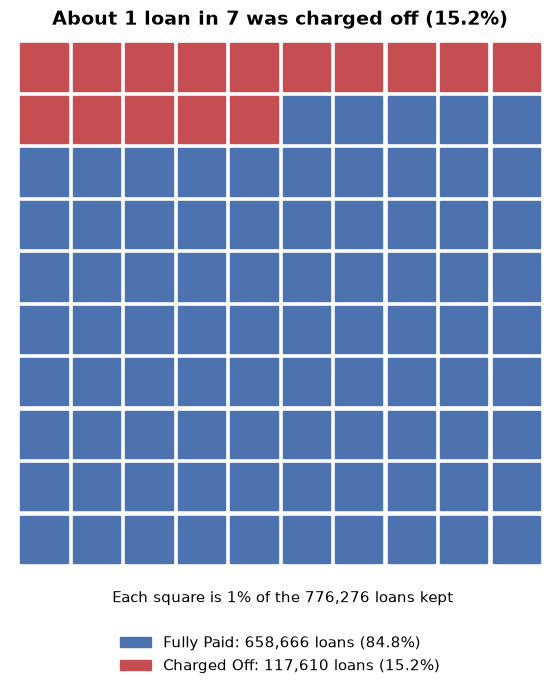

In [133]:
# Stage 2, Step 7 - Chart 1 of 6: the outcome
# Question: out of every 100 loans, how many were charged off?
# Chart type: a 10 x 10 grid of squares, because the answer is a single share and a grid makes it countable.
from matplotlib.patches import Patch

n_loans = len(loans)
n_charged = int(loans['charged_off'].sum())
share_charged = n_charged / n_loans * 100
red_squares = int(round(share_charged))

fig, ax = plt.subplots(figsize=(7.5, 7))
for i in range(100):
    row, col = divmod(i, 10)
    color = '#c44e52' if i < red_squares else '#4c72b0'
    ax.add_patch(plt.Rectangle((col, 9 - row), 0.9, 0.9, color=color))
ax.set_xlim(-0.2, 10.1)
ax.set_ylim(-0.2, 10.1)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('About 1 loan in {:.0f} was charged off ({:.1f}%)'.format(100 / share_charged, share_charged), fontsize=14, fontweight='bold')
ax.text(5, -0.75, 'Each square is 1% of the {:,} loans kept'.format(n_loans), ha='center', fontsize=11)
ax.legend(handles=[Patch(color='#4c72b0', label='Fully Paid: {:,} loans ({:.1f}%)'.format(n_loans - n_charged, 100 - share_charged)),
                   Patch(color='#c44e52', label='Charged Off: {:,} loans ({:.1f}%)'.format(n_charged, share_charged))],
          loc='upper center', bbox_to_anchor=(0.5, -0.09), ncols=1, frameon=False, fontsize=11)
display(Markdown('**Question: out of every 100 loans, how many were charged off?**'))
plt.tight_layout()
plt.show()

**Question: how are the loans divided by term, home ownership and income verification?**<br>Each bar adds up to 100% of the loans kept. A darker shade is a larger category; parts under 4% are too thin to label.

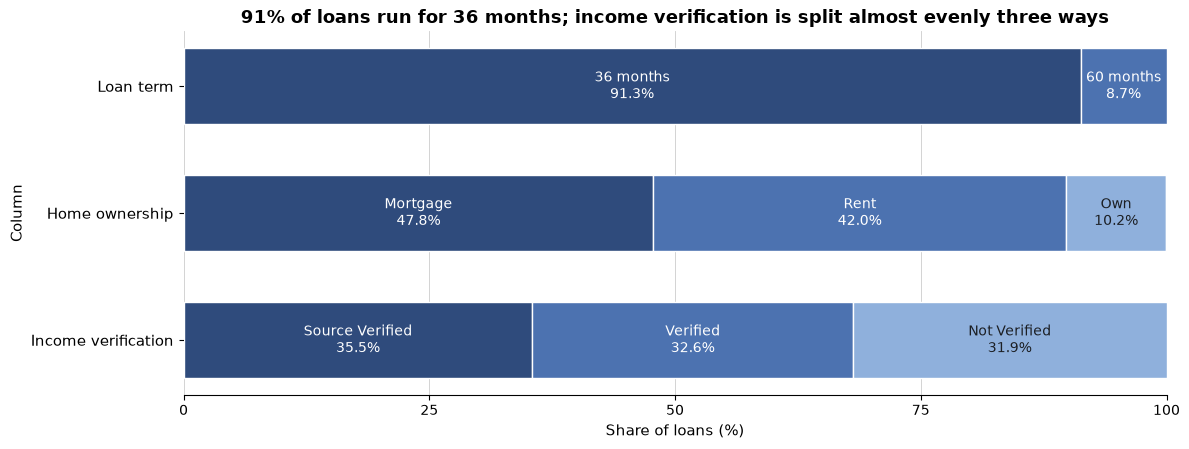

In [134]:
# Stage 2, Step 7 - Chart 2 of 6: how three columns split into their categories
# Question: how are the loans divided by term, home ownership and income verification?
# Chart type: one 100% bar per column, because each column is a whole split into a few parts.
strips = [('Loan term', loans['term'].map(lambda t: '{} months'.format(t))),
          ('Home ownership', loans['home_ownership'].str.capitalize()),
          ('Income verification', loans['verification_status'])]
shades = ['#2f4b7c', '#4c72b0', '#8fb0dc', '#c9d9ee']

fig, ax = plt.subplots(figsize=(12, 4.6))
for pos, (name, values) in zip([2, 1, 0], strips):
    shares = values.value_counts(normalize=True) * 100
    left = 0
    for k, (category, share) in enumerate(shares.items()):
        ax.barh(pos, share, left=left, color=shades[k], edgecolor='white', height=0.6)
        if share >= 4:
            ax.text(left + share / 2, pos, '{}\n{:.1f}%'.format(category, share), ha='center', va='center',
                    fontsize=10, color='white' if k < 2 else '#1c1f24')
        left += share
ax.set_yticks([2, 1, 0])
ax.set_yticklabels([name for name, _ in strips], fontsize=11)
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel('Share of loans (%)', fontsize=11)
ax.set_ylabel('Column', fontsize=11)
ax.xaxis.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
top_term = loans['term'].value_counts(normalize=True).iloc[0] * 100
ax.set_title('{:.0f}% of loans run for 36 months; income verification is split almost evenly three ways'.format(top_term),
             fontsize=13, fontweight='bold')
for side in ('top', 'right', 'left'):
    ax.spines[side].set_visible(False)
display(Markdown('**Question: how are the loans divided by term, home ownership and income verification?**<br>'
                 'Each bar adds up to 100% of the loans kept. A darker shade is a larger category; parts under 4% are too thin to label.'))
plt.tight_layout()
plt.show()

**Question: how are the loans spread across the lender's grades, from A (lowest risk) to G (highest risk)?**

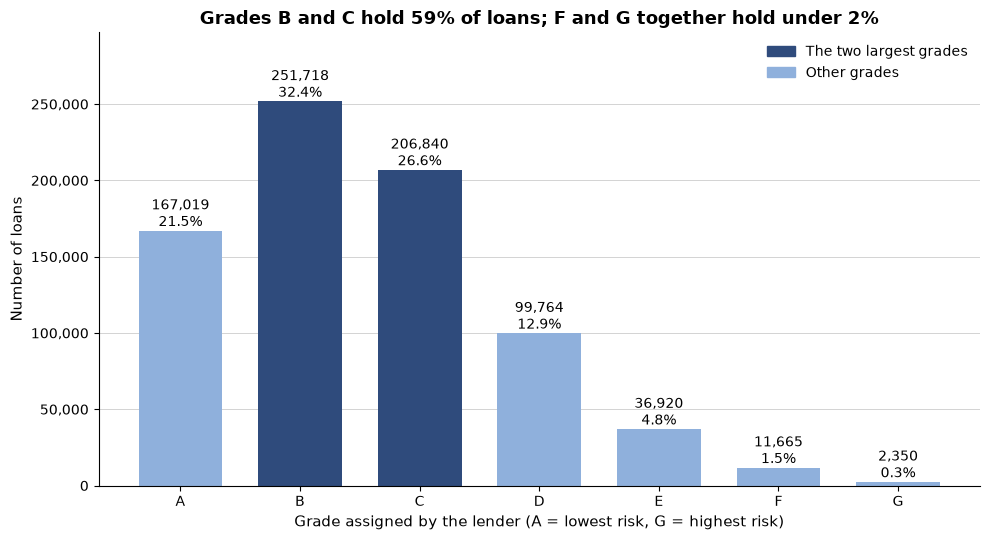

In [135]:
# Stage 2, Step 7 - Chart 3 of 6: grade
# Question: how are the loans spread across the lender's grades, from A (lowest risk) to G (highest risk)?
# Chart type: columns in grade order, because the grades have a natural order that should read left to right.
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

grade_counts = loans['grade'].value_counts().sort_index()
grade_share = grade_counts / len(loans) * 100
top_two = grade_counts.nlargest(2).index
colors = ['#2f4b7c' if g in top_two else '#8fb0dc' for g in grade_counts.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(grade_counts.index, grade_counts.values, color=colors, width=0.7)
for i, (count, share) in enumerate(zip(grade_counts.values, grade_share.values)):
    ax.text(i, count, '{:,}\n{:.1f}%'.format(count, share), ha='center', va='bottom', fontsize=10)
ax.set_ylim(0, grade_counts.max() * 1.18)
ax.set_xlabel('Grade assigned by the lender (A = lowest risk, G = highest risk)', fontsize=11)
ax.set_ylabel('Number of loans', fontsize=11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:,.0f}'.format(v)))
ax.yaxis.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
ax.set_title('Grades {} and {} hold {:.0f}% of loans; F and G together hold under {:.0f}%'.format(
    sorted(top_two)[0], sorted(top_two)[1], grade_share[top_two].sum(), np.ceil(grade_share[['F', 'G']].sum())), fontsize=13, fontweight='bold')
ax.legend(handles=[Patch(color='#2f4b7c', label='The two largest grades'), Patch(color='#8fb0dc', label='Other grades')],
          frameon=False, fontsize=10, loc='upper right')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
display(Markdown('**Question: how are the loans spread across the lender\'s grades, from A (lowest risk) to G (highest risk)?**'))
plt.tight_layout()
plt.show()

**Question: how long have borrowers been in their job, and how many did not say?**<br>The stated lengths are grouped into bins: 0 to 3 years includes "< 1 year". "10+ years" is the highest value the data records, so it means ten years or more. The count for every single year is in Table 17.

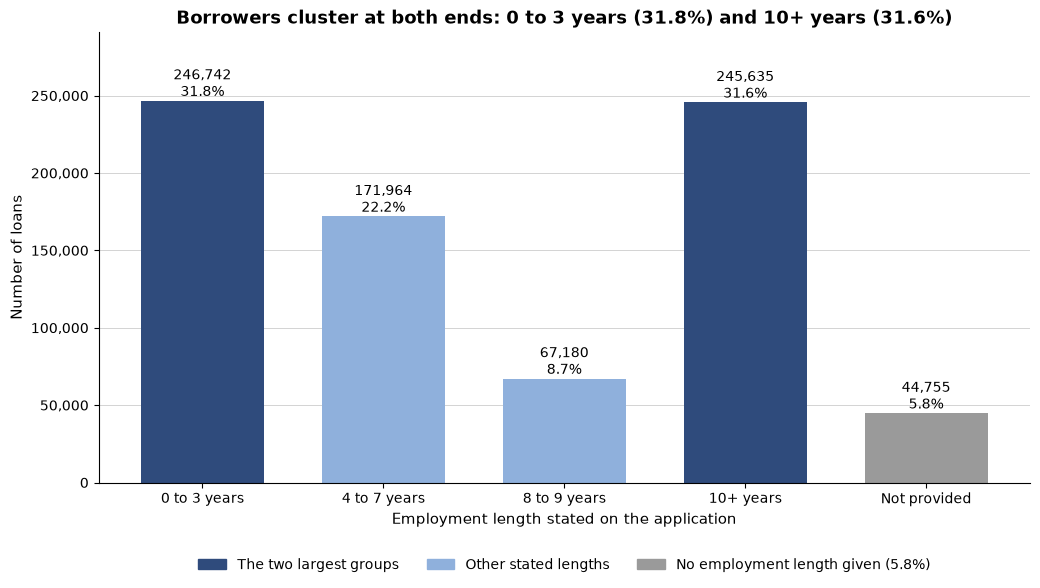

In [139]:
# Stage 2, Step 7 - Chart 4 of 6: employment length
# Question: how long have borrowers been in their job, and how many did not say?
# Chart type: columns in order of years. The eleven stated lengths are grouped into four bins so the chart shows the pattern, not the detail.
#   "10+ years" is the highest value the data records (ten years or more), so it stays as its own open-ended bin.
#   "Not provided" is set apart in grey because it is not a length.
# The bins are for this chart only; the emp_length column in the data is not changed.
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

emp_bins = {'< 1 year': '0 to 3 years', '1 year': '0 to 3 years', '2 years': '0 to 3 years', '3 years': '0 to 3 years',
            '4 years': '4 to 7 years', '5 years': '4 to 7 years', '6 years': '4 to 7 years', '7 years': '4 to 7 years',
            '8 years': '8 to 9 years', '9 years': '8 to 9 years',
            '10+ years': '10+ years', 'Not provided': 'Not provided'}
bin_order = ['0 to 3 years', '4 to 7 years', '8 to 9 years', '10+ years', 'Not provided']
bin_counts = loans['emp_length'].map(emp_bins).value_counts().reindex(bin_order)
bin_share = bin_counts / len(loans) * 100
stated = bin_counts.drop('Not provided')
top_two = stated.nlargest(2).index
colors = ['#9a9a9a' if label == 'Not provided' else ('#2f4b7c' if label in top_two else '#8fb0dc') for label in bin_order]

fig, ax = plt.subplots(figsize=(10.5, 6))
ax.bar(bin_order, bin_counts.values, color=colors, width=0.68)
for i, (count, share) in enumerate(zip(bin_counts.values, bin_share.values)):
    ax.text(i, count, '{:,}\n{:.1f}%'.format(count, share), ha='center', va='bottom', fontsize=10)
ax.set_ylim(0, bin_counts.max() * 1.18)
ax.set_xlabel('Employment length stated on the application', fontsize=11)
ax.set_ylabel('Number of loans', fontsize=11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:,.0f}'.format(v)))
ax.yaxis.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
ax.set_title('Borrowers cluster at both ends: 0 to 3 years ({:.1f}%) and 10+ years ({:.1f}%)'.format(
    bin_share['0 to 3 years'], bin_share['10+ years']), fontsize=13, fontweight='bold')
ax.legend(handles=[Patch(color='#2f4b7c', label='The two largest groups'), Patch(color='#8fb0dc', label='Other stated lengths'),
                   Patch(color='#9a9a9a', label='No employment length given ({:.1f}%)'.format(bin_share['Not provided']))],
          frameon=False, fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncols=3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
display(Markdown('**Question: how long have borrowers been in their job, and how many did not say?**<br>'
                 'The stated lengths are grouped into bins: 0 to 3 years includes "< 1 year". '
                 '"10+ years" is the highest value the data records, so it means ten years or more. '
                 'The count for every single year is in Table 17.'))
plt.tight_layout()
plt.show()

**Question: what are borrowers using the loans for?**

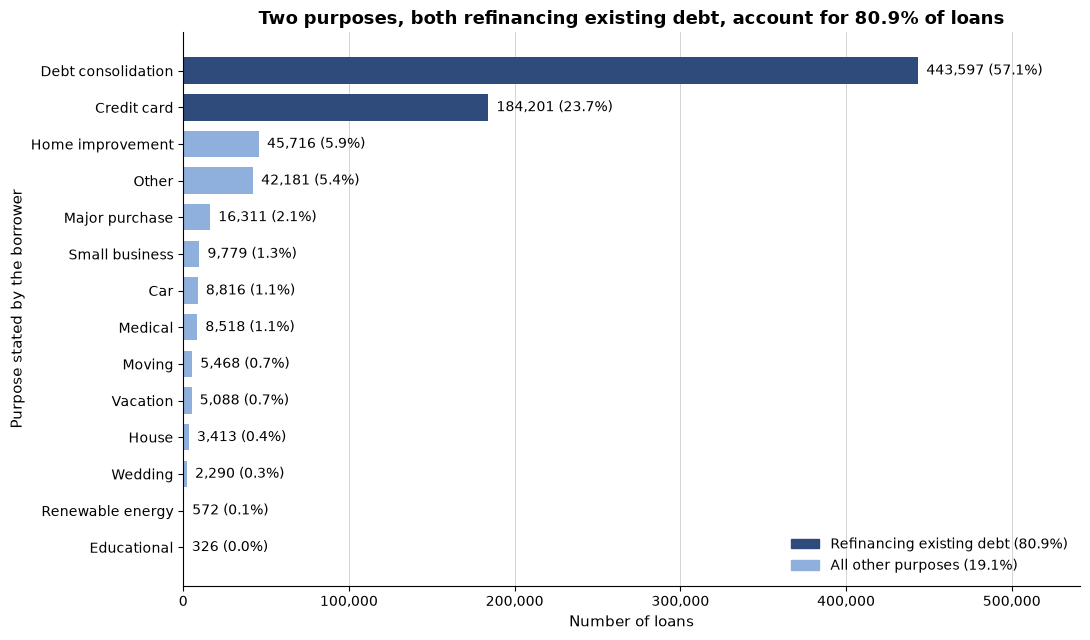

In [137]:
# Stage 2, Step 7 - Chart 5 of 6: purpose
# Question: what are borrowers using the loans for?
# Chart type: bars sorted largest first and drawn sideways, because there are 14 categories with long names and no natural order.
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

purpose_counts = loans['purpose'].value_counts()
purpose_share = purpose_counts / len(loans) * 100
refinancing = ['debt_consolidation', 'credit_card']
labels = [name.replace('_', ' ').capitalize() for name in purpose_counts.index]
colors = ['#2f4b7c' if name in refinancing else '#8fb0dc' for name in purpose_counts.index]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(labels[::-1], purpose_counts.values[::-1], color=colors[::-1], height=0.72)
for i, (count, share) in enumerate(zip(purpose_counts.values[::-1], purpose_share.values[::-1])):
    ax.text(count, i, '  {:,} ({:.1f}%)'.format(count, share), va='center', fontsize=10)
ax.set_xlim(0, purpose_counts.max() * 1.22)
ax.set_xlabel('Number of loans', fontsize=11)
ax.set_ylabel('Purpose stated by the borrower', fontsize=11)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:,.0f}'.format(v)))
ax.xaxis.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
refi_share = purpose_share[refinancing].sum()
ax.set_title('Two purposes, both refinancing existing debt, account for {:.1f}% of loans'.format(refi_share), fontsize=13, fontweight='bold')
ax.legend(handles=[Patch(color='#2f4b7c', label='Refinancing existing debt ({:.1f}%)'.format(refi_share)),
                   Patch(color='#8fb0dc', label='All other purposes ({:.1f}%)'.format(100 - refi_share))],
          frameon=False, fontsize=10, loc='lower right')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
display(Markdown('**Question: what are borrowers using the loans for?**'))
plt.tight_layout()
plt.show()

**Question: how did the number of loans change from year to year?**<br>These are the loans kept, not all loans issued. The drop in the last year is not a fall in lending: the loan-age rule keeps 36-month loans only through March 2016, and 60-month loans only through March 2014.

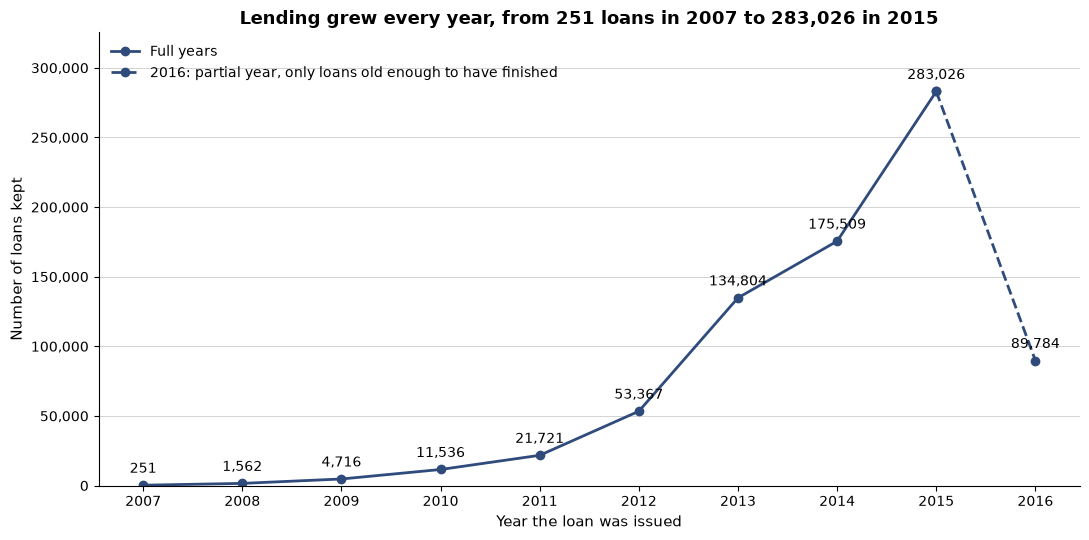

In [138]:
# Stage 2, Step 7 - Chart 6 of 6: issue year
# Question: how did the number of loans change from year to year?
# Chart type: a line, because the years are a sequence in time and the point is the trend.
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

year_counts = loans['issue_year'].value_counts().sort_index()
full = year_counts.iloc[:-1]            # the last year is only partly covered by the loans kept
last_two = year_counts.iloc[-2:]

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(full.index, full.values, color='#2f4b7c', marker='o', linewidth=2)
ax.plot(last_two.index, last_two.values, color='#2f4b7c', marker='o', linewidth=2, linestyle='--')
for year, count in year_counts.items():
    ax.annotate('{:,}'.format(count), (year, count), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=10)
ax.set_xticks(list(year_counts.index))
ax.set_ylim(0, year_counts.max() * 1.15)
ax.set_xlabel('Year the loan was issued', fontsize=11)
ax.set_ylabel('Number of loans kept', fontsize=11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:,.0f}'.format(v)))
ax.yaxis.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
ax.set_title('Lending grew every year, from {:,} loans in {} to {:,} in {}'.format(
    year_counts.iloc[0], year_counts.index[0], full.iloc[-1], full.index[-1]), fontsize=13, fontweight='bold')
ax.legend(handles=[Line2D([0], [0], color='#2f4b7c', marker='o', linewidth=2, label='Full years'),
                   Line2D([0], [0], color='#2f4b7c', marker='o', linewidth=2, linestyle='--',
                          label='{}: partial year, only loans old enough to have finished'.format(year_counts.index[-1]))],
          frameon=False, fontsize=10, loc='upper left')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
display(Markdown('**Question: how did the number of loans change from year to year?**<br>'
                 'These are the loans kept, not all loans issued. The drop in the last year is not a fall in lending: '
                 'the loan-age rule keeps 36-month loans only through March 2016, and 60-month loans only through March 2014.'))
plt.tight_layout()
plt.show()

## Univariate, Numerical

In [140]:
# Stage 3, Step 8 - Numeric columns: centre, spread, shape and outliers
# Question: what shape is each of the main numeric columns?
# This is still one column at a time. Nothing is compared with the outcome yet (that is Stage 4) and nothing is changed.
# Outliers are counted with the lecture's rule: a value is outside the fences if it is below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR.
num_cols = ['loan_amnt', 'annual_inc_combined', 'dti_combined', 'fico_avg', 'revol_util', 'revol_bal',
            'credit_history_years', 'open_acc', 'total_acc', 'inq_last_6mths']
rows = {}
for col in num_cols:
    s = loans[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    outside = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
    skew = s.skew()
    rows[col] = {'min': s.min(), 'median': s.median(), 'mean': s.mean(), 'max': s.max(), 'skew': round(skew, 2),
                 'shape': 'roughly symmetric' if abs(skew) <= 0.5 else ('right-skewed' if skew > 0 else 'left-skewed'),
                 'outside the fences (%)': round(outside, 1)}
num_table = pd.DataFrame(rows).T
for col in ('min', 'median', 'mean', 'max'):
    num_table[col] = num_table[col].astype(float).round(1)
num_table.index.name = 'column'
display(Markdown('**Table 25. The main numeric columns: centre, spread, shape and outliers**<br>'
                 'Measured on the {:,} loans kept. Skew between -0.5 and 0.5 counts as roughly symmetric. '
                 '"Outside the fences" is the share of loans beyond 1.5 x IQR from the quartiles.'.format(len(loans))))
display(num_table)

**Table 25. The main numeric columns: centre, spread, shape and outliers**<br>Measured on the 776,276 loans kept. Skew between -0.5 and 0.5 counts as roughly symmetric. "Outside the fences" is the share of loans beyond 1.5 x IQR from the quartiles.

,min,median,mean,max,skew,shape,outside the fences (%)
column,,,,,,,
loan_amnt,500.0,11100.0,13247.9,40000.0,0.91,right-skewed,3.2
annual_inc_combined,3000.0,62000.0,73903.5,9000000.0,42.65,right-skewed,4.5
dti_combined,0.0,17.2,17.7,63.7,0.27,roughly symmetric,0.1
fico_avg,627.0,692.0,697.5,847.5,1.3,right-skewed,3.2
revol_util,0.0,54.5,53.9,892.3,-0.08,roughly symmetric,0.0
revol_bal,0.0,11044.0,16032.8,2904836.0,16.77,right-skewed,5.8
credit_history_years,3.0,14.7,16.2,71.0,1.08,right-skewed,3.2
open_acc,0.0,10.0,11.3,84.0,1.25,right-skewed,2.8
total_acc,2.0,23.0,24.7,176.0,0.9,right-skewed,2.1


**Question: how much do borrowers ask for?**<br>Each bar is a &#36;1,000 range. Loans run from &#36;500 to &#36;40,000, and only 295 loans are above &#36;35,000; skew 0.91.

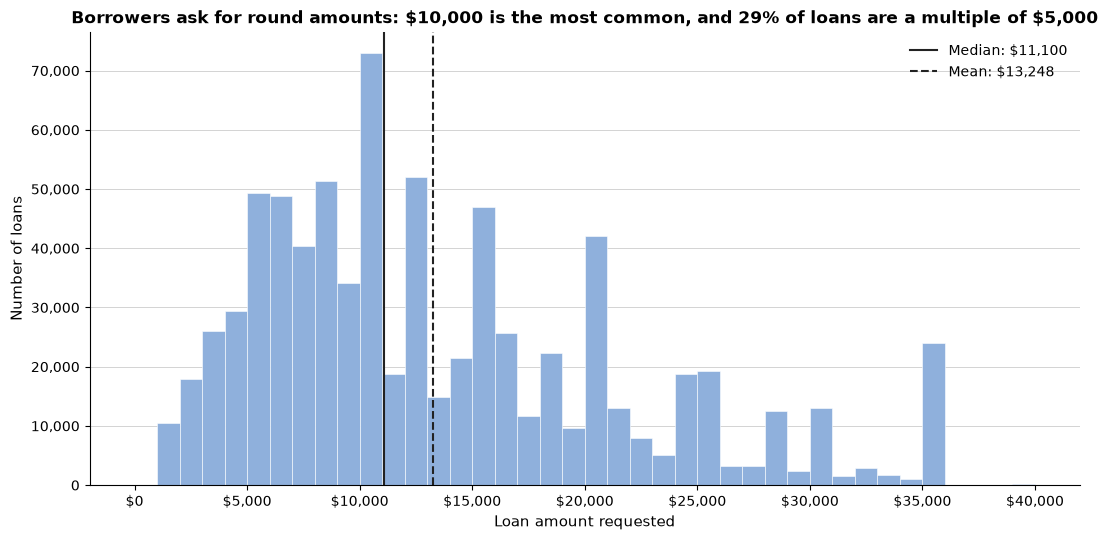

In [141]:
# Stage 3, Step 8 - Chart 1 of 5: loan amount
# Question: how much do borrowers ask for?
# Chart type: a histogram with $1,000 bins, because the column is a continuous amount and the point is its shape.
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

amount = loans['loan_amnt']
bins = np.arange(0, amount.max() + 1000, 1000)
round_share = (amount % 5000 == 0).mean() * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hist(amount, bins=bins, color='#8fb0dc', edgecolor='white', linewidth=0.4)
ax.axvline(amount.median(), color='#222222', linewidth=1.5)
ax.axvline(amount.mean(), color='#222222', linewidth=1.5, linestyle='--')
ax.set_xlabel('Loan amount requested', fontsize=11)
ax.set_ylabel('Number of loans', fontsize=11)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: '${:,.0f}'.format(v)))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:,.0f}'.format(v)))
ax.yaxis.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
ax.set_title('Borrowers ask for round amounts: ${:,.0f} is the most common, and {:.0f}% of loans are a multiple of $5,000'.format(
    amount.mode().iloc[0], round_share), fontsize=12.5, fontweight='bold', parse_math=False)
ax.legend(handles=[Line2D([0], [0], color='#222222', linewidth=1.5, label='Median: ${:,.0f}'.format(amount.median())),
                   Line2D([0], [0], color='#222222', linewidth=1.5, linestyle='--', label='Mean: ${:,.0f}'.format(amount.mean()))],
          frameon=False, fontsize=10, loc='upper right')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
display(Markdown(('**Question: how much do borrowers ask for?**<br>'
                  'Each bar is a $1,000 range. Loans run from ${:,.0f} to ${:,.0f}, and only {:,} loans are above $35,000; skew {:.2f}.'.format(
                      amount.min(), amount.max(), int((amount > 35000).sum()), amount.skew())).replace('$', '&#36;')))
plt.tight_layout()
plt.show()

**Question: what credit scores do borrowers have when they apply?**<br>Scores run from 627 to 848; skew 1.30. The sharp left edge is not natural: it is where the lender stops approving loans.

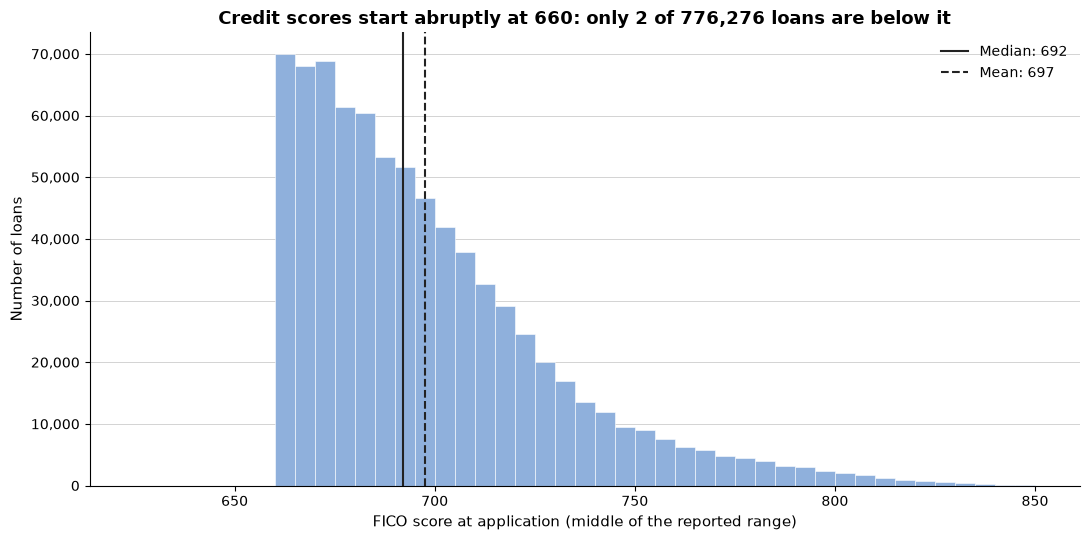

In [142]:
# Stage 3, Step 8 - Chart 2 of 5: credit score
# Question: what credit scores do borrowers have when they apply?
# Chart type: a histogram with 5-point bins, matching the 5-point steps in which FICO scores are reported here.
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

fico = loans['fico_avg']
bins = np.arange(np.floor(fico.min() / 5) * 5, fico.max() + 5, 5)
below_660 = (fico < 660).mean() * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hist(fico, bins=bins, color='#8fb0dc', edgecolor='white', linewidth=0.4)
ax.axvline(fico.median(), color='#222222', linewidth=1.5)
ax.axvline(fico.mean(), color='#222222', linewidth=1.5, linestyle='--')
ax.set_xlabel('FICO score at application (middle of the reported range)', fontsize=11)
ax.set_ylabel('Number of loans', fontsize=11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:,.0f}'.format(v)))
ax.yaxis.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
ax.set_title('Credit scores start abruptly at 660: only {:,} of {:,} loans are below it'.format(int((fico < 660).sum()), len(fico)),
             fontsize=13, fontweight='bold')
ax.legend(handles=[Line2D([0], [0], color='#222222', linewidth=1.5, label='Median: {:.0f}'.format(fico.median())),
                   Line2D([0], [0], color='#222222', linewidth=1.5, linestyle='--', label='Mean: {:.0f}'.format(fico.mean()))],
          frameon=False, fontsize=10, loc='upper right')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
display(Markdown('**Question: what credit scores do borrowers have when they apply?**<br>'
                 'Scores run from {:.0f} to {:.0f}; skew {:.2f}. The sharp left edge is not natural: it is where the lender stops approving loans.'.format(
                     fico.min(), fico.max(), fico.skew())))
plt.tight_layout()
plt.show()

**Question: how much of their income do borrowers already spend on debt payments?**<br>Skew 0.27. The axis stops at 42, which leaves out the highest 0.1% of loans (the maximum is 63.7).

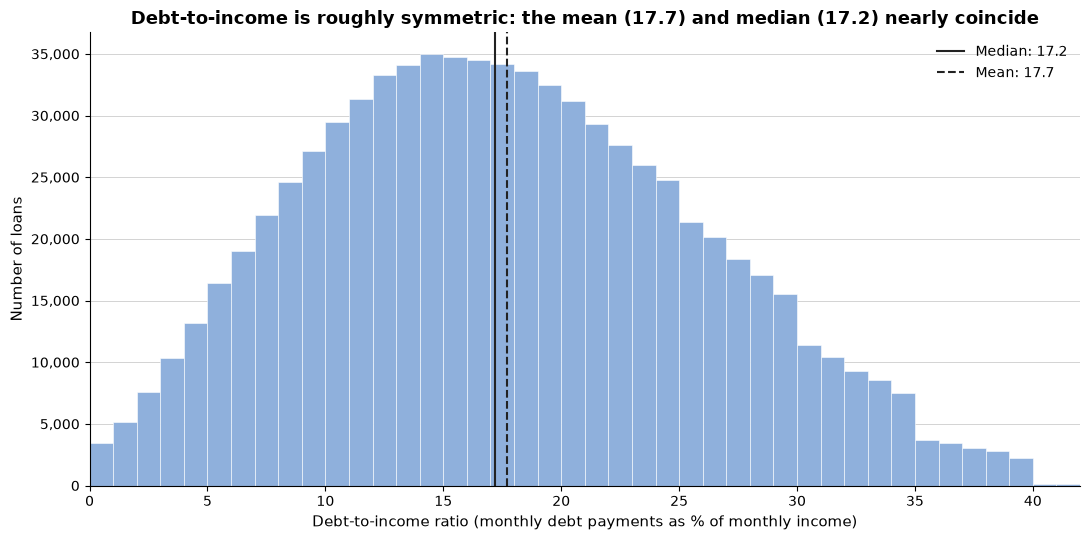

In [143]:
# Stage 3, Step 8 - Chart 3 of 5: debt-to-income
# Question: how much of their income do borrowers already spend on debt payments?
# Chart type: a histogram with 1-point bins, with the mean and median marked to show how symmetric the column is.
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

dti = loans['dti_combined']
upper = np.ceil(dti.quantile(0.999))
bins = np.arange(0, upper + 1, 1)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hist(dti, bins=bins, color='#8fb0dc', edgecolor='white', linewidth=0.4)
ax.axvline(dti.median(), color='#222222', linewidth=1.5)
ax.axvline(dti.mean(), color='#222222', linewidth=1.5, linestyle='--')
ax.set_xlim(0, upper)
ax.set_xlabel('Debt-to-income ratio (monthly debt payments as % of monthly income)', fontsize=11)
ax.set_ylabel('Number of loans', fontsize=11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:,.0f}'.format(v)))
ax.yaxis.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
ax.set_title('Debt-to-income is roughly symmetric: the mean ({:.1f}) and median ({:.1f}) nearly coincide'.format(dti.mean(), dti.median()),
             fontsize=13, fontweight='bold')
ax.legend(handles=[Line2D([0], [0], color='#222222', linewidth=1.5, label='Median: {:.1f}'.format(dti.median())),
                   Line2D([0], [0], color='#222222', linewidth=1.5, linestyle='--', label='Mean: {:.1f}'.format(dti.mean()))],
          frameon=False, fontsize=10, loc='upper right')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
display(Markdown('**Question: how much of their income do borrowers already spend on debt payments?**<br>'
                 'Skew {:.2f}. The axis stops at {:.0f}, which leaves out the highest 0.1% of loans (the maximum is {:.1f}).'.format(dti.skew(), upper, dti.max())))
plt.tight_layout()
plt.show()

**Question: what does the spread of borrower income look like, and does a log scale make it readable?**<br>Income runs from &#36;3K to &#36;9.0M. On the plain scale a few very high incomes pull the mean above the median; on the log scale the two lines almost meet.

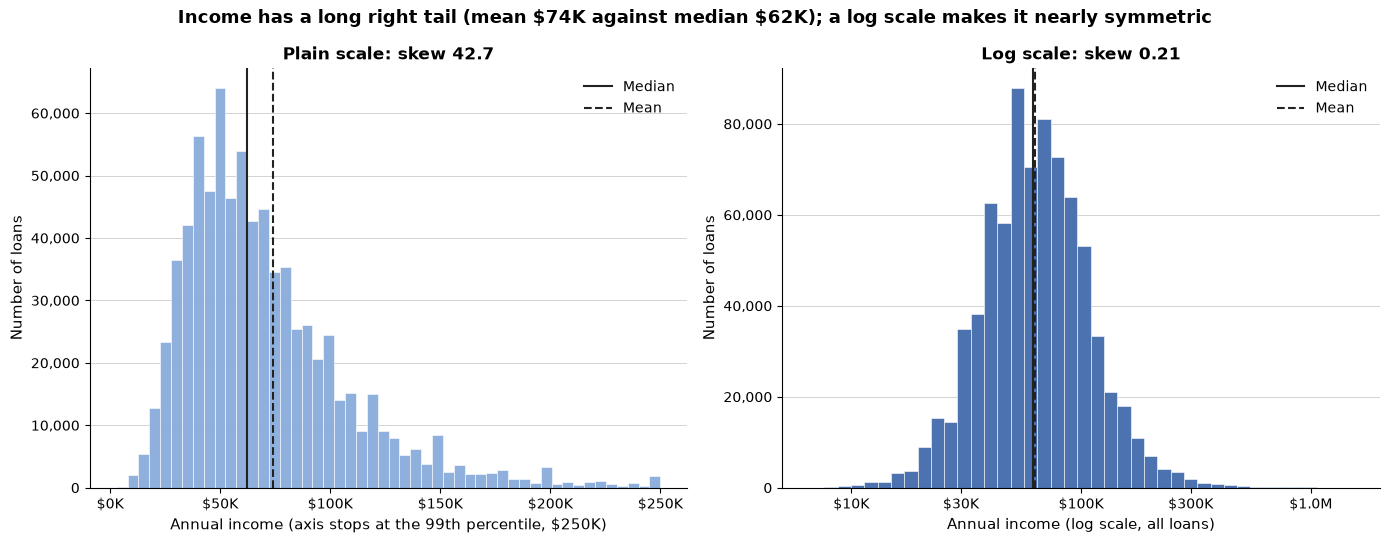

In [144]:
# Stage 3, Step 8 - Chart 4 of 5: annual income, before and after a log scale
# Question: what does the spread of borrower income look like, and does a log scale make it readable?
# Chart type: two histograms side by side, the same column on a plain scale and on a log scale.
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

income = loans['annual_inc_combined']
log_income = np.log10(income.clip(lower=1))
p99 = income.quantile(0.99)

def dollars(value, pos=None):
    return '${:,.0f}K'.format(value / 1000) if value < 1e6 else '${:.1f}M'.format(value / 1e6)

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=False)
left.hist(income[income <= p99], bins=50, color='#8fb0dc', edgecolor='white', linewidth=0.4)
left.axvline(income.median(), color='#222222', linewidth=1.5)
left.axvline(income.mean(), color='#222222', linewidth=1.5, linestyle='--')
left.set_title('Plain scale: skew {:.1f}'.format(income.skew()), fontsize=12, fontweight='bold')
left.set_xlabel('Annual income (axis stops at the 99th percentile, {})'.format(dollars(p99)), fontsize=11)
left.xaxis.set_major_formatter(FuncFormatter(dollars))

right.hist(log_income, bins=60, color='#4c72b0', edgecolor='white', linewidth=0.4)
right.axvline(np.log10(income.median()), color='#222222', linewidth=1.5)
right.axvline(log_income.mean(), color='#222222', linewidth=1.5, linestyle='--')
right.set_title('Log scale: skew {:.2f}'.format(log_income.skew()), fontsize=12, fontweight='bold')
ticks = [10000, 30000, 100000, 300000, 1000000]
right.set_xticks(np.log10(ticks))
right.set_xticklabels([dollars(t) for t in ticks])
right.set_xlim(np.log10(5000), np.log10(2000000))
right.set_xlabel('Annual income (log scale, all loans)', fontsize=11)

for ax in (left, right):
    ax.set_ylabel('Number of loans', fontsize=11)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:,.0f}'.format(v)))
    ax.yaxis.grid(True, color='#cccccc', linewidth=0.6)
    ax.set_axisbelow(True)
    ax.legend(handles=[Line2D([0], [0], color='#222222', linewidth=1.5, label='Median'),
                       Line2D([0], [0], color='#222222', linewidth=1.5, linestyle='--', label='Mean')],
              frameon=False, fontsize=10, loc='upper right')
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
fig.suptitle('Income has a long right tail (mean {} against median {}); a log scale makes it nearly symmetric'.format(
    dollars(income.mean()), dollars(income.median())), fontsize=13, fontweight='bold', parse_math=False)
display(Markdown(('**Question: what does the spread of borrower income look like, and does a log scale make it readable?**<br>'
                  'Income runs from {} to {}. On the plain scale a few very high incomes pull the mean above the median; '
                  'on the log scale the two lines almost meet.'.format(dollars(income.min()), dollars(income.max()))).replace('$', '&#36;')))
plt.tight_layout()
plt.show()

**Question: does taking the log of income bring it close to a normal distribution?**<br>Skew on all 776,276 loans: 42.7 for raw income and 0.21 for log income. This is the evidence for using log income, not raw income, in charts and in any model that assumes a roughly normal input.

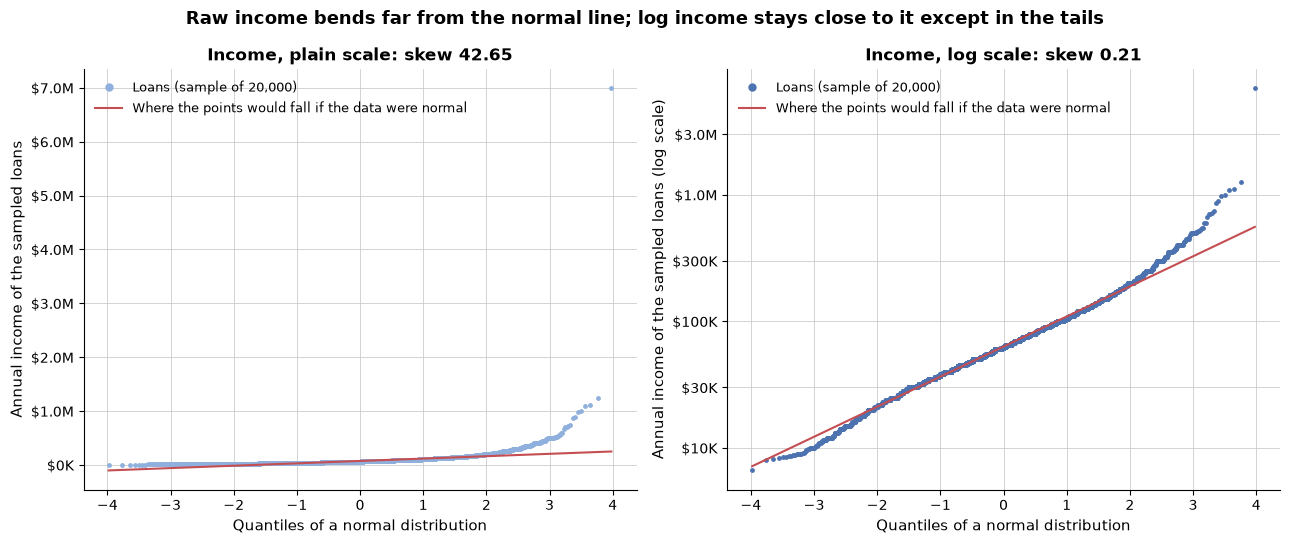

In [145]:
# Stage 3, Step 8 - Chart 5 of 5: is income normal, before and after the log?
# Question: does taking the log of income bring it close to a normal distribution?
# Chart type: two QQ plots. Points on the red line mean the column follows a normal distribution.
# A random sample of 20,000 loans is plotted so the points stay readable; the pattern is the same on all loans.
from scipy import stats
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

income = loans['annual_inc_combined']
sample = income.sample(20000, random_state=42)
log_sample = np.log10(sample.clip(lower=1))
skew_raw, skew_log = income.skew(), np.log10(income.clip(lower=1)).skew()     # measured on all loans

def dollars(value, pos=None):
    return '${:,.0f}K'.format(value / 1000) if value < 1e6 else '${:.1f}M'.format(value / 1e6)

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, values, name, skew, color in ((left, sample, 'Income, plain scale', skew_raw, '#8fb0dc'),
                                      (right, log_sample, 'Income, log scale', skew_log, '#4c72b0')):
    (theory, observed), (slope, intercept, r) = stats.probplot(values, dist='norm')
    ax.scatter(theory, observed, s=6, color=color)
    ax.plot(theory, slope * theory + intercept, color='#c44e52', linewidth=1.5)
    ax.set_title('{}: skew {:.2f}'.format(name, skew), fontsize=12, fontweight='bold')
    ax.set_xlabel('Quantiles of a normal distribution', fontsize=11)
    ax.set_ylabel('Annual income of the sampled loans', fontsize=11)
    ax.grid(True, color='#cccccc', linewidth=0.6)
    ax.set_axisbelow(True)
    ax.legend(handles=[Line2D([0], [0], marker='o', color='none', markerfacecolor=color, markeredgecolor=color, markersize=5, label='Loans (sample of 20,000)'),
                       Line2D([0], [0], color='#c44e52', linewidth=1.5, label='Where the points would fall if the data were normal')],
              frameon=False, fontsize=9.5, loc='upper left')
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
left.yaxis.set_major_formatter(FuncFormatter(dollars))
log_ticks = [10000, 30000, 100000, 300000, 1000000, 3000000]
right.set_yticks(np.log10(log_ticks))
right.set_yticklabels([dollars(t) for t in log_ticks])
right.set_ylabel('Annual income of the sampled loans (log scale)', fontsize=11)
fig.suptitle('Raw income bends far from the normal line; log income stays close to it except in the tails',
             fontsize=13, fontweight='bold')
display(Markdown('**Question: does taking the log of income bring it close to a normal distribution?**<br>'
                 'Skew on all {:,} loans: {:.1f} for raw income and {:.2f} for log income. '
                 'This is the evidence for using log income, not raw income, in charts and in any model that assumes a roughly normal input.'.format(
                     len(income), income.skew(), np.log10(income.clip(lower=1)).skew())))
plt.tight_layout()
plt.show()

## Bivariate

In [146]:
# Stage 4, Step 9 - Which features move with the outcome? Summary table and the two helpers used by the charts below
# Question: which columns separate fully paid loans from charged-off loans, and how strongly?
# Run this cell before the Stage 4 chart cells: it defines overall_rate, rate_table() and draw_rate_bars().
# For every feature the loans are split into groups and the charge-off rate of each group is compared:
#   - a categorical column uses its own categories;
#   - a numeric column is cut into up to five equal-sized groups by value, from lowest to highest
#     (fewer than five when many loans share the same value, as with counts that are mostly 0 or 1).
# Groups under 1,000 loans are left out of the comparison (the lecture's "count before you compare").
from scipy import stats
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

overall_rate = loans['charged_off'].mean() * 100

def rate_table(groups, order=None, min_loans=1000):
    """Loans and charge-off rate (%) for each group; 'enough' marks groups large enough to compare."""
    table = loans.groupby(groups)['charged_off'].agg(['size', 'mean'])
    table.columns = ['loans', 'rate']
    table['rate'] = table['rate'] * 100
    if order is not None:
        table = table.reindex(order)
    table['enough'] = table['loans'] >= min_loans
    return table

def draw_rate_bars(table, title, group_label, horizontal=False, figsize=(10.5, 5.8)):
    """Bar chart of charge-off rate by group. Red = above the overall rate, blue = below, grey = too few loans to trust."""
    colors = ['#b5b5b5' if not ok else ('#c44e52' if rate > overall_rate else '#4c72b0') for rate, ok in zip(table['rate'], table['enough'])]
    labels = [str(label) for label in table.index]
    fig, ax = plt.subplots(figsize=figsize)
    if horizontal:
        ax.barh(labels[::-1], table['rate'].values[::-1], color=colors[::-1], height=0.7)
        for i, (rate, n) in enumerate(zip(table['rate'].values[::-1], table['loans'].values[::-1])):
            ax.text(rate, i, '  {:.1f}%   ({:,} loans)'.format(rate, n), va='center', fontsize=9.5)
        ax.axvline(overall_rate, color='#222222', linestyle='--', linewidth=1.2)
        ax.set_xlim(0, table['rate'].max() * 1.35)
        ax.set_xlabel('Loans charged off (%)', fontsize=11)
        ax.set_ylabel(group_label, fontsize=11)
        ax.xaxis.grid(True, color='#cccccc', linewidth=0.6)
    else:
        ax.bar(labels, table['rate'].values, color=colors, width=0.7)
        for i, (rate, n) in enumerate(zip(table['rate'].values, table['loans'].values)):
            ax.text(i, rate, '{:.1f}%\n{:,} loans'.format(rate, n), ha='center', va='bottom', fontsize=9.5)
        ax.axhline(overall_rate, color='#222222', linestyle='--', linewidth=1.2)
        ax.set_ylim(0, table['rate'].max() * 1.22)
        ax.set_ylabel('Loans charged off (%)', fontsize=11)
        ax.set_xlabel(group_label, fontsize=11)
        ax.yaxis.grid(True, color='#cccccc', linewidth=0.6)
    ax.set_axisbelow(True)
    ax.set_title(title, fontsize=12.5, fontweight='bold')
    handles = [Patch(color='#c44e52', label='Above the overall rate'), Patch(color='#4c72b0', label='Below the overall rate')]
    if not table['enough'].all():
        handles.append(Patch(color='#b5b5b5', label='Under 1,000 loans: too few to trust'))
    handles.append(Line2D([0], [0], color='#222222', linestyle='--', linewidth=1.2, label='Overall rate: {:.1f}%'.format(overall_rate)))
    ax.legend(handles=handles, frameon=False, fontsize=9.5, loc='best')
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()

def plain(value):
    return '{:,.0f}'.format(value) if abs(value) >= 1000 or value == round(value) else '{:,.2f}'.format(value)

categorical = ['grade', 'sub_grade', 'term', 'home_ownership', 'verification_status', 'purpose', 'emp_length',
               'application_type', 'initial_list_status', 'addr_state']
numeric = ['int_rate', 'fico_avg', 'dti_combined', 'annual_inc_combined', 'loan_amnt', 'revol_util', 'inq_last_6mths',
           'acc_open_past_24mths', 'credit_history_years', 'mort_acc', 'open_acc', 'revol_bal', 'emp_length_years']
rows = {}
for col in categorical + numeric:
    if col in categorical:
        groups, kind = loans[col], 'categories'
        strength = np.sqrt(stats.chi2_contingency(pd.crosstab(loans[col], loans['charged_off']))[0] / len(loans))
    else:
        groups = pd.qcut(loans[col], 5, duplicates='drop')
        groups = groups.cat.rename_categories(['{} to {}'.format(plain(max(iv.left, loans[col].min())), plain(iv.right)) for iv in groups.cat.categories])
        kind = 'value ranges, low to high'
        strength = abs(loans[col].corr(loans['charged_off']))
    table = rate_table(groups)
    table = table[table['enough']]
    low, high = table['rate'].idxmin(), table['rate'].idxmax()
    rows[col] = {'groups compared': '{} {}'.format(len(table), kind),
                 'lowest rate (%)': round(table['rate'].min(), 1), 'group with the lowest rate': str(low),
                 'highest rate (%)': round(table['rate'].max(), 1), 'group with the highest rate': str(high),
                 'spread (points)': round(table['rate'].max() - table['rate'].min(), 1),
                 'strength (0 to 1)': round(strength, 3)}
feature_strength = pd.DataFrame(rows).T.sort_values('spread (points)', ascending=False)
feature_strength.index.name = 'feature'
display(Markdown('**Table 26. How much the charge-off rate differs across the groups of each feature**<br>'
                 'Overall charge-off rate: {:.1f}%. Spread = highest group rate minus lowest group rate, in percentage points. '
                 'Strength is Cramer\'s V for categorical columns and the absolute correlation with the outcome for numeric columns; '
                 '0 means no relationship and 1 a perfect one. Sorted by spread.'.format(overall_rate)))
with pd.option_context('display.max_colwidth', None):
    display(feature_strength)

**Table 26. How much the charge-off rate differs across the groups of each feature**<br>Overall charge-off rate: 15.2%. Spread = highest group rate minus lowest group rate, in percentage points. Strength is Cramer's V for categorical columns and the absolute correlation with the outcome for numeric columns; 0 means no relationship and 1 a perfect one. Sorted by spread.

,groups compared,lowest rate (%),group with the lowest rate,highest rate (%),group with the highest rate,spread (points),strength (0 to 1)
feature,,,,,,,
sub_grade,30 categories,2.8,A1,41.0,F5,38.1,0.218
grade,7 categories,5.5,A,39.0,G,33.5,0.212
int_rate,"5 value ranges, low to high",5.5,5.32 to 8.18,26.7,15.80 to 28.99,21.2,0.21
purpose,12 categories,12.0,car,24.3,small_business,12.3,0.055
fico_avg,"5 value ranges, low to high",8.3,717 to 847.50,20.0,627 to 672,11.7,0.119
term,2 categories,14.2,36,25.3,60,11.1,0.088
addr_state,47 categories,9.7,DC,19.6,NE,9.8,0.042
acc_open_past_24mths,"5 value ranges, low to high",11.1,0 to 2,20.8,6 to 64,9.7,0.098
annual_inc_combined,"5 value ranges, low to high",11.1,"97,000 to 9,000,000",19.4,"3,000 to 40,000",8.3,0.048


**Question: do the lender's own grades line up with how the loans actually ended?**<br>Each bar is the share of loans in that grade that were charged off. This is the benchmark any model has to beat: the grade is the lender's own risk verdict.

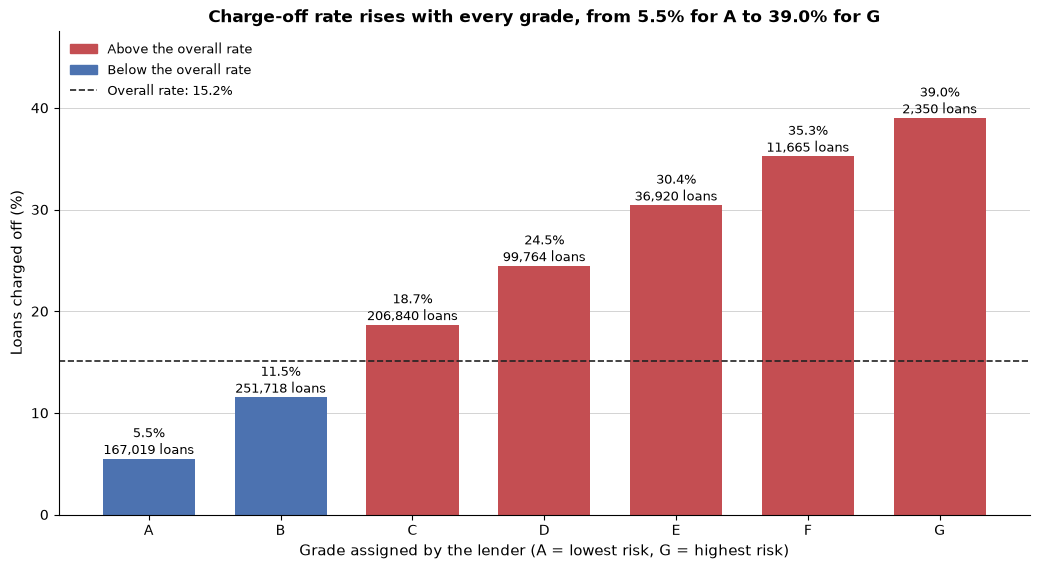

In [147]:
# Stage 4, Step 9 - Chart 1 of 8: grade
# Question: do the lender's own grades line up with how the loans actually ended?
# Chart type: columns in grade order (categorical x outcome), because the grades have a natural order.
grade_rates = rate_table(loans['grade'])
display(Markdown('**Question: do the lender\'s own grades line up with how the loans actually ended?**<br>'
                 'Each bar is the share of loans in that grade that were charged off. This is the benchmark any model has to beat: '
                 'the grade is the lender\'s own risk verdict.'))
draw_rate_bars(grade_rates,
               'Charge-off rate rises with every grade, from {:.1f}% for A to {:.1f}% for G'.format(grade_rates.loc['A', 'rate'], grade_rates.loc['G', 'rate']),
               'Grade assigned by the lender (A = lowest risk, G = highest risk)')

**Question: do longer loans end in charge-off more often?**

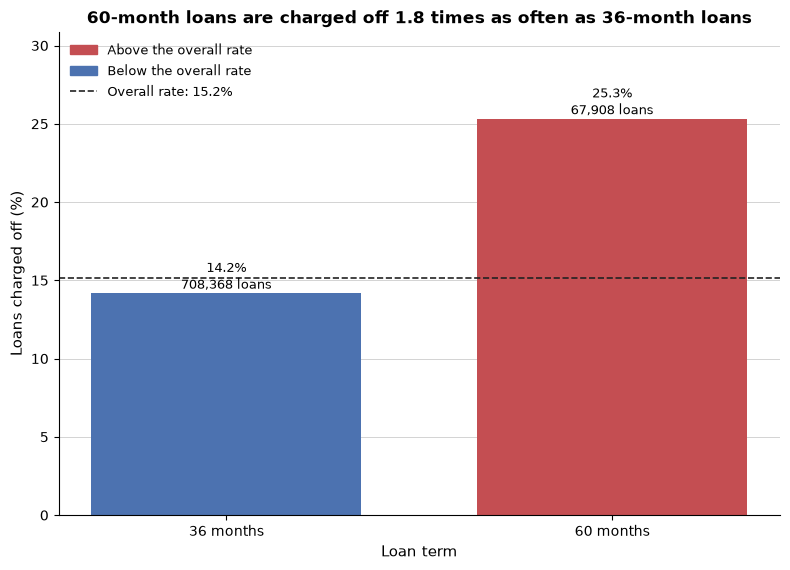

In [148]:
# Stage 4, Step 9 - Chart 2 of 8: loan term
# Question: do longer loans end in charge-off more often?
# Chart type: two columns (categorical x outcome).
term_rates = rate_table(loans['term'].map(lambda t: '{} months'.format(t)), order=['36 months', '60 months'])
display(Markdown('**Question: do longer loans end in charge-off more often?**'))
draw_rate_bars(term_rates,
               '60-month loans are charged off {:.1f} times as often as 36-month loans'.format(term_rates.loc['60 months', 'rate'] / term_rates.loc['36 months', 'rate']),
               'Loan term', figsize=(8, 5.8))

**Question: does the borrower's housing situation relate to the outcome?**

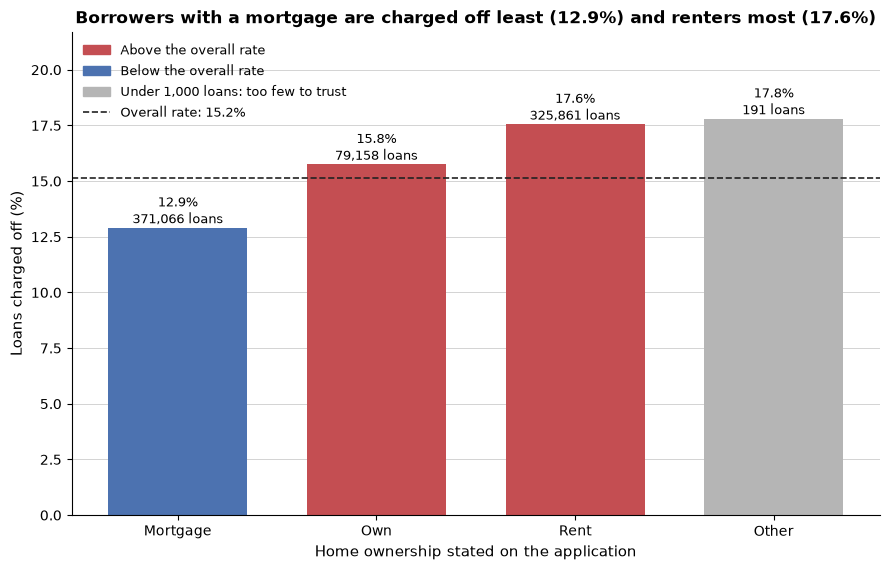

In [149]:
# Stage 4, Step 9 - Chart 3 of 8: home ownership
# Question: does the borrower's housing situation relate to the outcome?
# Chart type: columns sorted from lowest to highest rate (categorical x outcome, no natural order).
home_rates = rate_table(loans['home_ownership'].str.capitalize()).sort_values('rate')
compare = home_rates[home_rates['enough']]
who = {'Mortgage': 'borrowers with a mortgage', 'Rent': 'renters', 'Own': 'outright owners'}
display(Markdown('**Question: does the borrower\'s housing situation relate to the outcome?**'))
draw_rate_bars(home_rates,
               '{} are charged off least ({:.1f}%) and {} most ({:.1f}%)'.format(
                   who[compare.index[0]].capitalize(), compare['rate'].iloc[0], who[compare.index[-1]], compare['rate'].iloc[-1]),
               'Home ownership stated on the application', figsize=(9, 5.8))

**Question: does time in the job relate to the outcome, and what about borrowers who gave no answer?**

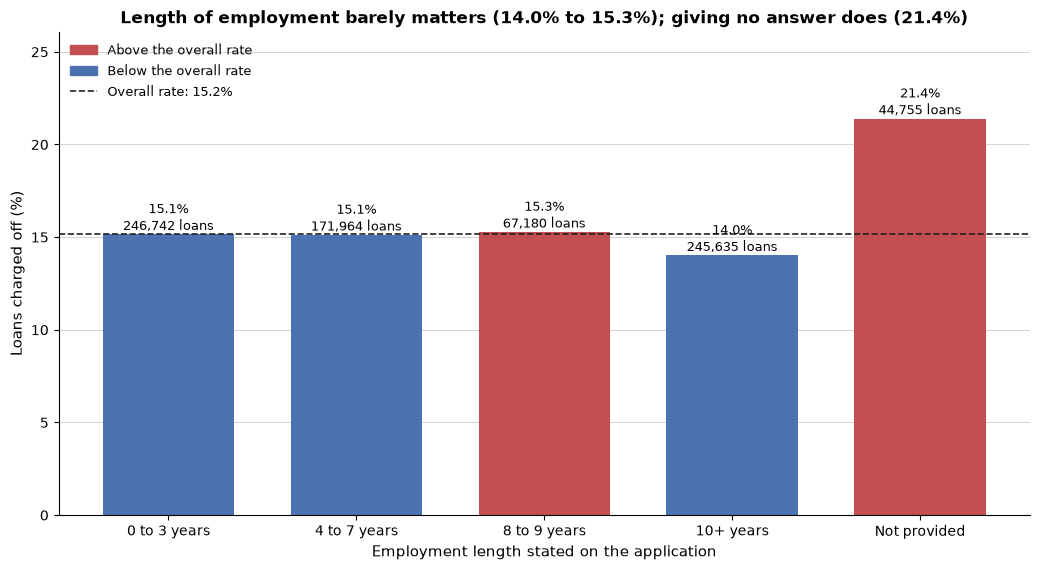

In [150]:
# Stage 4, Step 9 - Chart 4 of 8: employment length
# Question: does time in the job relate to the outcome, and what about borrowers who gave no answer?
# Chart type: columns in order of years, using the same five bins as the Stage 2 chart (categorical x outcome).
emp_bins = {'< 1 year': '0 to 3 years', '1 year': '0 to 3 years', '2 years': '0 to 3 years', '3 years': '0 to 3 years',
            '4 years': '4 to 7 years', '5 years': '4 to 7 years', '6 years': '4 to 7 years', '7 years': '4 to 7 years',
            '8 years': '8 to 9 years', '9 years': '8 to 9 years', '10+ years': '10+ years', 'Not provided': 'Not provided'}
emp_rates = rate_table(loans['emp_length'].map(emp_bins), order=['0 to 3 years', '4 to 7 years', '8 to 9 years', '10+ years', 'Not provided'])
stated = emp_rates.drop('Not provided')
display(Markdown('**Question: does time in the job relate to the outcome, and what about borrowers who gave no answer?**'))
draw_rate_bars(emp_rates,
               'Length of employment barely matters ({:.1f}% to {:.1f}%); giving no answer does ({:.1f}%)'.format(
                   stated['rate'].min(), stated['rate'].max(), emp_rates.loc['Not provided', 'rate']),
               'Employment length stated on the application')

**Question: are some loan purposes riskier than others?**<br>Grey bars are purposes with under 1,000 loans; their rates are too unstable to compare.

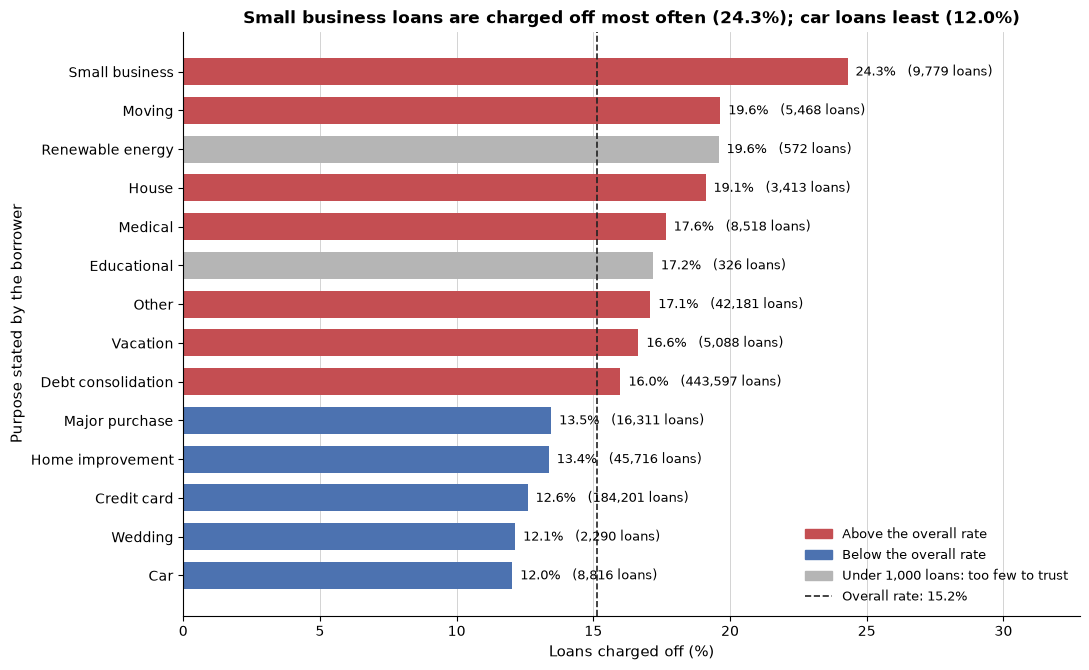

In [151]:
# Stage 4, Step 9 - Chart 5 of 8: purpose
# Question: are some loan purposes riskier than others?
# Chart type: bars sorted from highest to lowest rate and drawn sideways (categorical x outcome, 14 categories with long names).
purpose_rates = rate_table(loans['purpose'].str.replace('_', ' ').str.capitalize()).sort_values('rate', ascending=False)
compare = purpose_rates[purpose_rates['enough']]
display(Markdown('**Question: are some loan purposes riskier than others?**<br>'
                 'Grey bars are purposes with under 1,000 loans; their rates are too unstable to compare.'))
draw_rate_bars(purpose_rates,
               '{} loans are charged off most often ({:.1f}%); {} loans least ({:.1f}%)'.format(
                   compare.index[0], compare['rate'].iloc[0], compare.index[-1].lower(), compare['rate'].iloc[-1]),
               'Purpose stated by the borrower', horizontal=True, figsize=(11, 6.8))

**Question: does a higher credit score at application mean fewer charge-offs?**<br>Scores start at 660 because the lender approves almost nobody below it.

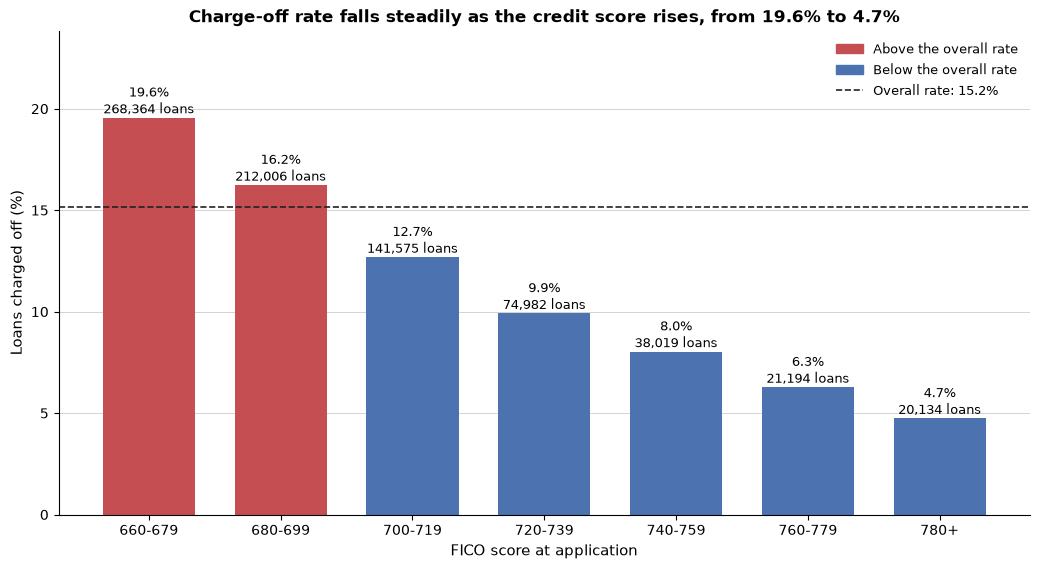

In [152]:
# Stage 4, Step 9 - Chart 6 of 8: credit score
# Question: does a higher credit score at application mean fewer charge-offs?
# Chart type: columns by score band (numeric x outcome, with the numeric column cut into bands so a rate can be shown).
bands = [660, 680, 700, 720, 740, 760, 780, 851]
band_labels = ['660-679', '680-699', '700-719', '720-739', '740-759', '760-779', '780+']
fico_rates = rate_table(pd.cut(loans['fico_avg'], bins=bands, labels=band_labels, right=False), order=band_labels)
display(Markdown('**Question: does a higher credit score at application mean fewer charge-offs?**<br>'
                 'Scores start at 660 because the lender approves almost nobody below it.'))
draw_rate_bars(fico_rates,
               'Charge-off rate falls steadily as the credit score rises, from {:.1f}% to {:.1f}%'.format(fico_rates['rate'].iloc[0], fico_rates['rate'].iloc[-1]),
               'FICO score at application')

**Question: are borrowers who already carry more debt, relative to income, charged off more often?**

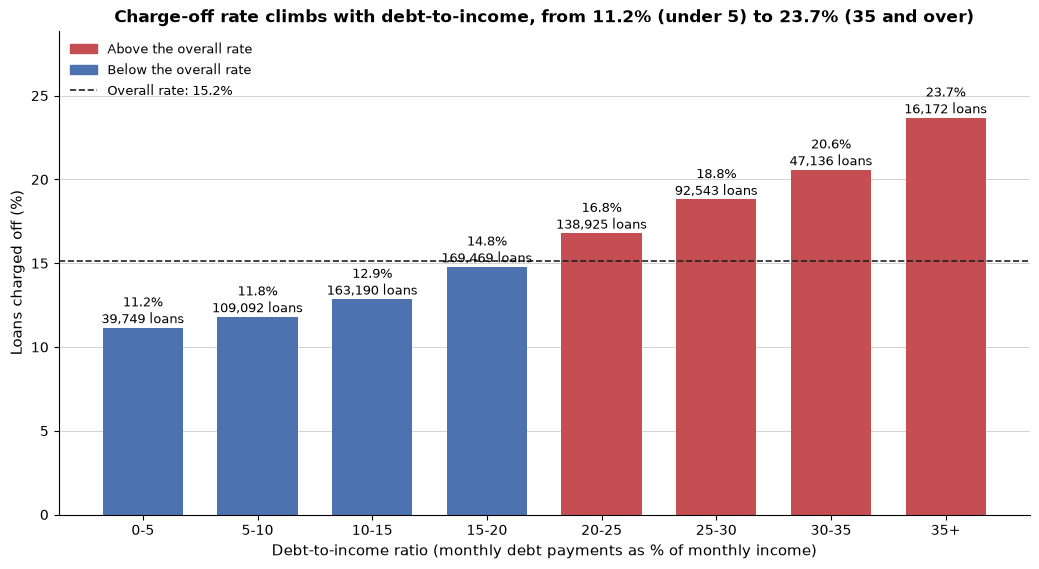

In [153]:
# Stage 4, Step 9 - Chart 7 of 8: debt-to-income
# Question: are borrowers who already carry more debt, relative to income, charged off more often?
# Chart type: columns by debt-to-income band (numeric x outcome, cut into 5-point bands).
edges = [0, 5, 10, 15, 20, 25, 30, 35, 100]
dti_labels = ['0-5', '5-10', '10-15', '15-20', '20-25', '25-30', '30-35', '35+']
dti_rates = rate_table(pd.cut(loans['dti_combined'], bins=edges, labels=dti_labels, right=False), order=dti_labels)
display(Markdown('**Question: are borrowers who already carry more debt, relative to income, charged off more often?**'))
draw_rate_bars(dti_rates,
               'Charge-off rate climbs with debt-to-income, from {:.1f}% (under 5) to {:.1f}% (35 and over)'.format(dti_rates['rate'].iloc[0], dti_rates['rate'].iloc[-1]),
               'Debt-to-income ratio (monthly debt payments as % of monthly income)')

C:\Users\dhruv\AppData\Local\Temp\ipykernel_47968\2154551683.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot([charged, paid], vert=False, showfliers=False, widths=0.55, patch_artist=True,


**Question: do charged-off borrowers earn less than borrowers who repaid?**<br>Each box covers the middle half of incomes in that group; the line inside is the median; the whiskers reach 1.5 x IQR beyond the box.

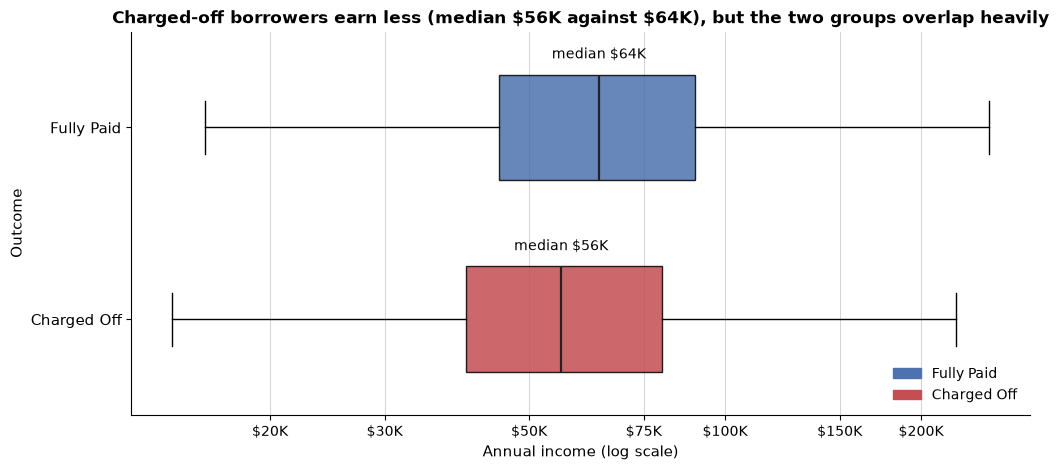

In [154]:
# Stage 4, Step 9 - Chart 8 of 8: income
# Question: do charged-off borrowers earn less than borrowers who repaid?
# Chart type: two box plots on a log scale (numeric x outcome). Stage 3 showed income needs a log scale to be readable.
# Outlier points are not drawn: with this many loans they would hide the boxes.
from matplotlib.patches import Patch

def dollars(value):
    return '${:,.0f}K'.format(value / 1000) if value < 1e6 else '${:.1f}M'.format(value / 1e6)

paid = np.log10(loans.loc[loans['charged_off'] == 0, 'annual_inc_combined'])
charged = np.log10(loans.loc[loans['charged_off'] == 1, 'annual_inc_combined'])
median_paid, median_charged = 10 ** paid.median(), 10 ** charged.median()

fig, ax = plt.subplots(figsize=(10.5, 4.8))
boxes = ax.boxplot([charged, paid], vert=False, showfliers=False, widths=0.55, patch_artist=True,
                   medianprops={'color': '#222222', 'linewidth': 1.6})
for box, color in zip(boxes['boxes'], ['#c44e52', '#4c72b0']):
    box.set_facecolor(color)
    box.set_alpha(0.85)
ax.set_yticks([1, 2])
ax.set_yticklabels(['Charged Off', 'Fully Paid'], fontsize=11)
ticks = [20000, 30000, 50000, 75000, 100000, 150000, 200000]
ax.set_xticks(np.log10(ticks))
ax.set_xticklabels([dollars(t) for t in ticks])
ax.text(np.log10(median_charged), 1.36, 'median ' + dollars(median_charged), ha='center', fontsize=10)
ax.text(np.log10(median_paid), 2.36, 'median ' + dollars(median_paid), ha='center', fontsize=10)
ax.set_xlabel('Annual income (log scale)', fontsize=11)
ax.set_ylabel('Outcome', fontsize=11)
ax.xaxis.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
ax.set_title('Charged-off borrowers earn less (median {} against {}), but the two groups overlap heavily'.format(
    dollars(median_charged), dollars(median_paid)), fontsize=12.5, fontweight='bold', parse_math=False)
ax.legend(handles=[Patch(color='#4c72b0', label='Fully Paid'), Patch(color='#c44e52', label='Charged Off')],
          frameon=False, fontsize=10, loc='lower right')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
display(Markdown('**Question: do charged-off borrowers earn less than borrowers who repaid?**<br>'
                 'Each box covers the middle half of incomes in that group; the line inside is the median; the whiskers reach 1.5 x IQR beyond the box.'))
plt.tight_layout()
plt.show()

# Multivariate

**Question: which numeric features move together, and which move with the outcome?**<br>The outlined first column shows each feature against the outcome. The strongest pair of features is monthly payment and loan amount (+0.98), which means the two carry nearly the same information.

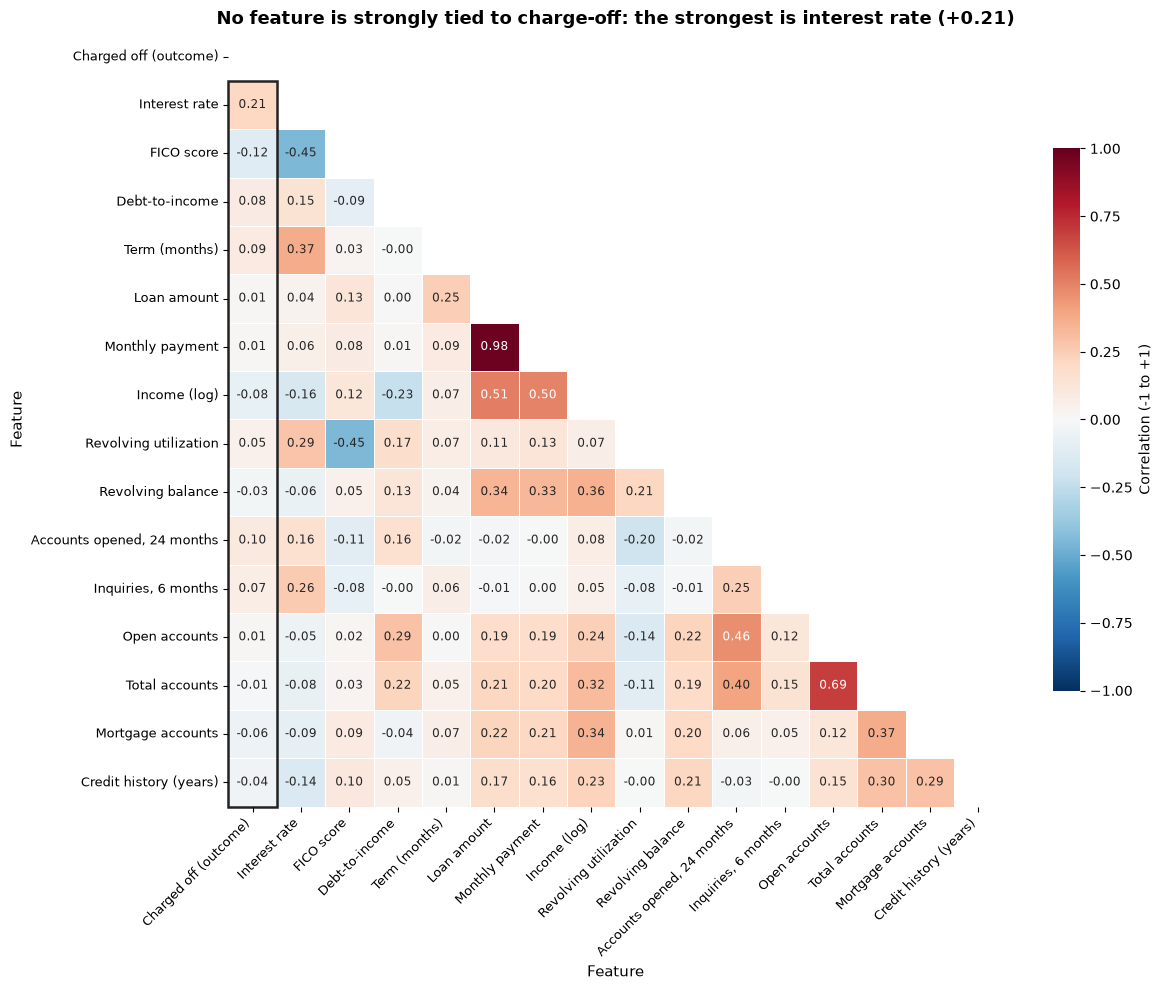

In [162]:
# Stage 5, Step 10 - Chart 1 of 4: correlation heatmap
# Question: which numeric features move together, and which move with the outcome?
# Chart type: a heatmap of correlations (a grid well over 5 x 5), with a diverging palette centred on zero:
#   red = the two columns rise together, blue = one rises as the other falls, white = no linear relationship.
# Income is used on a log scale, as Stage 3 showed it should be. Only the lower triangle is drawn; the upper half would repeat it.
import seaborn as sns
from matplotlib.patches import Rectangle

heat_cols = {'charged_off': 'Charged off (outcome)', 'int_rate': 'Interest rate', 'fico_avg': 'FICO score', 'dti_combined': 'Debt-to-income',
             'term': 'Term (months)', 'loan_amnt': 'Loan amount', 'installment': 'Monthly payment', 'log_income': 'Income (log)',
             'revol_util': 'Revolving utilization', 'revol_bal': 'Revolving balance', 'acc_open_past_24mths': 'Accounts opened, 24 months',
             'inq_last_6mths': 'Inquiries, 6 months', 'open_acc': 'Open accounts', 'total_acc': 'Total accounts',
             'mort_acc': 'Mortgage accounts', 'credit_history_years': 'Credit history (years)'}
heat_data = loans.assign(log_income=np.log10(loans['annual_inc_combined']))[list(heat_cols)].rename(columns=heat_cols)
corr = heat_data.corr()
with_outcome = corr['Charged off (outcome)'].drop('Charged off (outcome)')
pairs = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).drop(index='Charged off (outcome)', columns='Charged off (outcome)').stack()
top_pair = pairs.abs().idxmax()

fig, ax = plt.subplots(figsize=(12.5, 10))
sns.heatmap(corr, mask=np.triu(np.ones(corr.shape, dtype=bool)), cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'fontsize': 8.5}, linewidths=0.5, linecolor='white', square=True,
            cbar_kws={'label': 'Correlation (-1 to +1)', 'shrink': 0.7}, ax=ax)
# Outline the outcome column: it is the one the project is about
ax.add_patch(Rectangle((0, 1), 1, len(corr) - 1, fill=False, edgecolor='#222222', linewidth=1.8, clip_on=False))
ax.set_xlabel('Feature', fontsize=11)
ax.set_ylabel('Feature', fontsize=11)
ax.tick_params(axis='x', labelrotation=45, labelsize=9.5)
plt.setp(ax.get_xticklabels(), ha='right')
ax.tick_params(axis='y', labelsize=9.5)
ax.set_title('No feature is strongly tied to charge-off: the strongest is {} ({:+.2f})'.format(
    with_outcome.abs().idxmax().lower(), with_outcome[with_outcome.abs().idxmax()]), fontsize=13, fontweight='bold')
display(Markdown('**Question: which numeric features move together, and which move with the outcome?**<br>'
                 'The outlined first column shows each feature against the outcome. The strongest pair of features is {} and {} ({:+.2f}), '
                 'which means the two carry nearly the same information.'.format(top_pair[0].lower(), top_pair[1].lower(), pairs[top_pair])))
plt.tight_layout()
plt.show()

**Question: do longer loans still fail more often once the lender's grade is held constant?**<br>Across all loans, 60-month loans are charged off 11.1 points more often. Among loans of the same grade the gap is 3.2 points on average (weighted by the number of loans), and 60-month loans are higher in 6 of 7 grades. So most of the term effect is that longer loans get worse grades, and a smaller part is the term itself. Smallest group shown: 757 loans.

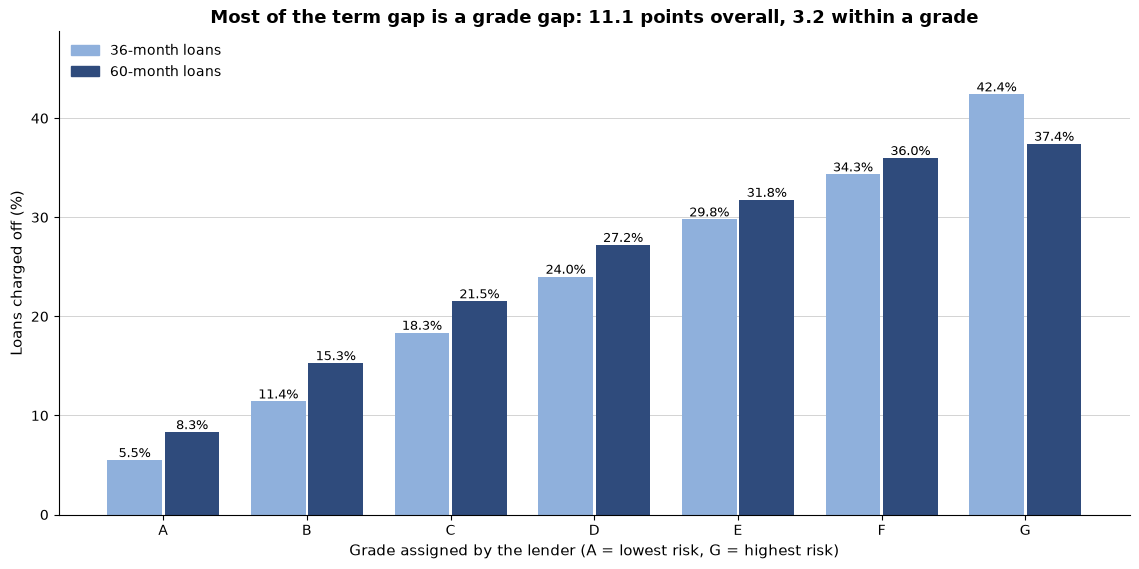

In [163]:
# Stage 5, Step 10 - Chart 2 of 4: term within each grade
# Question: do longer loans still fail more often once the lender's grade is held constant?
# Chart type: grouped columns, one pair per grade (two categories compared within a third).
# Stage 4 showed 60-month loans fail more often, but they also get worse grades. This separates the two.
from matplotlib.patches import Patch

by_grade_term = loans.groupby(['grade', 'term'])['charged_off'].agg(['size', 'mean'])
rates = (by_grade_term['mean'] * 100).unstack('term')
sizes = by_grade_term['size'].unstack('term')
gap = rates[60] - rates[36]
raw_gap = loans.groupby('term')['charged_off'].mean().mul(100).diff().iloc[-1]
weights = sizes.sum(axis=1)
avg_gap = (gap * weights).sum() / weights.sum()          # average gap within a grade, weighted by the number of loans
x = np.arange(len(rates))

fig, ax = plt.subplots(figsize=(11.5, 5.8))
ax.bar(x - 0.2, rates[36], width=0.38, color='#8fb0dc')
ax.bar(x + 0.2, rates[60], width=0.38, color='#2f4b7c')
for i in range(len(rates)):
    ax.text(i - 0.2, rates[36].iloc[i], '{:.1f}%'.format(rates[36].iloc[i]), ha='center', va='bottom', fontsize=9)
    ax.text(i + 0.2, rates[60].iloc[i], '{:.1f}%'.format(rates[60].iloc[i]), ha='center', va='bottom', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(rates.index)
ax.set_ylim(0, rates.max().max() * 1.15)
ax.set_xlabel('Grade assigned by the lender (A = lowest risk, G = highest risk)', fontsize=11)
ax.set_ylabel('Loans charged off (%)', fontsize=11)
ax.yaxis.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
higher = int((gap > 0).sum())
ax.set_title('Most of the term gap is a grade gap: {:.1f} points overall, {:.1f} within a grade'.format(raw_gap, avg_gap),
             fontsize=13, fontweight='bold')
ax.legend(handles=[Patch(color='#8fb0dc', label='36-month loans'), Patch(color='#2f4b7c', label='60-month loans')],
          frameon=False, fontsize=10, loc='upper left')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
display(Markdown('**Question: do longer loans still fail more often once the lender\'s grade is held constant?**<br>'
                 'Across all loans, 60-month loans are charged off {:.1f} points more often. Among loans of the same grade the gap is {:.1f} points '
                 'on average (weighted by the number of loans), and 60-month loans are higher in {} of {} grades. '
                 'So most of the term effect is that longer loans get worse grades, and a smaller part is the term itself. '
                 'Smallest group shown: {:,} loans.'.format(raw_gap, avg_gap, higher, len(gap), int(sizes.min().min()))))
plt.tight_layout()
plt.show()

**Question: loans with verified income fail more often. Is that still true among loans of the same grade?**<br>The gap is Verified minus Not Verified. "Within a grade" is the average gap across the seven grades, weighted by the number of loans. Smallest group shown: 96 loans.

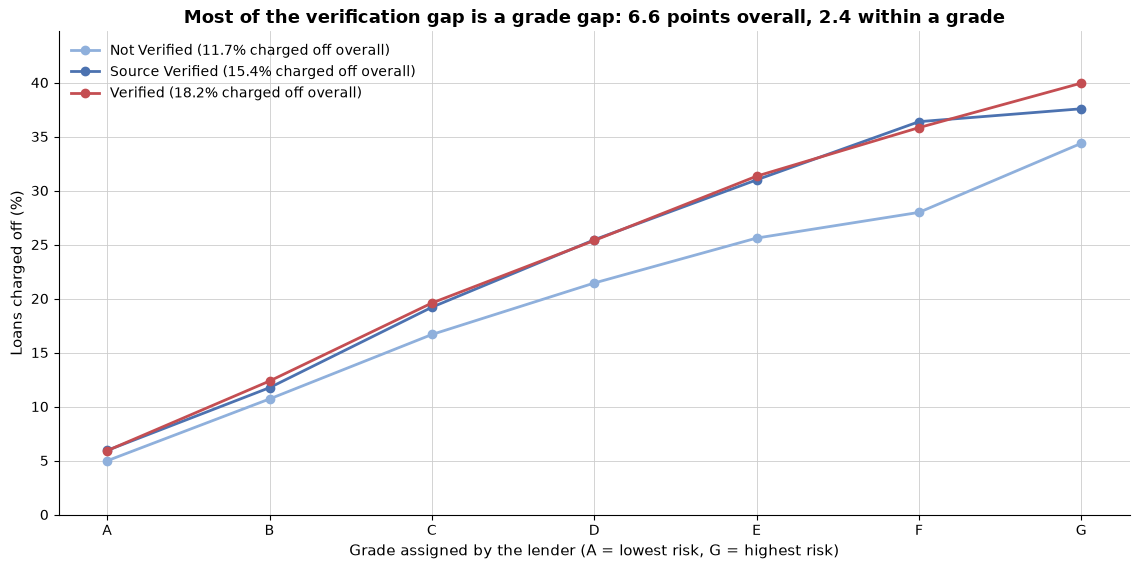

In [164]:
# Stage 5, Step 10 - Chart 3 of 4: income verification within each grade
# Question: Stage 4 found that loans with verified income fail MORE often. Is that still true among loans of the same grade?
# Chart type: one line per verification status across the grades (three categories compared within a fourth).
# If the lines sit on top of each other, the verification gap was really a grade gap.
from matplotlib.lines import Line2D

status_order = ['Not Verified', 'Source Verified', 'Verified']
status_colors = {'Not Verified': '#8fb0dc', 'Source Verified': '#4c72b0', 'Verified': '#c44e52'}
by_grade_status = loans.groupby(['grade', 'verification_status'])['charged_off'].agg(['size', 'mean'])
rates = (by_grade_status['mean'] * 100).unstack('verification_status')[status_order]
sizes = by_grade_status['size'].unstack('verification_status')[status_order]
overall = loans.groupby('verification_status')['charged_off'].mean().mul(100)
raw_gap = overall['Verified'] - overall['Not Verified']
within_gap = rates['Verified'] - rates['Not Verified']
weights = sizes.sum(axis=1)
avg_within = (within_gap * weights).sum() / weights.sum()

fig, ax = plt.subplots(figsize=(11.5, 5.8))
for status in status_order:
    ax.plot(rates.index, rates[status], marker='o', linewidth=2, color=status_colors[status])
ax.set_ylim(0, rates.max().max() * 1.12)
ax.set_xlabel('Grade assigned by the lender (A = lowest risk, G = highest risk)', fontsize=11)
ax.set_ylabel('Loans charged off (%)', fontsize=11)
ax.grid(True, color='#cccccc', linewidth=0.6)
ax.set_axisbelow(True)
if avg_within < raw_gap / 2:
    title = 'Most of the verification gap is a grade gap: {:.1f} points overall, {:.1f} within a grade'.format(raw_gap, avg_within)
else:
    title = 'The verification gap survives within a grade: {:.1f} points overall, {:.1f} within a grade'.format(raw_gap, avg_within)
ax.set_title(title, fontsize=13, fontweight='bold')
ax.legend(handles=[Line2D([0], [0], color=status_colors[s], marker='o', linewidth=2,
                          label='{} ({:.1f}% charged off overall)'.format(s, overall[s])) for s in status_order],
          frameon=False, fontsize=10, loc='upper left')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
display(Markdown('**Question: loans with verified income fail more often. Is that still true among loans of the same grade?**<br>'
                 'The gap is Verified minus Not Verified. "Within a grade" is the average gap across the seven grades, weighted by the number of loans. '
                 'Smallest group shown: {:,} loans.'.format(int(sizes.min().min()))))
plt.tight_layout()
plt.show()

**Question: how do the two strongest features outside the lender's rating combine?**<br>Each cell is the share of loans charged off for that combination of credit score and debt-to-income. Reading along a row holds the credit score constant; reading down a column holds debt-to-income constant. Blank cells have under 1,000 loans.

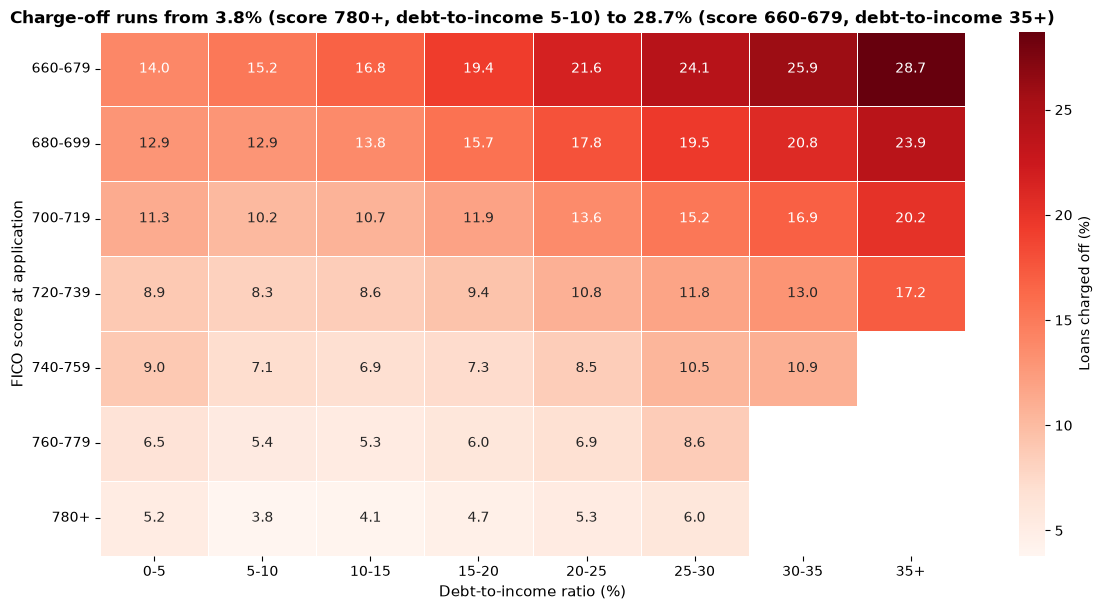

In [165]:
# Stage 5, Step 10 - Chart 4 of 4: credit score and debt-to-income together
# Question: how do the two strongest features outside the lender's rating combine?
# Chart type: a heatmap of charge-off rate (two banded numeric columns against the outcome), with a single-colour scale:
#   the darker the cell, the higher the share of loans charged off.
import seaborn as sns

fico_labels = ['660-679', '680-699', '700-719', '720-739', '740-759', '760-779', '780+']
dti_labels = ['0-5', '5-10', '10-15', '15-20', '20-25', '25-30', '30-35', '35+']
fico_band = pd.cut(loans['fico_avg'], bins=[660, 680, 700, 720, 740, 760, 780, 851], labels=fico_labels, right=False)
dti_band = pd.cut(loans['dti_combined'], bins=[0, 5, 10, 15, 20, 25, 30, 35, 100], labels=dti_labels, right=False)
cell = loans.groupby([fico_band, dti_band])['charged_off'].agg(['size', 'mean'])
grid = (cell['mean'] * 100).unstack().reindex(index=fico_labels, columns=dti_labels)
counts = cell['size'].unstack().reindex(index=fico_labels, columns=dti_labels)
grid = grid.where(counts >= 1000)            # cells under 1,000 loans are left blank

fig, ax = plt.subplots(figsize=(12, 6.2))
sns.heatmap(grid, cmap='Reds', annot=True, fmt='.1f', annot_kws={'fontsize': 10}, linewidths=0.6, linecolor='white',
            cbar_kws={'label': 'Loans charged off (%)'}, ax=ax)
ax.set_xlabel('Debt-to-income ratio (%)', fontsize=11)
ax.set_ylabel('FICO score at application', fontsize=11)
ax.tick_params(axis='y', labelrotation=0)
cells_ranked = grid.stack()
low_cell, high_cell = cells_ranked.idxmin(), cells_ranked.idxmax()
ax.set_title('Charge-off runs from {:.1f}% (score {}, debt-to-income {}) to {:.1f}% (score {}, debt-to-income {})'.format(
    cells_ranked.min(), low_cell[0], low_cell[1], cells_ranked.max(), high_cell[0], high_cell[1]), fontsize=12.5, fontweight='bold')
display(Markdown('**Question: how do the two strongest features outside the lender\'s rating combine?**<br>'
                 'Each cell is the share of loans charged off for that combination of credit score and debt-to-income. '
                 'Reading along a row holds the credit score constant; reading down a column holds debt-to-income constant. '
                 'Blank cells have under 1,000 loans.'))
plt.tight_layout()
plt.show()

In [166]:
# Stage 5, Step 11 - Feature selection: which columns go into the model?
# Question: of the 76 columns in the cleaned data, which ones are usable features?
# Every column gets a role and a reason. The rules, applied in this order:
#   1. the target, and columns that repeat it;
#   2. the lender's own rating (PROPOSAL, not yet confirmed: set use_lender_rating = True to keep these as features);
#   3. columns replaced by a derived column;
#   4. columns that are nearly one value (the most common value covers at least 98% of loans);
#   5. location codes with too many categories for a first model;
#   6. numeric columns that nearly duplicate another one (correlation above 0.90): the one less related to the outcome is dropped.
use_lender_rating = False

roles = {}
roles['charged_off'] = ('target', 'the outcome to predict')
roles['loan_status'] = ('not a feature', 'repeats the target')
for col in ('grade', 'sub_grade', 'int_rate', 'installment'):
    if not use_lender_rating:
        roles[col] = ('not a feature', 'lender\'s own risk rating: kept as the benchmark, not as an input')
for col, new in (('issue_d', 'issue_year'), ('earliest_cr_line', 'credit_history_years'), ('fico_range_low', 'fico_avg'),
                 ('fico_range_high', 'fico_avg'), ('emp_length', 'emp_length_years and emp_length_not_provided')):
    roles[col] = ('not a feature', 'replaced by ' + new)
roles['issue_year'] = ('not a feature', 'the year of issue is not known in advance for a future loan')
roles['zip_code'] = ('not a feature', '924 categories: kept for a map, too many for a first model')

remaining = [col for col in loans.columns if col not in roles]
for col in remaining:
    top_share = loans[col].value_counts(normalize=True).iloc[0]
    if top_share >= 0.98:
        roles[col] = ('not a feature', 'nearly one value: {:.1f}% of loans share it'.format(top_share * 100))

# Near-duplicate numeric columns: for each pair above 0.90, drop the one less related to the outcome
candidates = [col for col in loans.columns if col not in roles]
numeric_candidates = loans[candidates].select_dtypes(include='number').columns
corr_all = loans[numeric_candidates].corr().abs()
with_target = loans[numeric_candidates].corrwith(loans['charged_off']).abs()
duplicate_pairs = []
for i, a in enumerate(numeric_candidates):
    for b in numeric_candidates[i + 1:]:
        if corr_all.loc[a, b] > 0.90:
            duplicate_pairs.append((a, b, corr_all.loc[a, b]))
for a, b, r in sorted(duplicate_pairs, key=lambda p: -p[2]):
    if a in roles or b in roles:
        continue
    drop, keep = (a, b) if with_target[a] < with_target[b] else (b, a)
    roles[drop] = ('not a feature', 'near-duplicate of {} (correlation {:.2f})'.format(keep, r))

for col in loans.columns:
    if col not in roles:
        roles[col] = ('feature', '')
selection = pd.DataFrame(roles, index=['role', 'reason']).T.reindex(loans.columns)
selection.index.name = 'column'
model_features = list(selection.index[selection['role'] == 'feature'])

pair_table = pd.DataFrame(sorted(duplicate_pairs, key=lambda p: -p[2]), columns=['column', 'near-duplicate of', 'correlation']).round(3)
display(Markdown('**Table 27. Pairs of numeric columns that nearly duplicate each other (correlation above 0.90)**'))
display(pair_table)

def reason_group(reason):
    for start in ('nearly one value', 'replaced by', 'near-duplicate', 'lender'):
        if reason.startswith(start):
            return {'nearly one value': 'nearly one value (98% or more of loans share it)', 'replaced by': 'replaced by a derived column',
                    'near-duplicate': 'near-duplicate of another column (correlation above 0.90)',
                    'lender': 'lender rating: benchmark, not an input (proposal)'}[start]
    return reason

reason_summary = selection[selection['role'] == 'not a feature']['reason'].map(reason_group).value_counts().to_frame('columns')
reason_summary.index.name = 'why it is not a feature'
display(Markdown('**Table 28. Columns left out of the model, by reason**<br>'
                 'Out of {} columns: 1 target, {} features, {} left out. '
                 'The lender\'s rating columns are left out as a proposal that still needs confirming.'.format(
                     len(selection), len(model_features), int((selection['role'] == 'not a feature').sum()))))
with pd.option_context('display.max_colwidth', None):
    display(reason_summary)
    display(Markdown('**Table 29. Every column left out, with its reason**'))
    display(selection[selection['role'] == 'not a feature'][['reason']])
print('Features kept ({}):'.format(len(model_features)))
print(model_features)

**Table 27. Pairs of numeric columns that nearly duplicate each other (correlation above 0.90)**

,column,near-duplicate of,correlation
0,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.984
1,open_acc,num_sats,0.973
2,tot_cur_bal,tot_hi_cred_lim,0.972


**Table 28. Columns left out of the model, by reason**<br>Out of 76 columns: 1 target, 52 features, 23 left out. The lender's rating columns are left out as a proposal that still needs confirming.

,columns
why it is not a feature,
nearly one value (98% or more of loans share it),8
replaced by a derived column,5
"lender rating: benchmark, not an input (proposal)",4
near-duplicate of another column (correlation above 0.90),3
repeats the target,1
"924 categories: kept for a map, too many for a first model",1
the year of issue is not known in advance for a future loan,1


**Table 29. Every column left out, with its reason**

,reason
column,
int_rate,"lender's own risk rating: kept as the benchmark, not as an input"
installment,"lender's own risk rating: kept as the benchmark, not as an input"
grade,"lender's own risk rating: kept as the benchmark, not as an input"
sub_grade,"lender's own risk rating: kept as the benchmark, not as an input"
emp_length,replaced by emp_length_years and emp_length_not_provided
issue_d,replaced by issue_year
loan_status,repeats the target
zip_code,"924 categories: kept for a map, too many for a first model"
earliest_cr_line,replaced by credit_history_years


Features kept (52):
['loan_amnt', 'term', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'delinq_2yrs', 'inq_last_6mths', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'tot_coll_amt', 'total_rev_hi_lim', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util', 'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl', 'mort_acc', 'mths_since_recent_bc', 'mths_since_recent_inq', 'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_bc_sats', 'num_bc_tl', 'num_il_tl', 'num_op_rev_tl', 'num_rev_accts', 'num_rev_tl_bal_gt_0', 'num_sats', 'num_tl_90g_dpd_24m', 'num_tl_op_past_12m', 'pct_tl_nvr_dlq', 'percent_bc_gt_75', 'pub_rec_bankruptcies', 'tax_liens', 'tot_hi_cred_lim', 'total_bal_ex_mort', 'total_bc_limit', 'total_il_high_credit_limit', 'annual_inc_combined', 'dti_combined', 'bureau_not_collected', 'emp_length_not_provided', 'emp_length_years', 'credit_history_years', 'fico_avg']


In [167]:
# Stage 6, Step 12 - The decision table
# Question: what does someone need to know to start building a model from this data without asking us anything?
# This is the output of the whole EDA: every issue found, what was decided, and why.
# The numbers were measured in the steps named in the last column; the check at the end compares the key ones with the data in memory.
decisions = [
    # (stage, column or issue, decision, because, where it was measured)
    ('Rows', '33 junk rows', 'Drop', 'They are summary lines, not loans; only id holds a value', 'Step 2'),
    ('Rows', 'Loans still open: Current, Late, In Grace Period, Default (912,609)', 'Drop', 'No final outcome; a target cannot be imputed', 'Steps 3-4'),
    ('Rows', '"Does not meet the credit policy" loans (2,749)', 'Drop', 'Approved under older credit rules, so a different population', 'Step 4'),
    ('Rows', 'Finished loans too young to be a fair sample (569,034)', 'Drop: keep a loan only if its full term had passed by March 2019',
     'Recent loans that already finished ended early; keeping them inflated the charge-off rate from 15.2% to 20.0%', 'Step 4'),
    ('Target', 'loan_status', 'Build charged_off: 1 = Charged Off, 0 = Fully Paid', '658,666 fully paid and 117,610 charged off (15.2%)', 'Step 4'),
    ('Columns', '58 columns more than 30% empty', 'Drop', 'Hardship, settlement, joint and newer credit-bureau fields are 51% to 100% empty on the loans kept', 'Step 5'),
    ('Columns', '17 columns recorded after the loan was issued', 'Drop', 'Leakage: money recovered on 78.7% of charged-off loans and 0.0% of fully paid ones', 'Step 5'),
    ('Columns', 'emp_title, title', 'Drop', 'Hand-typed: 272,023 and 61,678 distinct values; title repeats purpose', 'Step 5'),
    ('Columns', 'id, url, policy_code', 'Drop', 'Identifiers and a column with one value', 'Step 5'),
    ('Columns', 'funded_amnt, funded_amnt_inv', 'Drop', 'Near-copies of loan_amnt (equal on 99.75% and 89.23% of loans)', 'Step 5'),
    ('Columns', 'zip_code, addr_state', 'Keep', 'Charge-off rate varies by place (9.7% to 19.6% across states)', 'Step 5'),
    ('Values', 'annual_inc and dti on joint applications (1,627 loans)', 'Replace with the joint figures: annual_inc_combined, dti_combined',
     'Zero incomes and dti above 100 were all joint applications judged on the joint figures', 'Steps 2 and 5'),
    ('Values', '39 numeric columns 0.01% to 16% missing', 'Fill with the median if skewed, the mean if roughly symmetric; mark the loans in bureau_not_collected',
     'The fields did not exist before 2012; 35 are skewed (mean pulled toward the tail), 4 are symmetric', 'Step 5'),
    ('Values', 'emp_length missing on 44,755 loans', 'Keep as its own group, "Not provided", with a marker column', 'That group charges off at 21.4%, against about 15% for every stated length', 'Step 5'),
    ('Values', 'term, emp_length, issue_d, earliest_cr_line stored as text', 'Convert to numbers and dates', 'describe() and charts cannot use text', 'Step 5'),
    ('Values', 'dti placeholders 999 and -1', 'Treat as missing and fill', 'Not real ratios; one loan left after the earlier filters', 'Steps 2 and 5'),
    ('Values', 'home_ownership ANY and NONE', 'Merge into OTHER', '191 loans in total, from older versions of the form', 'Step 5'),
    ('Features', 'issue_d, earliest_cr_line, FICO range', 'Derive credit_history_years, fico_avg, issue_year', 'A date is not a feature; the time between two dates is', 'Step 5'),
    ('Features', 'annual_inc_combined', 'Use on a log scale', 'Skew 42.65 on the plain scale, 0.21 after a log; the QQ plot follows the normal line', 'Step 8'),
    ('Features', '8 columns that are nearly one value', 'Leave out of the model', '98% or more of loans share the same value', 'Step 11'),
    ('Features', '3 near-duplicate columns', 'Leave out of the model', 'Correlation above 0.90 with a column that relates more to the outcome', 'Step 11'),
    ('Features', 'loan_status, zip_code, issue_year and 5 columns replaced by derived ones', 'Leave out of the model',
     'Repeats the target, has 924 categories, is not known in advance, or is covered by a derived column', 'Step 11'),
    ('Features', 'grade, sub_grade, int_rate, installment', 'PROPOSED: leave out of the model and use grade as the benchmark',
     'They are the lender\'s own risk verdict (5.5% charged off for A, 39.0% for G); a model using them would largely repeat it', 'Steps 9 and 11'),
    ('Model', 'Outcome is 15.2% charged off', 'Treat as an imbalanced classification problem', 'Predicting "fully paid" for everyone would be 84.8% accurate and useless', 'Steps 7 and 13'),
]
decision_table = pd.DataFrame(decisions, columns=['stage', 'column or issue', 'decision', 'because', 'measured in'])
decision_table.index = range(1, len(decision_table) + 1)
decision_table.index.name = '#'
display(Markdown('**Table 30. The decision table: every issue found, what was decided, and why**<br>'
                 'The format follows the lectures: column or issue, decision, because. One row is marked PROPOSED because the group has not confirmed it yet.'))
with pd.option_context('display.max_colwidth', None):
    display(decision_table)

# Check the headline numbers against the data in memory
print('Loans kept: {:,} (table says 776,276)'.format(len(loans)))
print('Charged off: {:,} = {:.1f}% (table says 117,610 = 15.2%)'.format(int(loans['charged_off'].sum()), loans['charged_off'].mean() * 100))
print('Columns in the cleaned data: {} (76 expected)'.format(loans.shape[1]))
if 'model_features' in globals():
    print('Features selected in Step 11: {}'.format(len(model_features)))

**Table 30. The decision table: every issue found, what was decided, and why**<br>The format follows the lectures: column or issue, decision, because. One row is marked PROPOSED because the group has not confirmed it yet.

,stage,column or issue,decision,because,measured in
#,,,,,
1,Rows,33 junk rows,Drop,"They are summary lines, not loans; only id holds a value",Step 2
2,Rows,"Loans still open: Current, Late, In Grace Period, Default (912,609)",Drop,No final outcome; a target cannot be imputed,Steps 3-4
3,Rows,"""Does not meet the credit policy"" loans (2,749)",Drop,"Approved under older credit rules, so a different population",Step 4
4,Rows,"Finished loans too young to be a fair sample (569,034)",Drop: keep a loan only if its full term had passed by March 2019,Recent loans that already finished ended early; keeping them inflated the charge-off rate from 15.2% to 20.0%,Step 4
5,Target,loan_status,"Build charged_off: 1 = Charged Off, 0 = Fully Paid","658,666 fully paid and 117,610 charged off (15.2%)",Step 4
6,Columns,58 columns more than 30% empty,Drop,"Hardship, settlement, joint and newer credit-bureau fields are 51% to 100% empty on the loans kept",Step 5
7,Columns,17 columns recorded after the loan was issued,Drop,Leakage: money recovered on 78.7% of charged-off loans and 0.0% of fully paid ones,Step 5
8,Columns,"emp_title, title",Drop,"Hand-typed: 272,023 and 61,678 distinct values; title repeats purpose",Step 5
9,Columns,"id, url, policy_code",Drop,Identifiers and a column with one value,Step 5


Loans kept: 776,276 (table says 776,276)
Charged off: 117,610 = 15.2% (table says 117,610 = 15.2%)
Columns in the cleaned data: 76 (76 expected)
Features selected in Step 11: 52


## Stage 6, Step 13: Preliminary ML direction

**Question: given what the EDA found, what kind of model should be built, and how should it be judged?**

No model has been trained. This section states the direction and the EDA evidence behind each choice.

### The task

Binary classification: predict, from information known when the loan is issued, whether it will end **Charged Off (1)** or **Fully Paid (0)**.

### Why this task, from the EDA

| EDA finding | Where | What it means for the model |
|---|---|---|
| The outcome is yes or no: 658,666 fully paid and 117,610 charged off | Steps 4 and 7 | Classification, not regression |
| Only 15.2% of loans are charged off | Step 7, chart 1 | The classes are imbalanced, about 5.6 to 1 |
| No single feature is strong: the best correlation outside the lender's rating is -0.12 (FICO) | Step 10, chart 1 | A model is needed to combine many weak signals |
| Yet groups differ a lot: credit score and debt-to-income together span 3.8% to 28.7% charged off | Step 10, chart 4 | The outcome is predictable; features interact |
| Term and verification effects shrink sharply once grade is held constant | Step 10, charts 2 and 3 | Features overlap; effects must be estimated together, not one at a time |
| 17 columns give the outcome away because they were recorded after it | Step 5 | They are excluded, so the model only sees application-time information |

### Features

52 features selected in Step 11, all known at application: loan amount, term, purpose, home ownership, income (on a log scale), debt-to-income, credit score, employment length and whether it was given, state, and the credit-bureau detail.

**Proposed, not yet confirmed:** the lender's own rating (`grade`, `sub_grade`, `int_rate`, `installment`) is left out. The question then becomes "can risk be judged from the borrower's information alone?", and the grade is the benchmark: it separates loans from 5.5% charged off (A) to 39.0% (G). A model without it is expected to score lower than one with it.

### Handling the class imbalance

1. **Baseline: class weights.** A missed charge-off is weighted about 5.6 times as heavily as a false alarm. No rows are added or removed.
2. **Compare with resampling, on the training data only:** random undersampling of fully paid loans, and SMOTE-NC oversampling of charged-off loans (the variant that handles categorical columns).
3. **Tune the decision threshold** instead of accepting 0.5.

Resampling is done after the train/test split and inside each cross-validation fold, never before, so no test loan influences training.

### Models to compare

| Model | Why |
|---|---|
| Logistic regression | Simple, readable baseline; shows the direction and size of each feature's effect |
| Gradient-boosted trees | Can use the interactions and non-straight-line effects the EDA showed, such as credit score with debt-to-income |

### How it will be judged

- **Not accuracy.** Predicting "fully paid" for every loan is 84.8% accurate and catches no charge-offs.
- **Recall and precision on the charged-off class, F1, the precision-recall curve and the confusion matrix.**
- **Split:** stratified, so both sets keep the 15.2% rate. A split by issue year (train on earlier loans, test on later ones) will also be tried, because that is how a lender would use the model.
- **Benchmark:** the lender's grade alone.

### Preparation that belongs inside the model pipeline

- Fill values (medians and means) recalculated on the training data only.
- Log of income; scaling for logistic regression.
- One-hot encoding of the categorical features.

### Limitations to state up front

- The loans are those old enough to have finished: 36-month loans through March 2016 and 60-month loans through March 2014. The model describes older lending.
- All borrowers were approved, and almost none have a credit score below 660, so the model says nothing about applicants the lender turned away.
- The credit-bureau fields are filled, not real, for the 67,527 loans issued before those fields existed.
- From published work on this dataset, application-time models separate good and bad loans moderately well, not near-perfectly. That is an expectation to test, not a result.
